![JohnSnowLabs](https://nlp.johnsnowlabs.com/assets/images/logo.png)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/1hr_workshop/SparkNLP_for_Healthcare_3h_Notebook.ipynb)

**Domain-Specific Language Models**


[**John Snow Labs' Healthcare NLP Library**](https://www.johnsnowlabs.com/healthcare-nlp/) is a comprehensive natural language processing library designed specifically for the healthcare domain.



- **Named Entity Recognition (NER)**: The library offers advanced NER models that can identify a wide range of medical entities such as diseases, symptoms, drugs, anatomical terms, procedures, and more.

- **De-identification**: The library can automatically redact or replace personally identifiable information (PII) in clinical texts to ensure patient privacy.

- **Assertion Status Detection**: It can determine the assertion status of medical conditions (e.g., if a condition is present, absent, or hypothetical).

- **Relation Extraction**: The library can identify relationships between medical entities, such as drug-disease interactions, symptom-disease correlations, and more.

- **Clinical Entity Linking**: It includes models to link recognized entities to standard medical terminologies like SNOMED CT, ICD-10, RxNorm, and others.

- **Text Classification**: The library includes models for classifying clinical texts into categories, such as identifying different types of medical notes or classifying patient status.

- **Summarization**: It offers tools to summarize lengthy clinical documents into concise summaries, making it easier for healthcare professionals to quickly grasp essential information.

- **Translation**: The library provides translation models tailored for medical texts, ensuring accurate translation of clinical information between languages.

    




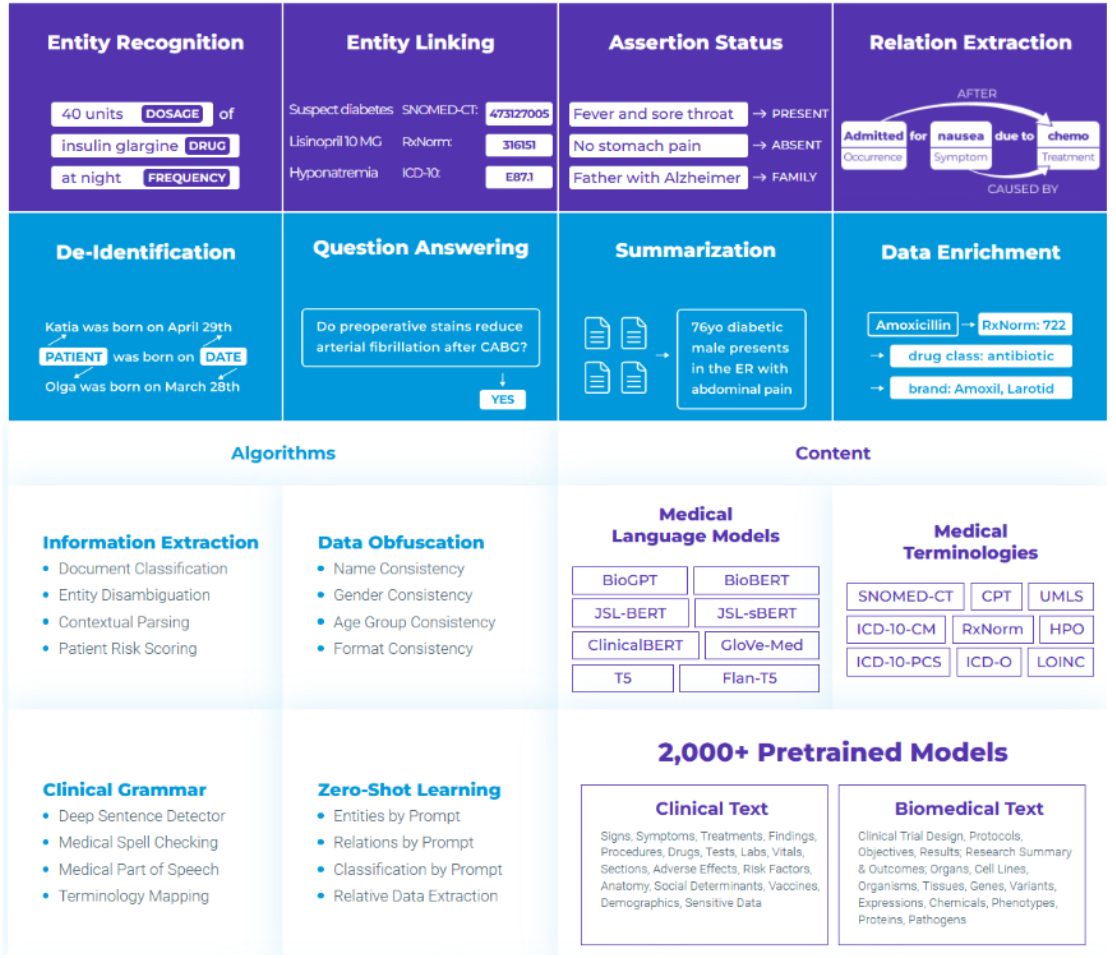

# **0. Setup and Import Libraries**

In [ ]:
import json
import os
from google.colab import files

license_keys = files.upload()

with open(list(license_keys.keys())[0]) as f:
    license_keys = json.load(f)

# Defining license key-value pairs as local variables
locals().update(license_keys)

# Adding license key-value pairs to environment variables
os.environ.update(license_keys)

In [2]:
# Installing pyspark and spark-nlp
! pip install --upgrade -q pyspark==3.5.1 spark-nlp==$PUBLIC_VERSION

# Installing Spark NLP Healthcare
! pip install --upgrade -q spark-nlp-jsl==$JSL_VERSION  --extra-index-url https://pypi.johnsnowlabs.com/$SECRET

# Spark NLP open-source visualization library
! pip -q install spark-nlp-display

In [3]:
import functools
import numpy as np
import pandas as pd
from scipy import spatial

import pyspark.sql.types as T
from pyspark.ml import Pipeline
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

import sparknlp
import sparknlp_jsl
from sparknlp.base import *
from sparknlp.annotator import *
from sparknlp_jsl.annotator import *


params = {
    "spark.driver.memory": "24G",
    "spark.driver.maxResultSize": "2G",
    "spark.kryoserializer.buffer.max": "2000M",
    "spark.default.parallelism": "1",
    "spark.sql.shuffle.partitions": "1",
}

spark = sparknlp_jsl.start(license_keys["SECRET"], params=params)

print ("Spark NLP Version :", sparknlp.version())
print ("Spark NLP_JSL Version :", sparknlp_jsl.version())

spark

Spark NLP Version : 6.4.0
Spark NLP_JSL Version : 6.4.0


# **1. Clinical Named Entity Recognition (NER)**

 The deep neural network architecture for NER model in
Spark NLP is BiLSTM-CNN-Char framework, which is a slightly modified version of the architecture proposed by Jason PC Chiu and Eric Nichols ([Named Entity Recognition with Bidirectional LSTM-CNNs
](https://arxiv.org/abs/1511.08308)). It is a neural network architecture that
automatically detects word and character-level features using a
hybrid bidirectional LSTM and CNN architecture, eliminating
the need for most feature engineering steps.


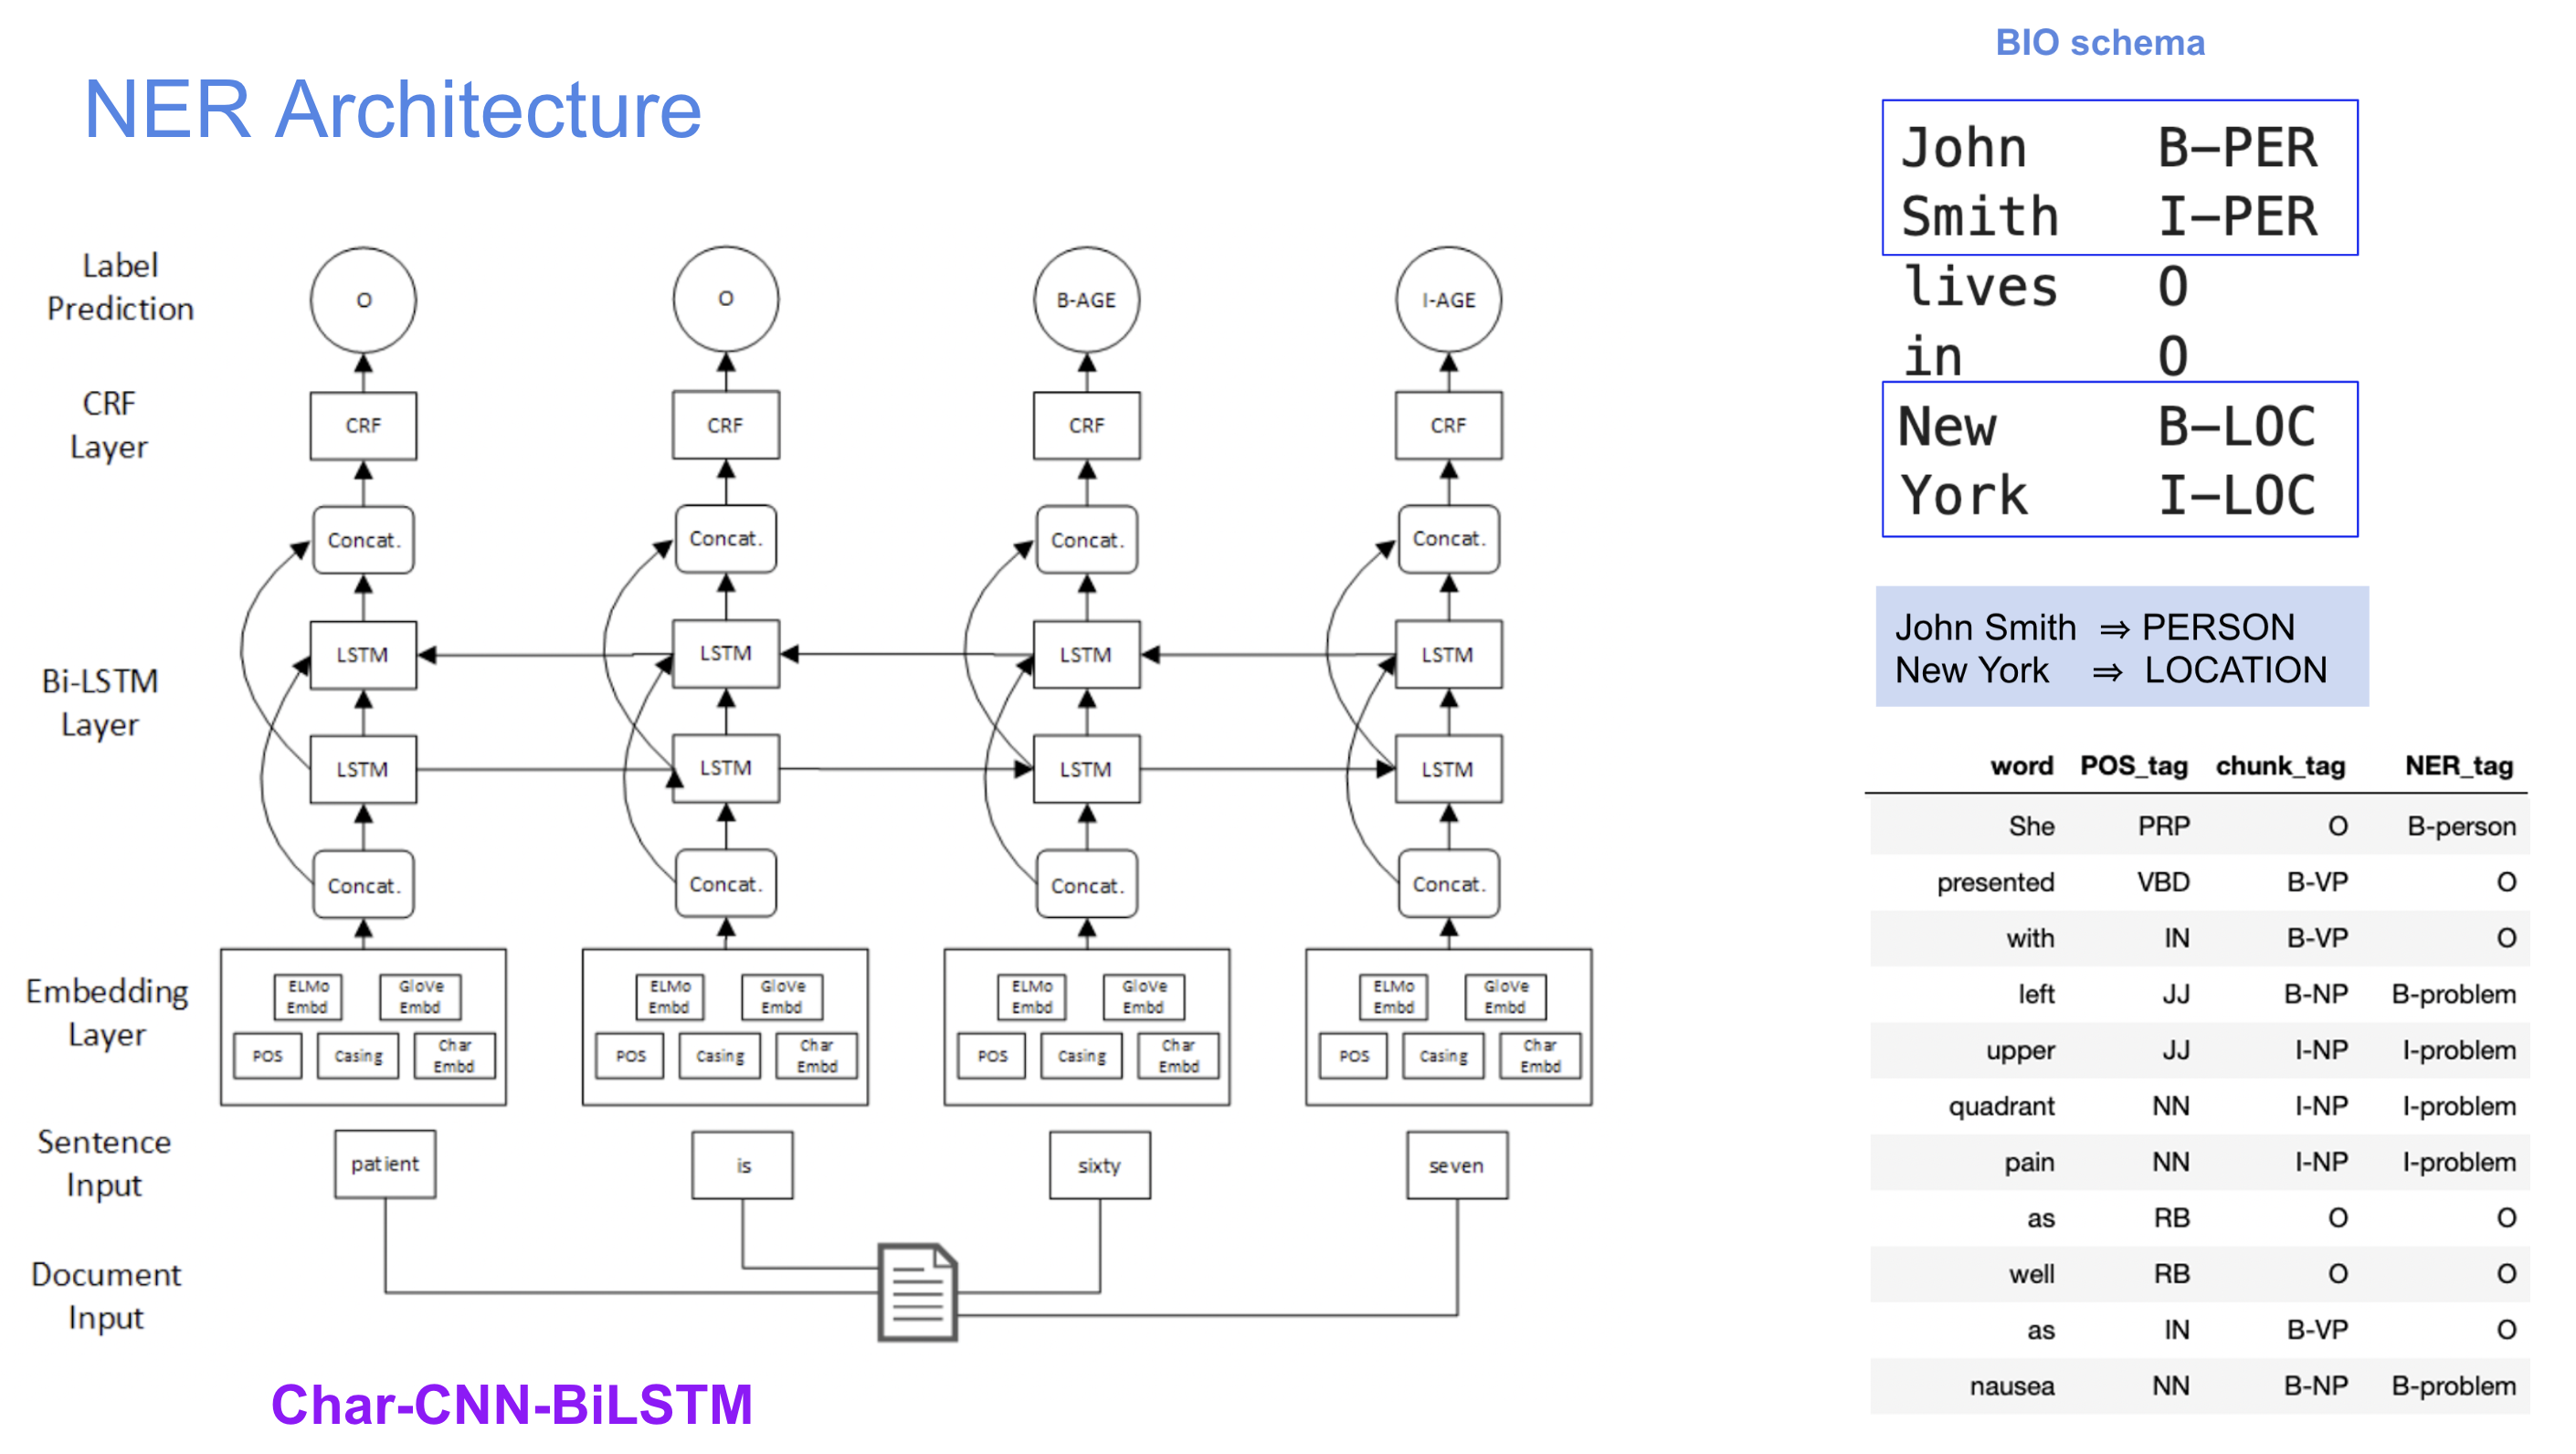

**Blogposts and videos:**

- [How to Setup Spark NLP for HEALTHCARE on UBUNTU - Video](https://www.youtube.com/watch?v=yKnF-_oz0GE)

- [Named Entity Recognition (NER) with BERT in Spark NLP](https://towardsdatascience.com/named-entity-recognition-ner-with-bert-in-spark-nlp-874df20d1d77)

- [State of the art Clinical Named Entity Recognition in Spark NLP - Youtube](https://www.youtube.com/watch?v=YM-e4eOiQ34)

- [Named Entity Recognition for Healthcare with SparkNLP NerDL and NerCRF](https://medium.com/spark-nlp/named-entity-recognition-for-healthcare-with-sparknlp-nerdl-and-nercrf-a7751b6ad571)

- [Named Entity Recognition for Clinical Text](https://medium.com/atlas-research/ner-for-clinical-text-7c73caddd180)

Let's start by creating a sample NER Pipeline.

 <br/>

In this pipeline, we will use the [**ner_jsl**](https://nlp.johnsnowlabs.com/2022/10/19/ner_jsl_en.html) pretrained model.

By using this pretrained model, we can extract about 80 clinical entities from text.

**Entities**

| | | | | |
|-|-|-|-|-|
|Injury_or_Poisoning|Direction|Test|Admission_Discharge|Death_Entity|
|Relationship_Status|Duration|Respiration|Hyperlipidemia|Birth_Entity|
|Age|Labour_Delivery|Family_History_Header|BMI|Temperature|
|Alcohol|Kidney_Disease|Oncological|Medical_History_Header|Cerebrovascular_Disease|
|Oxygen_Therapy|O2_Saturation|Psychological_Condition|Heart_Disease|Employment|
|Obesity|Disease_Syndrome_Disorder|Pregnancy|ImagingFindings|Procedure|
|Medical_Device|Race_Ethnicity|Section_Header|Symptom|Treatment|
|Substance|Route|Drug_Ingredient|Blood_Pressure|Diet|
|External_body_part_or_region|LDL|VS_Finding|Allergen|EKG_Findings|
|Imaging_Technique|Triglycerides|RelativeTime|Gender|Pulse|
|Social_History_Header|Substance_Quantity|Diabetes|Modifier|Internal_organ_or_component|
|Clinical_Dept|Form|Drug_BrandName|Strength|Fetus_NewBorn|
|RelativeDate|Height|Test_Result|Sexually_Active_or_Sexual_Orientation|Frequency|
|Time|Weight|Vaccine|Vital_Signs_Header|Communicable_Disease|
|Dosage|Overweight|Hypertension|HDL|Total_Cholesterol|
|Smoking|Date||||

In [ ]:
# Annotator that transforms a text column from dataframe into an Annotation ready for NLP
documentAssembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

sentenceDetector = SentenceDetectorDLModel.pretrained("sentence_detector_dl_healthcare","en","clinical/models")\
    .setInputCols(["document"])\
    .setOutputCol("sentence")

# Tokenizer splits words in a relevant format for NLP
tokenizer = Tokenizer()\
    .setInputCols(["sentence"])\
    .setOutputCol("token")

# Clinical word embeddings trained on PubMED dataset
word_embeddings = WordEmbeddingsModel.pretrained("embeddings_clinical","en","clinical/models")\
    .setInputCols(["sentence","token"])\
    .setOutputCol("embeddings")

# NER model trained on i2b2 (sampled from MIMIC) dataset
jsl_ner = MedicalNerModel.pretrained("ner_jsl","en","clinical/models")\
    .setInputCols(["sentence","token","embeddings"])\
    .setOutputCol("jsl_ner")\
   # .setLabelCasing("upper") #decide if we want to return the tags in upper or lower case

jsl_ner_converter = NerConverterInternal()\
    .setInputCols(["sentence","token","jsl_ner"])\
    .setOutputCol("jsl_ner_chunk")\
    #.setWhiteList(['Diabetes'])

nlpPipeline = Pipeline(stages=[
        documentAssembler,
        sentenceDetector,
        tokenizer,
        word_embeddings,
        jsl_ner,
        jsl_ner_converter])

model = nlpPipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

In [ ]:
model.stages

[DocumentAssembler_94cc566dcd6a,
 SentenceDetectorDLModel_6bafc4746ea5,
 REGEX_TOKENIZER_f7b4eaf8c6ca,
 WORD_EMBEDDINGS_MODEL_9004b1d00302,
 MedicalNerModel_c89cbceb1028,
 NER_CONVERTER_bbc6558e78c2]

Now, let's transform our pipeline with sample data and see how our NER model performs.

In [5]:
# Download sample datasets (oncology-related).
! wget -q https://raw.githubusercontent.com/JohnSnowLabs/spark-nlp-workshop/master/tutorials/Certification_Trainings/Healthcare/data/oncology_notes/mt_oncology_0.txt

In [6]:
df = spark.read.format("text").load("mt_oncology_0.txt")

df= df.withColumnRenamed("value", "text")
df.show(truncate=150)

+------------------------------------------------------------------------------------------------------------------------------------------------------+
|                                                                                                                                                  text|
+------------------------------------------------------------------------------------------------------------------------------------------------------+
|                                                                                                                      Sample Type / Medical Specialty:|
|                                                                                                                                 Hematology - Oncology|
|                                                                                                                                          Sample Name:|
|                                                                                 

In [7]:
result = model.transform(df)

result.show()

+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|                text|            document|            sentence|               token|          embeddings|             jsl_ner|       jsl_ner_chunk|
+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|Sample Type / Med...|[{document, 0, 31...|[{document, 0, 31...|[{token, 0, 5, Sa...|[{word_embeddings...|[{named_entity, 0...|                  []|
|Hematology - Onco...|[{document, 0, 20...|[{document, 0, 20...|[{token, 0, 9, He...|[{word_embeddings...|[{named_entity, 0...|[{chunk, 0, 9, He...|
|        Sample Name:|[{document, 0, 11...|[{document, 0, 11...|[{token, 0, 5, Sa...|[{word_embeddings...|[{named_entity, 0...|                  []|
|Discharge Summary...|[{document, 0, 35...|[{document, 0, 35...|[{token, 0, 8, Di...|[{word_embeddings...|

In [8]:
result_df = result.select(F.explode(F.arrays_zip(result.token.result,
                                                 result.jsl_ner.result,
                                                 result.jsl_ner.metadata)).alias("cols"))\
                  .select(F.expr("cols['0']").alias("token"),
                          F.expr("cols['1']").alias("ner_label"),
                          F.expr("cols['2']['confidence']").alias("confidence"))

result_df.show(50, truncate=100)

+-------------+---------------------------+----------+
|        token|                  ner_label|confidence|
+-------------+---------------------------+----------+
|       Sample|                          O|    0.9694|
|         Type|                          O|    0.9389|
|            /|                          O|    0.8955|
|      Medical|                          O|    0.6951|
|    Specialty|                          O|    0.7345|
|            :|                          O|    0.3654|
|   Hematology|            B-Clinical_Dept|    0.9637|
|            -|                          O|    0.9939|
|     Oncology|                          O|    0.9321|
|       Sample|                          O|    0.9933|
|         Name|                          O|    0.9411|
|            :|                          O|    0.7049|
|    Discharge|      B-Admission_Discharge|    0.9931|
|      Summary|                          O|    0.4771|
|            -|                          O|    0.8781|
| Mesothel

In [9]:
result_df.select("token", "ner_label")\
         .groupBy('ner_label').count()\
         .orderBy('count', ascending=False)\
         .show(truncate=False)

+-----------------------------+-----+
|ner_label                    |count|
+-----------------------------+-----+
|O                            |579  |
|B-Gender                     |30   |
|B-Symptom                    |28   |
|B-Disease_Syndrome_Disorder  |21   |
|B-Procedure                  |20   |
|I-Section_Header             |19   |
|I-Disease_Syndrome_Disorder  |16   |
|I-Procedure                  |16   |
|I-Symptom                    |14   |
|B-Test                       |12   |
|B-Section_Header             |11   |
|B-Direction                  |11   |
|B-Date                       |10   |
|I-Date                       |10   |
|B-Drug_BrandName             |9    |
|I-Test                       |8    |
|B-Oncological                |7    |
|B-Strength                   |7    |
|I-Strength                   |7    |
|B-Internal_organ_or_component|7    |
+-----------------------------+-----+
only showing top 20 rows



As you see above, we have labels start with **"O", "B"** and **"I"**. <br/>


**O** means that the corresponding token is not labeled as any named entity. <br/>
**B** means that the corresponding token refers to the beginning of the ner chunk while **I** means the continuation of the ner chunk.  <br/>



So, in our example, we have `deep venous thrombosis` `Disease_Syndrome_Disorder` chunk.


In this case, `deep` labeled as `B-Disease_Syndrome_Disorder` since it is the beginnig of the chunk, `venous` and `thrombosis` labeled as `I-Disease_Syndrome_Disorder` as they are the continuation of the `Disease_Syndrome_Disorder` chunk.


Now, let's check out the **chunk-based** results

In [10]:
result.select(F.explode(F.arrays_zip(result.jsl_ner_chunk.result,
                                     result.jsl_ner_chunk.metadata)).alias("cols")) \
      .select(F.expr("cols['0']").alias("chunk"),
              F.expr("cols['1']['entity']").alias("ner_label"),
              F.expr("cols['1']['confidence']").alias("confidence")).show(truncate=False)

+----------------------+-------------------------+----------+
|chunk                 |ner_label                |confidence|
+----------------------+-------------------------+----------+
|Hematology            |Clinical_Dept            |0.9637    |
|Discharge             |Admission_Discharge      |0.9931    |
|Mesothelioma          |Oncological              |0.606     |
|Description:          |Section_Header           |0.9474    |
|Mesothelioma          |Oncological              |0.9947    |
|pleural effusion      |Disease_Syndrome_Disorder|0.72175   |
|atrial fibrillation   |Heart_Disease            |0.9075    |
|anemia                |Disease_Syndrome_Disorder|0.9945    |
|ascites               |Disease_Syndrome_Disorder|0.9512    |
|esophageal reflux     |Disease_Syndrome_Disorder|0.57225   |
|deep venous thrombosis|Disease_Syndrome_Disorder|0.6532    |
|PRINCIPAL DIAGNOSIS:  |Section_Header           |0.94690007|
|Mesothelioma          |Oncological              |0.9974    |
|SECONDA

### **LightPipeline**

- Optimized for single-machine, in-memory processing.

- Faster for small to medium datasets.

- Returns a list of dictionaries or pandas DataFrame.

- Useful for real-time predictions and prototyping.

In [11]:
text = '''
28-year-old female with a history of gestational diabetes mellitus diagnosed eight years prior to presentation and subsequent type two diabetes mellitus ( T2DM )'''

print (text)

light_model = LightPipeline(model)

light_result = light_model.annotate(text)

light_result


28-year-old female with a history of gestational diabetes mellitus diagnosed eight years prior to presentation and subsequent type two diabetes mellitus ( T2DM )


{'document': ['\n28-year-old female with a history of gestational diabetes mellitus diagnosed eight years prior to presentation and subsequent type two diabetes mellitus ( T2DM )'],
 'jsl_ner_chunk': ['28-year-old',
  'female',
  'gestational diabetes mellitus',
  'eight years prior',
  'type two diabetes mellitus',
  'T2DM'],
 'jsl_ner': ['B-Age',
  'B-Gender',
  'O',
  'O',
  'O',
  'O',
  'B-Diabetes',
  'I-Diabetes',
  'I-Diabetes',
  'O',
  'B-RelativeDate',
  'I-RelativeDate',
  'I-RelativeDate',
  'O',
  'O',
  'O',
  'O',
  'B-Diabetes',
  'I-Diabetes',
  'I-Diabetes',
  'I-Diabetes',
  'O',
  'B-Diabetes',
  'O'],
 'token': ['28-year-old',
  'female',
  'with',
  'a',
  'history',
  'of',
  'gestational',
  'diabetes',
  'mellitus',
  'diagnosed',
  'eight',
  'years',
  'prior',
  'to',
  'presentation',
  'and',
  'subsequent',
  'type',
  'two',
  'diabetes',
  'mellitus',
  '(',
  'T2DM',
  ')'],
 'embeddings': ['28-year-old',
  'female',
  'with',
  'a',
  'history',
  'o

Using **.annotate** to get predictions

- Provides a **simplified output** with just the annotated results.

- Returns a dictionary where the keys are the names of the output columns (as defined in the pipeline) and the values are lists of strings containing the annotations.

- Useful when you only need the final results of the annotation **without any additional metadata**.

In [12]:
light_result.keys()

dict_keys(['document', 'jsl_ner_chunk', 'jsl_ner', 'token', 'embeddings', 'sentence'])

In [13]:
list(zip(light_result['token'], light_result['jsl_ner']))

[('28-year-old', 'B-Age'),
 ('female', 'B-Gender'),
 ('with', 'O'),
 ('a', 'O'),
 ('history', 'O'),
 ('of', 'O'),
 ('gestational', 'B-Diabetes'),
 ('diabetes', 'I-Diabetes'),
 ('mellitus', 'I-Diabetes'),
 ('diagnosed', 'O'),
 ('eight', 'B-RelativeDate'),
 ('years', 'I-RelativeDate'),
 ('prior', 'I-RelativeDate'),
 ('to', 'O'),
 ('presentation', 'O'),
 ('and', 'O'),
 ('subsequent', 'O'),
 ('type', 'B-Diabetes'),
 ('two', 'I-Diabetes'),
 ('diabetes', 'I-Diabetes'),
 ('mellitus', 'I-Diabetes'),
 ('(', 'O'),
 ('T2DM', 'B-Diabetes'),
 (')', 'O')]

Using **.fullAnnotate** to get more details

- Provides more **comprehensive output**, including both the annotations and the metadata for each token.

- Returns a list of dictionaries, where each dictionary contains **detailed information** about the annotations, including the tokens, entities, and other metadata such as the start and end positions of tokens.

- Useful when you need detailed information about the annotations, such as the positions of tokens in the original text, confidence scores, and other **metadata**.

In [14]:
text = '''
28-year-old female with a history of gestational diabetes mellitus diagnosed eight years prior to presentation and subsequent type two diabetes mellitus ( T2DM ), one prior episode of HTG-induced pancreatitis three years prior to presentation , and associated with an acute hepatitis , presented with a one-week history of polyuria , poor appetite , and vomiting .
She was on metformin , glipizide , and dapagliflozin for T2DM and atorvastatin and gemfibrozil for HTG . She had been on dapagliflozin for six months at the time of presentation .
Physical examination on presentation was significant for dry oral mucosa ; significantly , her abdominal examination was benign with no tenderness , guarding , or rigidity . Pertinent laboratory findings on admission were : serum glucose 111 mg/dl ,  creatinine 0.4 mg/dL , triglycerides 508 mg/dL , total cholesterol 122 mg/dL , and venous pH 7.27 .
'''

light_result_full = light_model.fullAnnotate(text)

In [15]:
light_result_full

[{'document': [Annotation(document, 0, 896, 
   28-year-old female with a history of gestational diabetes mellitus diagnosed eight years prior to presentation and subsequent type two diabetes mellitus ( T2DM ), one prior episode of HTG-induced pancreatitis three years prior to presentation , and associated with an acute hepatitis , presented with a one-week history of polyuria , poor appetite , and vomiting .
   She was on metformin , glipizide , and dapagliflozin for T2DM and atorvastatin and gemfibrozil for HTG . She had been on dapagliflozin for six months at the time of presentation .
   Physical examination on presentation was significant for dry oral mucosa ; significantly , her abdominal examination was benign with no tenderness , guarding , or rigidity . Pertinent laboratory findings on admission were : serum glucose 111 mg/dl ,  creatinine 0.4 mg/dL , triglycerides 508 mg/dL , total cholesterol 122 mg/dL , and venous pH 7.27 .
   , {'sentence': '0'}, [])],
  'jsl_ner_chunk': [

In [16]:
chunks = []
entities = []
sentence= []
begin = []
end = []

for n in light_result_full[0]['jsl_ner_chunk']:

    begin.append(n.begin)
    end.append(n.end)
    chunks.append(n.result)
    entities.append(n.metadata['entity'])
    sentence.append(n.metadata['sentence'])


import pandas as pd

df_clinical = pd.DataFrame({'chunks':chunks, 'begin': begin, 'end':end,
                   'sentence_id':sentence, 'entities':entities})

df_clinical

,chunks,begin,end,sentence_id,entities
0,28-year-old,1,11,0,Age
1,female,13,18,0,Gender
2,gestational diabetes mellitus,38,66,0,Diabetes
3,eight years prior,78,94,0,RelativeDate
4,type two diabetes mellitus,127,152,0,Diabetes
5,T2DM,156,159,0,Diabetes
6,HTG-induced pancreatitis,185,208,0,Disease_Syndrome_Disorder
7,three years prior,210,226,0,RelativeDate
8,acute,269,273,0,Modifier
9,hepatitis,275,283,0,Disease_Syndrome_Disorder


### **NER Visualizer**

[**NerVisualizer**](https://sparknlp.org/docs/en/display) highlights the named entities that are identified by Spark NLP and also displays their labels as decorations on top of the analyzed text.

In [17]:
from sparknlp_display import NerVisualizer

visualiser = NerVisualizer()

visualiser.display(light_result_full[0], label_col='jsl_ner_chunk', document_col='document', save_path="display_result.html")

# Set label filter
#visualiser.display(light_result_full[0], label_col='jsl_ner_chunk', document_col='document', labels=['Symptom','Drug_Ingredient'])

## **Clinical NER Chunk Merger**

Sparknlp has the ability to merge the chunks that come from different annotators (NER, ContextualParser or any other annotator producing chunks) through the **`ChunkMergeApproach()`** annotator.  

The decision on which chunk to select is made according to the chunk indices in the source document. (chunks with longer lengths and highest information will be kept from each source).


Let's create a sample pipeline consisting of `ner_clinical`, `ner_posology` and `ner_deid_generic_augmented` models, and merge the outputs of these models.

In [ ]:
documentAssembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

sentenceDetector = SentenceDetector()\
    .setInputCols(["document"])\
    .setOutputCol("sentence")

tokenizer = Tokenizer()\
    .setInputCols(["sentence"])\
    .setOutputCol("token")

word_embeddings = WordEmbeddingsModel.pretrained("embeddings_clinical", "en", "clinical/models")\
    .setInputCols(["sentence", "token"])\
    .setOutputCol("embeddings")

deid_ner = MedicalNerModel.pretrained("ner_deid_generic_augmented", "en", "clinical/models") \
    .setInputCols(["sentence", "token", "embeddings"]) \
    .setOutputCol("deid_ner")

deid_ner_converter = NerConverterInternal() \
    .setInputCols(["sentence", "token", "deid_ner"]) \
    .setOutputCol("deid_ner_chunk")\
    .setWhiteList(["AGE", "DATE", "LOCATION"]) # only AGE, DATE and LOCATION entities

clinical_ner = MedicalNerModel.pretrained("ner_clinical", "en", "clinical/models") \
    .setInputCols(["sentence", "token", "embeddings"]) \
    .setOutputCol("clinical_ner")

clinical_ner_converter = NerConverterInternal() \
    .setInputCols(["sentence", "token", "clinical_ner"]) \
    .setOutputCol("clinical_ner_chunk")\
    .setBlackList(["TREATMENT"]) # blocks TREATMENT entities

# NER model to detect medication entities (Drug, Dosage, Frequency etc.))
posology_ner = MedicalNerModel.pretrained("ner_posology", "en", "clinical/models") \
    .setInputCols(["sentence", "token", "embeddings"]) \
    .setOutputCol("posology_ner")

posology_ner_converter = NerConverterInternal() \
    .setInputCols(["sentence", "token", "posology_ner"]) \
    .setOutputCol("posology_ner_chunk")

# merge ner_chunks by prioritizing the overlapping indices
chunk_merger = ChunkMergeApproach()\
    .setInputCols('deid_ner_chunk', "clinical_ner_chunk", "posology_ner_chunk")\
    .setOutputCol('merged_ner_chunk')

nlpPipeline = Pipeline(stages=[
    documentAssembler,
    sentenceDetector,
    tokenizer,
    word_embeddings,
    deid_ner,
    deid_ner_converter,
    clinical_ner,
    clinical_ner_converter,
    posology_ner,
    posology_ner_converter,
    chunk_merger])

empty_data = spark.createDataFrame([[""]]).toDF("text")

model = nlpPipeline.fit(empty_data)

In [20]:
text = """HISTORY AND PHYSICAL: The patient is from Vietnam, 41-year-old female with a nonproductive cough that started on Sep 2006.
          She has had right-sided chest pain radiating to her back with fever starting on November 5, 2006.
          She has a history of pericarditis and pericardectomy in May 2006 and developed cough with right-sided chest pain, and went to an urgent care center. Chest x-ray revealed right-sided pleural effusion.
          MEDICATIONS: Coumadin 1 mg daily. Last INR was on Tuesday, August 14, 2007, and INR was 2.3. Amiodarone 100 mg p.o. daily.
       """

spark_df = spark.createDataFrame([[text]]).toDF("text")

merged_data = model.transform(spark_df)

%time merged_data.show()

+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|                text|            document|            sentence|               token|          embeddings|            deid_ner|      deid_ner_chunk|        clinical_ner|  clinical_ner_chunk|        posology_ner|  posology_ner_chunk|    merged_ner_chunk|
+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|HISTORY AND PHYSI...|[{document, 0, 58...|[{document, 0, 12...|[{token, 0, 6, HI...|[{word_embeddings...|[{named_entity, 0...|[{chunk, 42, 48, ...|[{named_entity, 0...|[{chunk, 75, 95, ...|[{named_entity, 0...|[{chunk, 464, 471...|[{chun

In [21]:
lp_model = LightPipeline(model)

%time lp_result = lp_model.annotate(text)

CPU times: user 108 ms, sys: 73.5 ms, total: 182 ms
Wall time: 1.12 s


In [22]:
result_df = merged_data.select(F.explode('merged_ner_chunk').alias("cols")) \
                       .select(F.expr("cols.begin").alias("begin"),
                               F.expr("cols.end").alias("end"),
                               F.expr("cols.result").alias("chunk"),
                               F.expr("cols.metadata.entity").alias("entity"))

result_df.show(50, truncate=100)

+-----+---+----------------------------+---------+
|begin|end|                       chunk|   entity|
+-----+---+----------------------------+---------+
|   42| 48|                     Vietnam| LOCATION|
|   51| 61|                 41-year-old|      AGE|
|   75| 95|       a nonproductive cough|  PROBLEM|
|  113|120|                    Sep 2006|     DATE|
|  145|166|      right-sided chest pain|  PROBLEM|
|  195|199|                       fever|  PROBLEM|
|  213|228|            November 5, 2006|     DATE|
|  262|273|                pericarditis|  PROBLEM|
|  297|304|                    May 2006|     DATE|
|  320|324|                       cough|  PROBLEM|
|  331|352|      right-sided chest pain|  PROBLEM|
|  390|400|                 Chest x-ray|     TEST|
|  411|438|right-sided pleural effusion|  PROBLEM|
|  464|471|                    Coumadin|     DRUG|
|  473|476|                        1 mg| STRENGTH|
|  478|482|                       daily|FREQUENCY|
|  490|492|                    

## **Zero-Shot NER**

In [ ]:
documentAssembler = DocumentAssembler() \
    .setInputCol("text") \
    .setOutputCol("document")

sentenceDetector = SentenceDetector() \
    .setInputCols(["document"]) \
    .setOutputCol("sentence")

tokenizer = Tokenizer() \
    .setInputCols(["sentence"]) \
    .setOutputCol("token")

zero_shot_ner = ZeroShotNerModel.pretrained("zero_shot_ner_roberta", "en", "clinical/models")\
    .setEntityDefinitions(
        {   "PROBLEM": ["What is the disease?", "What is his symptom?", "What is her disease?", "What is his disease?",
                        "What is the problem?" ,"What does a patient suffer", 'What was the reason that the patient is admitted to the clinic?'],
            "DRUG": ["Which drug?", "Which is the drug?", "What is the drug?", "Which drug does he use?", "Which drug does she use?", "Which drug do I use?", "Which drug is prescribed for a symptom?"],
            "ADMISSION_DATE": ["When did patient admitted to a clinic?"],
            "PATIENT_AGE": ["How old is the patient?",'What is the gae of the patient?']
        })\
    .setInputCols(["sentence", "token"])\
    .setOutputCol("zero_shot_ner")\
    .setPredictionThreshold(0.1) # default 0.01

ner_converter = NerConverterInternal()\
    .setInputCols(["sentence", "token", "zero_shot_ner"])\
    .setOutputCol("ner_chunk")\
    .setThreshold()

pipeline = Pipeline(stages = [
    documentAssembler,
    sentenceDetector,
    tokenizer,
    zero_shot_ner,
    ner_converter])

zero_shot_ner_model = pipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

In [24]:
text_list = ["The doctor pescribed Majezik for my severe headache.",
             "The patient was admitted to the hospital for his colon cancer.",
             "27 years old patient was admitted to clinic on Sep 1st by Dr. X for a right-sided pleural effusion for thoracentesis."
            ]

from pyspark.sql.types import StringType
data = spark.createDataFrame(text_list, StringType()).toDF("text")

results = zero_shot_ner_model.transform(data)

In [25]:
results.select(F.explode(F.arrays_zip(results.token.result,
                                      results.zero_shot_ner.result,
                                      results.zero_shot_ner.metadata,
                                      results.zero_shot_ner.begin,
                                      results.zero_shot_ner.end)).alias("cols"))\
       .select(F.expr("cols['0']").alias("token"),
               F.expr("cols['1']").alias("ner_label"),
               F.expr("cols['2']['sentence']").alias("sentence"),
               F.expr("cols['3']").alias("begin"),
               F.expr("cols['4']").alias("end"),
               F.expr("cols['2']['confidence']").alias("confidence")).show(50, truncate=100)

+-------------+----------------+--------+-----+---+----------+
|        token|       ner_label|sentence|begin|end|confidence|
+-------------+----------------+--------+-----+---+----------+
|          The|               O|       0|    0|  2|      NULL|
|       doctor|               O|       0|    4|  9|      NULL|
|    pescribed|               O|       0|   11| 19|      NULL|
|      Majezik|          B-DRUG|       0|   21| 27| 0.7762679|
|          for|               O|       0|   29| 31|      NULL|
|           my|               O|       0|   33| 34|      NULL|
|       severe|       B-PROBLEM|       0|   36| 41|0.62934923|
|     headache|       I-PROBLEM|       0|   43| 50|0.62934923|
|            .|               O|       0|   51| 51|      NULL|
|          The|               O|       0|    0|  2|      NULL|
|      patient|               O|       0|    4| 10|      NULL|
|          was|               O|       0|   12| 14|      NULL|
|     admitted|               O|       0|   16| 23|    

In [26]:
results.select(F.explode(F.arrays_zip(results.ner_chunk.result,
                                      results.ner_chunk.metadata)).alias("cols"))\
       .select(F.expr("cols['0']").alias("chunk"),
               F.expr("cols['1']['entity']").alias("ner_label"),
               F.expr("cols['1']['confidence']").alias("confidence")).show(50, truncate=100)

+----------------------------------------------+--------------+----------+
|                                         chunk|     ner_label|confidence|
+----------------------------------------------+--------------+----------+
|                                       Majezik|          DRUG| 0.7762679|
|                               severe headache|       PROBLEM|0.62934923|
|                                  colon cancer|       PROBLEM|0.95100486|
|                                      27 years|   PATIENT_AGE|0.68755436|
|                                       Sep 1st|ADMISSION_DATE|0.97880006|
|right-sided pleural effusion for thoracentesis|       PROBLEM| 0.6037374|
+----------------------------------------------+--------------+----------+



In [27]:
light_model = LightPipeline(zero_shot_ner_model)

from sparknlp_display import NerVisualizer

visualiser = NerVisualizer()

for i in text_list:

    light_result = light_model.fullAnnotate(i)
    visualiser.display(light_result[0], label_col='ner_chunk', document_col='document')

## **BertForTokenClassification**

In [ ]:
documentAssembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

sentenceDetector = SentenceDetectorDLModel.pretrained("sentence_detector_dl_healthcare","en","clinical/models")\
    .setInputCols(["document"])\
    .setOutputCol("sentence")

tokenizer = Tokenizer()\
    .setInputCols("sentence")\
    .setOutputCol("token")

tokenClassifier = MedicalBertForTokenClassifier.pretrained("bert_token_classifier_ner_clinical", "en", "clinical/models")\
    .setInputCols("token", "sentence")\
    .setOutputCol("ner")\
    .setCaseSensitive(True)

ner_converter = NerConverterInternal()\
    .setInputCols(["sentence","token","ner"])\
    .setOutputCol("ner_chunk")

pipeline =  Pipeline(stages=[
    documentAssembler,
    sentenceDetector,
    tokenizer,
    tokenClassifier,
    ner_converter
    ])

model = pipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

text = """A 28-year-old female with a history of gestational diabetes mellitus diagnosed eight years prior to presentation and subsequent type two diabetes mellitus T2DM, one prior episode of HTG-induced pancreatitis three years prior to presentation , associated with an acute hepatitis , and obesity with a body mass index ( BMI ) of 33.5 kg/m2 , presented with a one-week history of polyuria , polydipsia , poor appetite , and vomiting .
Two weeks prior to presentation , she was treated with a five-day course of amoxicillin for a respiratory tract infection .
She was on metformin , glipizide , and dapagliflozin for T2DM and atorvastatin and gemfibrozil for HTG . She had been on dapagliflozin for six months at the time of presentation .
Physical examination on presentation was significant for dry oral mucosa ; significantly , her abdominal examination was benign with no tenderness , guarding , or rigidity .
Pertinent laboratory findings on admission were : serum glucose 111 mg/dl , bicarbonate 18 mmol/l , anion gap 20 , creatinine 0.4 mg/dL , triglycerides 508 mg/dL , total cholesterol 122 mg/dL , glycated hemoglobin ( HbA1c ) 10% , and venous pH 7.27 .
Serum lipase was normal at 43 U/L . Serum acetone levels could not be assessed as blood samples kept hemolyzing due to significant lipemia .
The patient was initially admitted for starvation ketosis , as she reported poor oral intake for three days prior to admission .
However , serum chemistry obtained six hours after presentation revealed her glucose was 186 mg/dL , the anion gap was still elevated at 21 , serum bicarbonate was 16 mmol/L , triglyceride level peaked at 2050 mg/dL , and lipase was 52 U/L .
The β-hydroxybutyrate level was obtained and found to be elevated at 5.29 mmol/L - the original sample was centrifuged and the chylomicron layer removed prior to analysis due to interference from turbidity caused by lipemia again .
The patient was treated with an insulin drip for euDKA and HTG with a reduction in the anion gap to 13 and triglycerides to 1400 mg/dL , within 24 hours .
Her euDKA was thought to be precipitated by her respiratory tract infection in the setting of SGLT2 inhibitor use .
The patient was seen by the endocrinology service and she was discharged on 40 units of insulin glargine at night , 12 units of insulin lispro with meals , and metformin 1000 mg two times a day .
It was determined that all SGLT2 inhibitors should be discontinued indefinitely . She had close follow-up with endocrinology post discharge ."""

res = model.transform(spark.createDataFrame([[text]]).toDF("text"))

In [35]:
from pyspark.sql import functions as F

res.select(F.explode(F.arrays_zip(res.ner_chunk.result,
                                  res.ner_chunk.begin,
                                  res.ner_chunk.end,
                                  res.ner_chunk.metadata)).alias("cols")) \
   .select(F.expr("cols['3']['sentence']").alias("sentence_id"),
           F.expr("cols['0']").alias("chunk"),
           F.expr("cols['1']").alias("begin"),
           F.expr("cols['2']").alias("end"),
           F.expr("cols['3']['entity']").alias("ner_label"))\
   .filter("ner_label!='O'")\
   .show(truncate=False)

+-----------+-----------------------------+-----+---+---------+
|sentence_id|chunk                        |begin|end|ner_label|
+-----------+-----------------------------+-----+---+---------+
|0          |gestational diabetes mellitus|39   |67 |PROBLEM  |
|0          |type two diabetes mellitus   |128  |153|PROBLEM  |
|0          |T2DM                         |155  |158|PROBLEM  |
|0          |HTG-induced pancreatitis     |182  |205|PROBLEM  |
|0          |an acute hepatitis           |259  |276|PROBLEM  |
|0          |obesity                      |284  |290|PROBLEM  |
|0          |a body mass index            |297  |313|TEST     |
|0          |BMI                          |317  |319|TEST     |
|0          |polyuria                     |376  |383|PROBLEM  |
|0          |polydipsia                   |387  |396|PROBLEM  |
|0          |poor appetite                |400  |412|PROBLEM  |
|0          |vomiting                     |420  |427|PROBLEM  |
|1          |amoxicillin                

In [36]:
light_model = LightPipeline(model)

light_result = light_model.fullAnnotate(text)

from sparknlp_display import NerVisualizer

visualiser = NerVisualizer()

visualiser.display(light_result[0], label_col='ner_chunk', document_col='document', save_path="display_bert_result.html")

## **NER Model Training**

To train a new NER model from scratch, please check out:

https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Healthcare/1.Clinical_Named_Entity_Recognition_Model.ipynb

## **Pretrained NER Profiling Pipelines**

We can use pretrained NER profiling pipelines for exploring all the available pretrained NER models at once. In Spark NLP we have two different NER profiling pipelines;

- `ner_profiling_clinical` : Returns results for clinical NER models trained with `embeddings_clinical`.
- `ner_profiling_biobert` : Returns results for clinical NER models trained with `biobert_pubmed_base_cased`.

For more examples, please check this [**notebook**](https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Healthcare/11.2.Pretrained_NER_Profiling_Pipelines.ipynb).





In [ ]:
from sparknlp.pretrained import PretrainedPipeline

clinical_profiling_pipeline = PretrainedPipeline("ner_profiling_clinical", "en", "clinical/models")

In [38]:
#sample text for ner profiling

text = '''28-year-old female with a history of gestational diabetes mellitus, prior episode of HTG-induced pancreatitis.'''

In [39]:
clinical_result = clinical_profiling_pipeline.fullAnnotate(text)[0]

In [40]:
def get_token_results(light_result):

  tokens = [j.result for j in light_result["token"]]
  sentences = [j.metadata["sentence"] for j in light_result["token"]]
  begins = [j.begin for j in light_result["token"]]
  ends = [j.end for j in light_result["token"]]
  model_list = [ a for a in light_result.keys() if (a not in ["sentence", "token"] and "_chunks" not in a)]

  df = pd.DataFrame({'sentence':sentences, 'begin': begins, 'end': ends, 'token':tokens})

  for model_name in model_list:

    temp_df = pd.DataFrame(light_result[model_name])
    temp_df["jsl_label"] = temp_df.iloc[:,0].apply(lambda x : x.result)
    temp_df = temp_df[["jsl_label"]]

    # temp_df = get_ner_result(model_name)
    temp_df.columns = [model_name]
    df = pd.concat([df, temp_df], axis=1)

  return df

In [41]:
get_token_results(clinical_result)

,sentence,begin,end,token,ner_oncology_tnm_langtest,ner_deid_augmented,ner_deid_subentity_augmented_i2b2,ner_vop_clinical_dept_langtest,ner_risk_factors_langtest,ner_radiology_wip_clinical,...,ner_clinical_langtest,ner_oncology_unspecific_posology,ner_genetic_variants,ner_radiology,ner_eu_clinical_case,ner_posology,ner_oncology_posology,ner_covid_trials,ner_vop_problem_reduced_langtest,ner_posology_langtest
0,0,0,10,28-year-old,O,O,O,O,O,O,...,O,O,O,O,B-patient,O,O,B-Gender,O,O
1,0,12,17,female,O,O,O,O,O,O,...,O,O,O,O,I-patient,O,O,B-Gender,O,O
2,0,19,22,with,O,O,O,O,O,O,...,O,O,O,O,O,O,O,O,O,O
3,0,24,24,a,O,O,O,O,O,O,...,O,O,O,O,O,O,O,O,O,O
4,0,26,32,history,O,O,O,O,O,O,...,O,O,O,O,B-clinical_event,O,O,O,O,O
5,0,34,35,of,O,O,O,O,O,O,...,O,O,O,O,O,O,O,O,O,O
6,0,37,47,gestational,O,O,O,O,B-DIABETES,B-Disease_Syndrome_Disorder,...,B-PROBLEM,O,O,B-Disease_Syndrome_Disorder,B-clinical_condition,O,O,B-Diabetes,B-Problem,O
7,0,49,56,diabetes,O,O,O,O,I-DIABETES,I-Disease_Syndrome_Disorder,...,I-PROBLEM,O,O,I-Disease_Syndrome_Disorder,I-clinical_condition,O,O,I-Diabetes,I-Problem,O
8,0,58,65,mellitus,O,O,O,O,I-DIABETES,I-Disease_Syndrome_Disorder,...,I-PROBLEM,O,O,I-Disease_Syndrome_Disorder,I-clinical_condition,O,O,I-Diabetes,I-Problem,O
9,0,66,66,",",O,O,O,O,O,O,...,O,O,O,O,O,O,O,O,O,O


# **2. Rule Based NER**

## **Contextual Parser**

Spark NLP's `ContextualParser` (**CP**) is a licensed annotator that allows users to extract entities from a document based on **pattern matching**.


CP will help find entities using regex rules for full and partial matches, by defining a dictionary with normalizing options and context parameters to take into account things such as token distances.



For more details about the components (parameters, JSON and dictionary), please visit [**this notebook**](https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Healthcare/1.2.Contextual_Parser_Rule_Based_NER.ipynb).

Start by generating a dictionary and a json file to build a sample `ContextualParser` pipeline to detect "gender" and "age" from given text. Then merge their results with NER model's results.


In [42]:
sample_text = """The patient is a 28 years old female with a history of gestational diabetes mellitus was diagnosed in April 2002 in County Baptist Hospital .
                 3 years ago, he reported an episode of HTG-induced pancreatitis .
                 5 months old boy with repeated concussions."""

In [43]:
# Create a dictionary to detect gender
gender = '''male,man,male,boy,gentleman,he,him
female,woman,female,girl,lady,old-lady,she,her
neutral,they,neutral,it'''

with open('gender.csv', 'w') as f:
    f.write(gender)

# Check what dictionary looks like
!cat gender.csv

male,man,male,boy,gentleman,he,him
female,woman,female,girl,lady,old-lady,she,her
neutral,they,neutral,it

In [44]:
# Create JSON file for gender
gender = {
  "entity": "Gender",
  "ruleScope": "sentence",
  "completeMatchRegex": "true",
  "matchScope":"token"
}

import json
with open('gender.json', 'w') as f:
    json.dump(gender, f)

In [45]:
#Create JSON file for age
age = {
  "entity": "Age",
  "ruleScope": "sentence",
  "matchScope":"token",
  "regex":"\\d{1,3}",
  "prefix":["age of", "age"],
  "suffix": ["-years-old", "years-old", "-year-old",
             "-months-old", "-month-old", "-months-old",
             "-day-old", "-days-old", "month old",
             "days old", "year old", "years old",
             "years", "year", "months", "old"],
  "contextLength": 25,
  "contextException": ["ago"],
  "exceptionDistance": 12
}

with open('age.json', 'w') as f:
    json.dump(age, f)

In [ ]:
document_assembler = DocumentAssembler() \
    .setInputCol("text") \
    .setOutputCol("document")

sentence_detector = SentenceDetector() \
    .setInputCols(["document"]) \
    .setOutputCol("sentence")

tokenizer = Tokenizer() \
    .setInputCols(["sentence"]) \
    .setOutputCol("token")

gender_contextual_parser = ContextualParserApproach() \
    .setInputCols(["sentence", "token"]) \
    .setOutputCol("gender_chunk") \
    .setJsonPath("gender.json") \
    .setCaseSensitive(False) \
    .setDictionary('gender.csv', options={"delimiter":","}) \
    .setPrefixAndSuffixMatch(False)

age_contextual_parser = ContextualParserApproach() \
    .setInputCols(["sentence", "token"]) \
    .setOutputCol("age_chunk") \
    .setJsonPath("age.json") \
    .setCaseSensitive(False) \
    .setPrefixAndSuffixMatch(False) \
    .setOptionalContextRules(False) \
    .setShortestContextMatch(True)

word_embeddings = WordEmbeddingsModel.pretrained("embeddings_clinical", "en", "clinical/models")\
    .setInputCols(["sentence", "token"])\
    .setOutputCol("embeddings")

deid_ner = MedicalNerModel.pretrained("ner_deid_generic_augmented", "en", "clinical/models") \
    .setInputCols(["sentence", "token", "embeddings"]) \
    .setOutputCol("deid_ner")

deid_ner_converter = NerConverterInternal() \
    .setInputCols(["sentence", "token", "deid_ner"]) \
    .setOutputCol("deid_ner_chunk")\
    .setWhiteList(["DATE", "LOCATION"])

# merge CP and NER model chunks
chunk_merger = ChunkMergeApproach() \
    .setInputCols(["gender_chunk", "age_chunk", "deid_ner_chunk"]) \
    .setOutputCol("ner_chunk")

parserPipeline = Pipeline(stages=[
        document_assembler,
        sentence_detector,
        tokenizer,
        gender_contextual_parser,
        age_contextual_parser,
        word_embeddings,
        deid_ner,
        deid_ner_converter,
        chunk_merger
        ])

parserModel = parserPipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

light_model = LightPipeline(parserModel)

In the metadata, **`ner_source`** is for showing the source of the entities.

In [47]:
annotations = light_model.fullAnnotate(sample_text)[0]

annotations.get('ner_chunk')

[Annotation(chunk, 17, 18, 28, {'tokenIndex': '4', 'entity': 'Age', 'confidence': '0.74', 'field': 'Age', 'ner_source': 'age_chunk', 'chunk': '0', 'normalized': '', 'sentence': '0'}, []),
 Annotation(chunk, 30, 35, female, {'tokenIndex': '7', 'entity': 'Gender', 'confidence': '0.50', 'field': 'Gender', 'ner_source': 'gender_chunk', 'chunk': '1', 'normalized': 'female', 'sentence': '0'}, []),
 Annotation(chunk, 102, 111, April 2002, {'entity': 'DATE', 'confidence': '0.99950004', 'ner_source': 'deid_ner_chunk', 'chunk': '2', 'sentence': '0'}, []),
 Annotation(chunk, 116, 138, County Baptist Hospital, {'entity': 'LOCATION', 'confidence': '0.97850007', 'ner_source': 'deid_ner_chunk', 'chunk': '3', 'sentence': '0'}, []),
 Annotation(chunk, 172, 173, he, {'tokenIndex': '4', 'entity': 'Gender', 'confidence': '0.50', 'field': 'Gender', 'ner_source': 'gender_chunk', 'chunk': '4', 'normalized': 'male', 'sentence': '1'}, []),
 Annotation(chunk, 242, 242, 5, {'tokenIndex': '0', 'entity': 'Age', 'c

In [48]:
visualiser = NerVisualizer()

visualiser.display(annotations, label_col='ner_chunk', document_col='document', save_path="display_result.html")

## **Regex Matcher**

**`RegexMatcherInternal`** class implements an internal annotator approach to match a set of regular expressions with a provided entity. This approach is utilized for associating **specific patterns** within text data with predetermined entities, such as dates, mentioned within the text.

The class allows users to define rules using regular expressions paired with entities, offering flexibility in customization. These rules can either be directly set using the setRules method, with a specified delimiter, or loaded from an external file using the setExternalRules method.

Additionally, users can specify parameters such as the matching strategy (MATCH_FIRST, MATCH_ALL, or MATCH_COMPLETE) to control how matches are handled. The output annotation type is CHUNK, with input annotation types supporting DOCUMENT. This class provides a versatile tool for implementing entity recognition based on user-defined patterns within text data.

A rule consists of a regex pattern and an identifier, delimited by a character of choice. An example could be "\\d{4}\\/\\d\\d\\/\\d\\d,date" which will match strings like "1970/01/01" to the identifier "date".

For more details please see [**Rule_Based_Entity_Matchers**](https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Healthcare/40.Rule_Based_Entity_Matchers.ipynb) notebook.

**IP** and **DATE**

In [49]:
text = """Name : Hendrickson, Ora, Record date: 2093-01-13, MR #719435.
Dr. John Green, ID: 1231511863, IP 203.120.223.13
He is a 60-year-old male was admitted to the Day Hospital for cystectomy on 01/13/93
Patient's VIN : 1HGBH41JXMN109286, SSN #333-44-6666, Driver's license no: A334455B.
Phone (302) 786-5227, 0295 Keats Street, San Francisco, E-MAIL: smith@gmail.com."""

data = spark.createDataFrame([[text]]).toDF("text")

In [51]:
!mkdir -p rules

rules = r'''
(\d{1,3}\.){3}\d{1,3}~IPADDR
\d{4}-\d{2}-\d{2}|\d{2}/\d{2}/\d{2}~DATE
'''

with open('./rules/regex_rules.txt', 'w') as f:
    f.write(rules)

In [52]:
document_assembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

regex_matcher = RegexMatcherInternal()\
    .setInputCols('document')\
    .setStrategy("MATCH_ALL")\
    .setOutputCol("regex_matches")\
    .setExternalRules(path='./rules/regex_rules.txt', delimiter='~')

nlpPipeline = Pipeline(
    stages=[
        document_assembler,
        regex_matcher
])

result = nlpPipeline.fit(data).transform(data)

In [53]:
result.select('regex_matches.result','regex_matches.metadata').show(truncate=70)

+--------------------------------------+----------------------------------------------------------------------+
|                                result|                                                              metadata|
+--------------------------------------+----------------------------------------------------------------------+
|[2093-01-13, 203.120.223.13, 01/13/93]|[{entity -> DATE, ner_source -> regex_matches, chunk -> 0, sentence...|
+--------------------------------------+----------------------------------------------------------------------+



In [54]:
result_df = result.select(F.explode(F.arrays_zip(result.regex_matches.result,
                                                 result.regex_matches.begin,
                                                 result.regex_matches.end,
                                                 result.regex_matches.metadata)).alias("cols"))\
                  .select(F.expr("cols['0']").alias("regex_result"),
                          F.expr("cols['1']").alias("begin"),
                          F.expr("cols['2']").alias("end"),
                          F.expr("cols['3']['entity']").alias("ner_label"))
result_df.show()

+--------------+-----+---+---------+
|  regex_result|begin|end|ner_label|
+--------------+-----+---+---------+
|    2093-01-13|   38| 47|     DATE|
|203.120.223.13|   97|110|   IPADDR|
|      01/13/93|  188|195|     DATE|
+--------------+-----+---+---------+



## **Text Matcher**

**`TextMatcherInternal`** annotator match exact phrases provided in a file against a document.


For more details please see [**Rule_Based_Entity_Matchers**](https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Healthcare/40.Rule_Based_Entity_Matchers.ipynb) notebook.

First, create a source file that includes all the chunks or tokens we need to capture.

In the example below, we use **`#`** as a delimiter to separate the label and entity.

In [55]:
matcher_drug = """
Aspirin 100mg#Drug
aspirin#Drug
paracetamol#Drug
amoxicillin#Drug
ibuprofen#Drug
lansoprazole#Drug
"""

with open ('matcher_drug.csv', 'w') as f:
  f.write(matcher_drug)

In [56]:
documentAssembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

tokenizer = Tokenizer()\
    .setInputCols(["document"])\
    .setOutputCol("token")

entityExtractor = TextMatcherInternal()\
    .setInputCols(["document", "token"])\
    .setEntities("matcher_drug.csv")\
    .setOutputCol("matched_text")\
    .setCaseSensitive(False)\
    .setDelimiter("#")\
    .setMergeOverlapping(False)

matcher_pipeline = Pipeline().setStages([
                  documentAssembler,
                  tokenizer,
                  entityExtractor])

data = spark.createDataFrame([["""John's doctor prescribed aspirin 100mg for his heart condition, along with paracetamol for his fever, amoxicillin for his tonsilitis,
                                  ibuprofen for his inflammation, and lansoprazole for his GORD."""]]).toDF("text")

result = matcher_pipeline.fit(data).transform(data)

In [57]:
result.select(F.explode(F.arrays_zip(
              result.matched_text.result,
              result.matched_text.begin,
              result.matched_text.end,
              result.matched_text.metadata,)).alias("cols"))\
      .select(F.expr("cols['0']").alias("chunk"),
              F.expr("cols['1']").alias("begin"),
              F.expr("cols['2']").alias("end"),
              F.expr("cols['3']['entity']").alias('label')).show(truncate=70)

+-------------+-----+---+-----+
|        chunk|begin|end|label|
+-------------+-----+---+-----+
|aspirin 100mg|   25| 37| Drug|
|  amoxicillin|  102|112| Drug|
| lansoprazole|  204|215| Drug|
|  paracetamol|   75| 85| Drug|
|      aspirin|   25| 31| Drug|
|    ibuprofen|  168|176| Drug|
+-------------+-----+---+-----+



# **3. Clinical Assertion Status**

The deep neural network architecture for assertion status detection in Spark NLP is based on a Bi-LSTM framework ([Neural Networks For Negation Scope Detection](https://aclanthology.org/P16-1047.pdf)).

The goal is to classify the assertions made on given medical concepts as being present, absent, or possible in the patient, conditionally present in the patient under certain circumstances,
hypothetically present in the patient at some future point, and
mentioned in the patient report but associated with someoneelse.
In the proposed implementation, input units depend on the
target tokens (a named entity) and the neighboring words that
are explicitly encoded as a sequence using word embeddings.

Similar to paper mentioned above,  it is observed that that 95% of the scope tokens (neighboring words) fall in a window of 9 tokens to the left and 15
to the right of the target tokens in the same dataset.
accuracy benchmarks as summarized as following table:

|Assertion Label|Spark NLP|Latest Best|
|-|-|-|
|Absent       |0.944 |0.937|
|Someone-else |0.904|0.869|
|Conditional  |0.441|0.422|
|Hypothetical |0.862|0.890|
|Possible     |0.680|0.630|
|Present      |0.953|0.957|
|micro F1     |0.939|0.934|


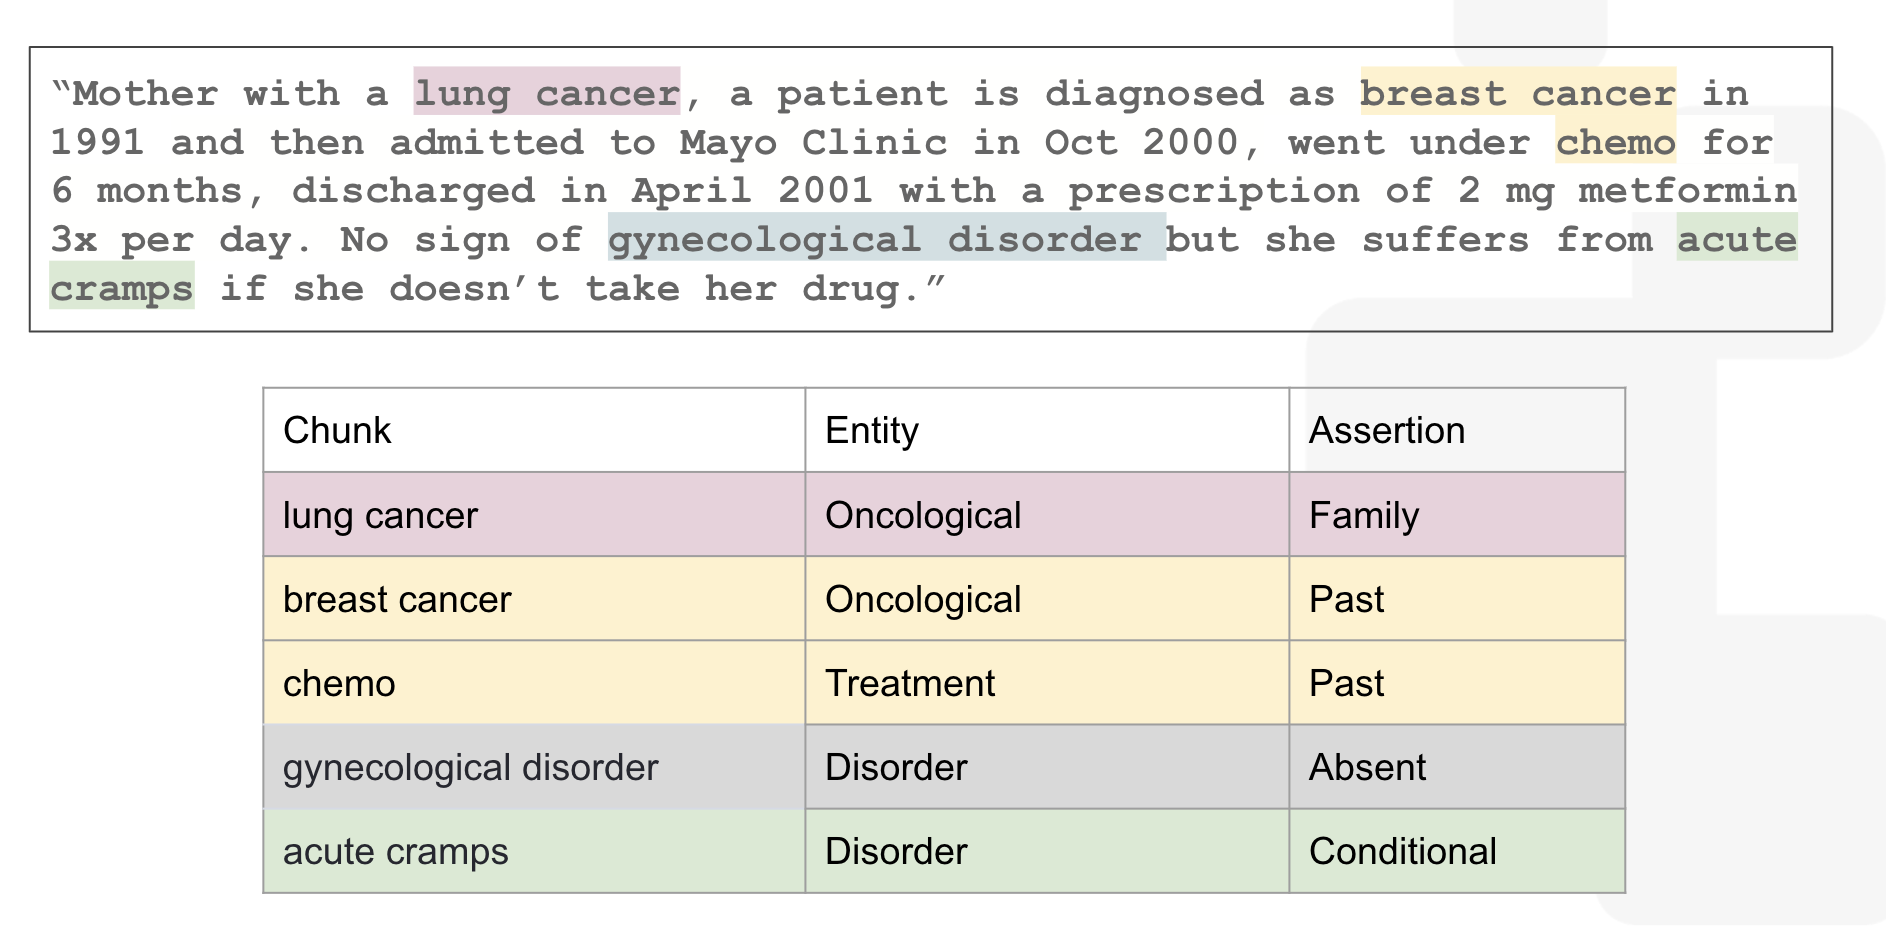

Let's start to create a Pipeline in order to detect assertion statuses with `assertion_dl` pretrained model. <br/>
This model detects following assertion status;
`absent`, `present`, `conditional`, `associated_with_someone_else`, `hypothetical`, `possible`.

And we will use **`AssertionFilterer`** for filtering out the NERs by the list of acceptable assertion statuses. This annotator would be quite handy if you want to set a white list for the acceptable assertion statuses like `present` or `conditional`; and do not want `absent` conditions get out of your pipeline.

In [ ]:
documentAssembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

sentenceDetector = SentenceDetector()\
    .setInputCols(["document"])\
    .setOutputCol("sentence")

tokenizer = Tokenizer()\
    .setInputCols(["sentence"])\
    .setOutputCol("token")

word_embeddings = WordEmbeddingsModel.pretrained("embeddings_clinical", "en", "clinical/models")\
    .setInputCols(["sentence", "token"])\
    .setOutputCol("embeddings")

clinical_ner = MedicalNerModel.pretrained("ner_clinical", "en", "clinical/models") \
    .setInputCols(["sentence", "token", "embeddings"]) \
    .setOutputCol("clinical_ner")

clinical_ner_converter = NerConverterInternal() \
    .setInputCols(["sentence", "token", "clinical_ner"]) \
    .setOutputCol("clinical_ner_chunk")

# Assertion model trained on i2b2 (sampled from MIMIC) dataset
clinical_assertion = AssertionDLModel.pretrained("assertion_dl", "en", "clinical/models") \
    .setInputCols(["sentence", "clinical_ner_chunk", "embeddings"]) \
    .setOutputCol("assertion")\
    # .setScopeWindow([9,15]) # default [9,15]

# filter out the named entities by the list of acceptable assertion statuses. present here.
assertion_filterer = AssertionFilterer()\
    .setInputCols("sentence","clinical_ner_chunk","assertion")\
    .setOutputCol("assertion_filtered")\
    .setWhiteList(["present"])

assertionPipeline = Pipeline(stages=[
    documentAssembler,
    sentenceDetector,
    tokenizer,
    word_embeddings,
    clinical_ner,
    clinical_ner_converter,
    clinical_assertion,
    assertion_filterer
    ])

assertion_model = assertionPipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

In [59]:
text = """
Patient with severe fever and sore throat also suffers from pain.
He shows no stomach pain and he maintained on an epidural and PCA for pain control.
He also become short of breath with climbing a flight of stairs.
After CT, lung tumor located at the right lower lobe. Father with Alzheimer.
"""

data = spark.createDataFrame([[text]]).toDF("text")

results = assertion_model.transform(data)
results.show()

+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|                text|            document|            sentence|               token|          embeddings|        clinical_ner|  clinical_ner_chunk|           assertion|  assertion_filtered|
+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|\nPatient with se...|[{document, 0, 29...|[{document, 1, 65...|[{token, 1, 7, Pa...|[{word_embeddings...|[{named_entity, 1...|[{chunk, 14, 25, ...|[{assertion, 14, ...|[{chunk, 14, 25, ...|
+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+



In [60]:
results.select(F.explode(F.arrays_zip(results.clinical_ner_chunk.result, results.clinical_ner_chunk.metadata, results.assertion.result)).alias("cols"))\
       .select(F.expr("cols['0']").alias("ner_chunk"),
               F.expr("cols['1']['entity']").alias("entities"),
               F.expr("cols['2']").alias("assertion")).show(truncate=False)

+---------------+---------+----------------------------+
|ner_chunk      |entities |assertion                   |
+---------------+---------+----------------------------+
|severe fever   |PROBLEM  |present                     |
|sore throat    |PROBLEM  |present                     |
|pain           |PROBLEM  |present                     |
|stomach pain   |PROBLEM  |absent                      |
|an epidural    |TREATMENT|present                     |
|PCA            |TREATMENT|possible                    |
|pain control   |PROBLEM  |hypothetical                |
|short of breath|PROBLEM  |conditional                 |
|CT             |TEST     |present                     |
|lung tumor     |PROBLEM  |present                     |
|Alzheimer      |PROBLEM  |associated_with_someone_else|
+---------------+---------+----------------------------+



#### **Assertion Filterer Results**



In [61]:
results.select("assertion_filtered.result").show(truncate=False)

+--------------------------------------------------------------+
|result                                                        |
+--------------------------------------------------------------+
|[severe fever, sore throat, pain, an epidural, CT, lung tumor]|
+--------------------------------------------------------------+



As you see above, **stomach pain**, **short of breath** and **Alzheimer** are not in the filtered results.

#### **Assertion Visualizer**

Also, we can visualize the assertion results by using `AssertionVisualizer` of Sparknlp-Display library.

In [62]:
from sparknlp_display import AssertionVisualizer

light_model = LightPipeline(assertion_model)
light_result = light_model.fullAnnotate(text)[0]

vis = AssertionVisualizer()
vis.display(light_result, 'clinical_ner_chunk', 'assertion')

### **Train a Custom Assertion Model**

To train an assertion status detection model, please check:

https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Healthcare/2.Clinical_Assertion_Model.ipynb

# **4. Clinical Deidentification**

Protected Health Information:
- individual’s past, present, or future physical or mental health or condition
- provision of health care to the individual
- past, present, or future payment for the health care

Protected health information includes many common identifiers (e.g., name, address, birth date, Social Security Number) when they can be associated with the health information.

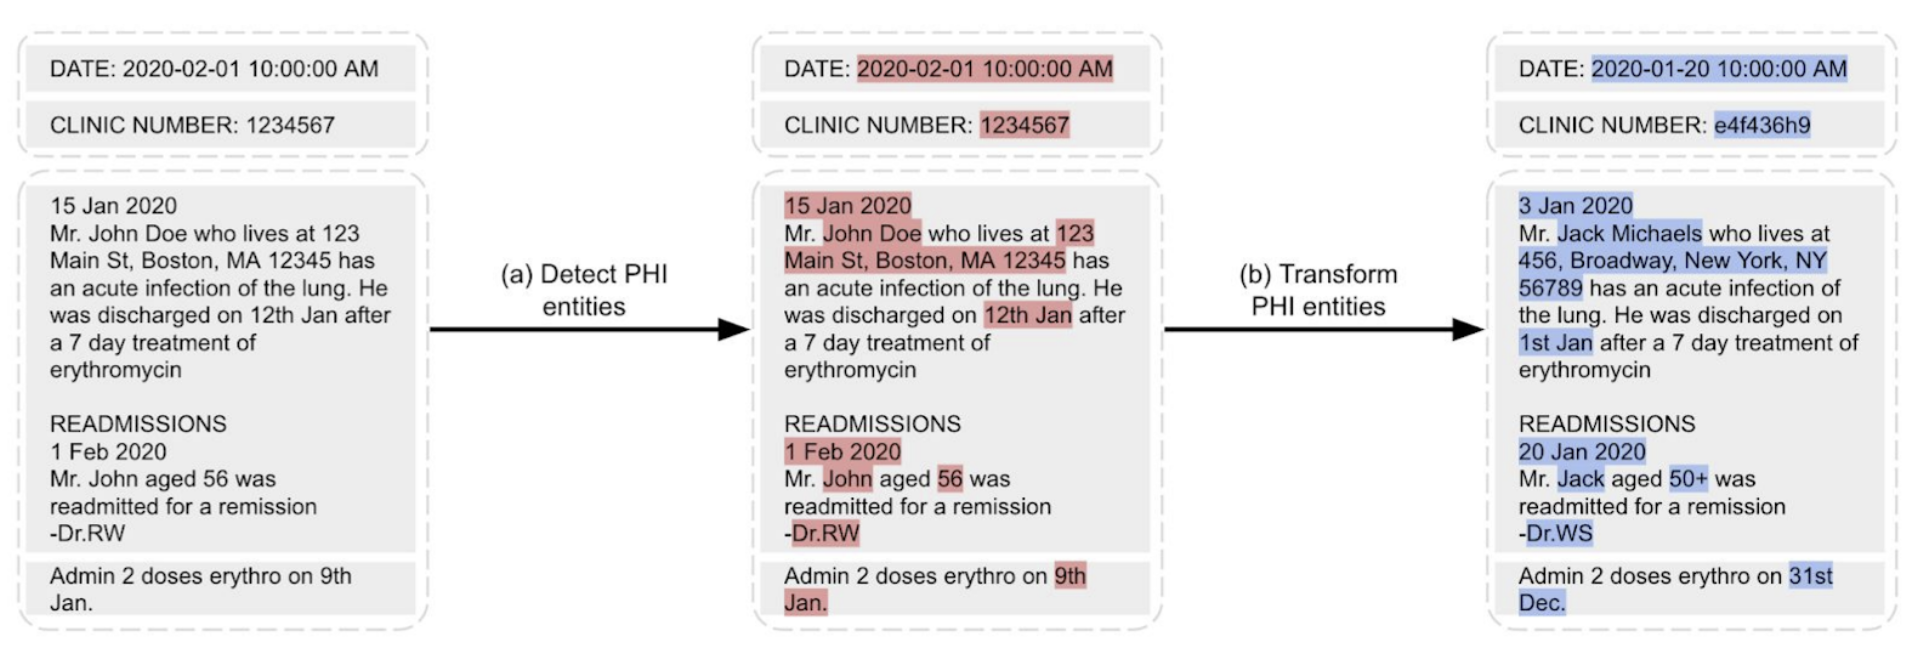

You can find **`German`, `Spanish`, `French`, `Italian`, `Portuguese`, `Romanian`**  and **`Arabic`**  deidentification models and pretrained pipeline examples in this notebook:   [Clinical Multi Language Deidentification Notebook](https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Healthcare/4.1.Clinical_Multi_Language_Deidentification.ipynb)


**ONE-LINER DEIDENTIFICATION MODULE** <br/>
Additionally, Spark NLP for Healthcare provides functionality to apply Deidentification using **one-liner module** called `Deid`. <br/>

The `Deid` module is a tool for deidentifying Protected Health Information (PHI) from data in a file path. It can be used with or without Spark NLP NER pipelines. It can apply deidentification and obfuscation on different columns at the same time.
It returns the deidentification & obfuscation results as a spark dataframe as well as a `csv` or `json file` saved locally.
The module also includes functionality for applying Structured Deidentification task to data from a file path. <br/>

Please visit [**Clinical Deidentification Utility Module Notebook**](https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Healthcare/4.5.Clinical_Deidentification_Utility_Module.ipynb) for datailed usage and examples.

Firstly, we will load NER pipeline to identify protected entities. Pretrained NER models extracts:

- Name
- Profession
- Age
- Date
- Contact(Telephone numbers, FAX numbers, Email addresses)
- Location (Address, City, Postal code, Hospital Name, Employment information)
- Id (Social Security numbers, Medical record numbers, Internet protocol addresses)

In [ ]:
documentAssembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

sentenceDetector = SentenceDetector()\
    .setInputCols(["document"])\
    .setOutputCol("sentence")

tokenizer = Tokenizer()\
    .setInputCols(["sentence"])\
    .setOutputCol("token")

word_embeddings = WordEmbeddingsModel.pretrained("embeddings_clinical", "en", "clinical/models")\
    .setInputCols(["sentence", "token"])\
    .setOutputCol("embeddings")

# NER model trained on n2c2 (de-identification and Heart Disease Risk Factors Challenge) datasets)
deid_ner = MedicalNerModel.pretrained("ner_deid_generic_augmented", "en", "clinical/models") \
    .setInputCols(["sentence", "token", "embeddings"]) \
    .setOutputCol("deid_ner")

deid_ner_converter = NerConverterInternal() \
    .setInputCols(["sentence", "token", "deid_ner"]) \
    .setOutputCol("deid_ner_chunk")

deidPipeline = Pipeline(
    stages=[
        documentAssembler,
        sentenceDetector,
        tokenizer,
        word_embeddings,
        deid_ner,
        deid_ner_converter
])

deid_model = deidPipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

In [64]:
text ='''
Record date : 2093-01-13 , David Hale , M.D . , Name : Hendrickson Ora , MR #7194334 Date : 01/13/93 . PCP : Oliveira , 25 years-old , Record date : 2079-11-09 . Cocke County Baptist Hospital , 0295 Keats Street , Phone 55-555-5555 .
'''

In [65]:
result = deid_model.transform(spark.createDataFrame([[text]]).toDF("text"))

Let's check extracted sensitive entities by NER pipeline

In [66]:
result.select(F.explode(F.arrays_zip(result.deid_ner_chunk.result,
                                     result.deid_ner_chunk.metadata)).alias("cols")) \
      .select(F.expr("cols['0']").alias("chunk"),
              F.expr("cols['1']['entity']").alias("ner_label")).show(truncate=False)

+-----------------------------+---------+
|chunk                        |ner_label|
+-----------------------------+---------+
|2093-01-13                   |DATE     |
|David Hale                   |NAME     |
|Hendrickson Ora              |NAME     |
|#7194334                     |ID       |
|01/13/93                     |DATE     |
|Oliveira                     |NAME     |
|25                           |AGE      |
|2079-11-09                   |DATE     |
|Cocke County Baptist Hospital|LOCATION |
|0295 Keats Street            |LOCATION |
|55-555-5555                  |CONTACT  |
+-----------------------------+---------+



Sometimes we need to leave some entities in the text, for example, if we want to analyze the frequency of the disease by the hospital.

In this case, we may use the parameter **`setBlackList()`** to modify `ner_chunk` output.

In [67]:
filtered_ner_converter = NerConverterInternal()\
    .setInputCols(["sentence", "token", "deid_ner"])\
    .setOutputCol("deid_ner_chunk") \
    .setBlackList(['LOCATION'])

deidPipeline = Pipeline(stages=[
    documentAssembler,
    sentenceDetector,
    tokenizer,
    word_embeddings,
    deid_ner,
    filtered_ner_converter])


model_with_black_list = deidPipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

result_with_black_list = model_with_black_list.transform(spark.createDataFrame([[text]]).toDF("text"))

In [68]:
print("All Labels :")
result.select(F.explode(F.arrays_zip(result.deid_ner_chunk.result, result.deid_ner_chunk.metadata)).alias("cols")) \
      .select(F.expr("cols['0']").alias("chunk"),
              F.expr("cols['1']['entity']").alias("ner_label")).show(truncate=False)

print("BlackListed Labels: ")
result_with_black_list.select(F.explode(F.arrays_zip(result_with_black_list.deid_ner_chunk.result, result_with_black_list.deid_ner_chunk.metadata)).alias("cols")) \
                      .select(F.expr("cols['0']").alias("chunk"),
                              F.expr("cols['1']['entity']").alias("ner_label")).show(truncate=False)

All Labels :
+-----------------------------+---------+
|chunk                        |ner_label|
+-----------------------------+---------+
|2093-01-13                   |DATE     |
|David Hale                   |NAME     |
|Hendrickson Ora              |NAME     |
|#7194334                     |ID       |
|01/13/93                     |DATE     |
|Oliveira                     |NAME     |
|25                           |AGE      |
|2079-11-09                   |DATE     |
|Cocke County Baptist Hospital|LOCATION |
|0295 Keats Street            |LOCATION |
|55-555-5555                  |CONTACT  |
+-----------------------------+---------+

BlackListed Labels: 
+---------------+---------+
|chunk          |ner_label|
+---------------+---------+
|2093-01-13     |DATE     |
|David Hale     |NAME     |
|Hendrickson Ora|NAME     |
|#7194334       |ID       |
|01/13/93       |DATE     |
|Oliveira       |NAME     |
|25             |AGE      |
|2079-11-09     |DATE     |
|55-555-5555    |CONTACT  |

### **Masking**

**Masking** replaces the enitites with tags.

Just specifiy `setMode()` parameter as `setMode("mask")` in `DeIdentification()` in order to apply masking.

In [69]:
deid_ner_converter = NerConverterInternal()\
    .setInputCols(["sentence", "token", "deid_ner"])\
    .setOutputCol("deid_ner_chunk")

deidentification = DeIdentification() \
    .setInputCols(["sentence", "token", "deid_ner_chunk"]) \
    .setOutputCol("deidentified") \
    .setMode("mask")\
    .setReturnEntityMappings(True) #  return a new column to save the mappings between the mask/obfuscated entities and original entities.
    #.setMappingsColumn("MappingCol") # change the name of the column, 'aux' is default

deidPipeline = Pipeline(
    stages=[
        documentAssembler,
        sentenceDetector,
        tokenizer,
        word_embeddings,
        deid_ner,
        deid_ner_converter,
        deidentification
])

deid_model = deidPipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

In [70]:
result = deid_model.transform(spark.createDataFrame([[text]]).toDF("text"))
result.show()

+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|                text|            document|            sentence|               token|          embeddings|            deid_ner|      deid_ner_chunk|        deidentified|                 aux|
+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|\nRecord date : 2...|[{document, 0, 23...|[{document, 1, 45...|[{token, 1, 6, Re...|[{word_embeddings...|[{named_entity, 1...|[{chunk, 15, 24, ...|[{document, 0, 36...|[{chunk, 14, 19, ...|
+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+



Let's check the results

In [71]:
pd.set_option('display.max_colwidth', None)

result.select(F.explode(F.arrays_zip(result.sentence.result, result.deidentified.result)).alias("cols")) \
      .select(F.expr("cols['0']").alias("sentence"),
              F.expr("cols['1']").alias("deidentified")).toPandas()

,sentence,deidentified
0,"Record date : 2093-01-13 , David Hale , M.D .","Record date : <DATE> , <NAME> , M.D ."
1,", Name : Hendrickson Ora , MR #7194334 Date : 01/13/93 .",", Name : <NAME> , MR <ID> Date : <DATE> ."
2,"PCP : Oliveira , 25 years-old , Record date : 2079-11-09 .","PCP : <NAME> , <AGE> years-old , Record date : <DATE> ."
3,"Cocke County Baptist Hospital , 0295 Keats Street , Phone 55-555-5555 .","<LOCATION> , <LOCATION> , Phone <CONTACT> ."


We have three modes to mask the entities in the Deidentification annotator. You can select the modes using the `.setMaskingPolicy()` parameter. The methods are the followings:

**“entity_labels”**: Mask with the entity type of that chunk. (default) <br/>
**“same_length_chars”**: Mask the deid entities with same length of asterix ( * ) with brackets ( [ , ] ) on both end. <br/>
**“fixed_length_chars”**: Mask the deid entities with a fixed length of asterix ( * ). The length is setting up using the `setFixedMaskLength()` method. <br/>


In [72]:
#deid model with "entity_labels"
deid_entity_labels= DeIdentification()\
    .setInputCols(["sentence", "token", "deid_ner_chunk"])\
    .setOutputCol("deid_entity_label")\
    .setMode("mask")\
    .setReturnEntityMappings(True)\
    .setMaskingPolicy("entity_labels")

#deid model with "same_length_chars"
deid_same_length= DeIdentification()\
    .setInputCols(["sentence", "token", "deid_ner_chunk"])\
    .setOutputCol("deid_same_length")\
    .setMode("mask")\
    .setReturnEntityMappings(True)\
    .setMaskingPolicy("same_length_chars")

#deid model with "fixed_length_chars"
deid_fixed_length= DeIdentification()\
    .setInputCols(["sentence", "token", "deid_ner_chunk"])\
    .setOutputCol("deid_fixed_length")\
    .setMode("mask")\
    .setReturnEntityMappings(True)\
    .setMaskingPolicy("fixed_length_chars")\
    .setFixedMaskLength(4)


deidPipeline = Pipeline(
    stages=[
        documentAssembler,
        sentenceDetector,
        tokenizer,
        word_embeddings,
        deid_ner,
        deid_ner_converter,
        deid_entity_labels,
        deid_same_length,
        deid_fixed_length
])

deid_model = deidPipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

In [73]:
policy_result = deid_model.transform(spark.createDataFrame([[text]]).toDF("text"))
policy_result.show()

+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|                text|            document|            sentence|               token|          embeddings|            deid_ner|      deid_ner_chunk|   deid_entity_label|                 aux|    deid_same_length|   deid_fixed_length|
+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|\nRecord date : 2...|[{document, 0, 23...|[{document, 1, 45...|[{token, 1, 6, Re...|[{word_embeddings...|[{named_entity, 1...|[{chunk, 15, 24, ...|[{document, 0, 36...|[{chunk, 14, 17, ...|[{document, 0, 44...|[{document, 0, 32...|
+--------------------+--------------------+--------------------+----

In [74]:
policy_result.select(F.explode(F.arrays_zip(policy_result.sentence.result,
                                            policy_result.deid_entity_label.result,
                                            policy_result.deid_same_length.result,
                                            policy_result.deid_fixed_length.result)).alias("cols")) \
             .select(F.expr("cols['0']").alias("sentence"),
                     F.expr("cols['1']").alias("deid_entity_label"),
                     F.expr("cols['2']").alias("deid_same_length"),
                     F.expr("cols['3']").alias("deid_fixed_length")).toPandas()

,sentence,deid_entity_label,deid_same_length,deid_fixed_length
0,"Record date : 2093-01-13 , David Hale , M.D .","Record date : <DATE> , <NAME> , M.D .","Record date : [********] , [********] , M.D .","Record date : **** , **** , M.D ."
1,", Name : Hendrickson Ora , MR #7194334 Date : 01/13/93 .",", Name : <NAME> , MR <ID> Date : <DATE> .",", Name : [*************] , MR [******] Date : [******] .",", Name : **** , MR **** Date : **** ."
2,"PCP : Oliveira , 25 years-old , Record date : 2079-11-09 .","PCP : <NAME> , <AGE> years-old , Record date : <DATE> .","PCP : [******] , ** years-old , Record date : [********] .","PCP : **** , **** years-old , Record date : **** ."
3,"Cocke County Baptist Hospital , 0295 Keats Street , Phone 55-555-5555 .","<LOCATION> , <LOCATION> , Phone <CONTACT> .","[***************************] , [***************] , Phone [*********] .","**** , **** , Phone **** ."


### **Reidentification**

We can use `ReIdentification` annotator to go back to the original sentence.

In [75]:
reIdentification = ReIdentification()\
    .setInputCols(["aux","deidentified"])\
    .setOutputCol("original")

In [76]:
reid_result = reIdentification.transform(result)
reid_result.show()

+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|                text|            document|            sentence|               token|          embeddings|            deid_ner|      deid_ner_chunk|        deidentified|                 aux|            original|
+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|\nRecord date : 2...|[{document, 0, 23...|[{document, 1, 45...|[{token, 1, 6, Re...|[{word_embeddings...|[{named_entity, 1...|[{chunk, 15, 24, ...|[{document, 0, 36...|[{chunk, 14, 19, ...|[{document, 1, 45...|
+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+----

In [77]:
print(text)

reid_result.select('original.result').show(truncate=False)


Record date : 2093-01-13 , David Hale , M.D . , Name : Hendrickson Ora , MR #7194334 Date : 01/13/93 . PCP : Oliveira , 25 years-old , Record date : 2079-11-09 . Cocke County Baptist Hospital , 0295 Keats Street , Phone 55-555-5555 .

+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|result                                                                                                                                                                                                                                        |
+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|[Record date : 2093-01-13 , David Hale ,

### **Enriching with Regex and Override NER**




We can enrich our existing Deidentification model with both custom and embedded regex.

Firstly, let's build our deid pipeline again, but this time by filtering "`CONTACT`" entities from ner model.

Then, we will set `setReturnEntityMappings(True)`. In this way, we are going to see that we still be able to deidentify "`CONTACT`" as `PHONE` even though ner model doesn't detect "`CONTACT`" entity since the regex embedded in deid model will be taken account.

In [78]:
filtered_ner_converter = NerConverterInternal()\
    .setInputCols(["sentence", "token", "deid_ner"])\
    .setOutputCol("deid_ner_chunk")\
    .setBlackList(["CONTACT"])

deidentification = DeIdentification() \
    .setInputCols(["sentence", "token", "deid_ner_chunk"]) \
    .setOutputCol("deidentified") \
    .setMode("mask")\
    .setRegexOverride(True)

deidPipeline = Pipeline(
    stages=[
        documentAssembler,
        sentenceDetector,
        tokenizer,
        word_embeddings,
        deid_ner,
        filtered_ner_converter,
        deidentification
])

model_default_rgx = deidPipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

In [79]:
result = model_default_rgx.transform(spark.createDataFrame([[text]]).toDF("text"))

result.select(F.explode(F.arrays_zip(result.sentence.result, result.deidentified.result)).alias("cols")) \
      .select(F.expr("cols['0']").alias("sentence"), F.expr("cols['1']").alias("deidentified")).toPandas()

,sentence,deidentified
0,"Record date : 2093-01-13 , David Hale , M.D .","Record date : <DATE> , <NAME> , M.D ."
1,", Name : Hendrickson Ora , MR #7194334 Date : 01/13/93 .",", Name : <NAME> , MR <ID> Date : <DATE> ."
2,"PCP : Oliveira , 25 years-old , Record date : 2079-11-09 .","PCP : <NAME> , <AGE> years-old , Record date : <DATE> ."
3,"Cocke County Baptist Hospital , 0295 Keats Street , Phone 55-555-5555 .","<LOCATION> , <LOCATION> , Phone <PHONE> ."


As you see above, we were able to deidentify `CONTACT` entity as `PHONE` which comes from the embedded regex even though ner model doesn't detect them.

Now, let's identify a custom regex and see how it works.

We will write a regex to deidentify "number" and save it as .txt file. Then, we will specify this file in `Deidentification()` through `setRegexPatternsDictionary()` parameter.

In [80]:
rgx = r"""NUMBER ([0-9]{2})
NUMBER (\d{7})"""

with open("./custom_regex.txt", "w") as f:
  f.write(rgx)

f = open("./custom_regex.txt", "r")

print(f.read())

NUMBER ([0-9]{2})
NUMBER (\d{7})


In [81]:
deid_ner_converter = NerConverterInternal()\
      .setInputCols(["sentence", "token", "deid_ner"])\
      .setOutputCol("deid_ner_chunk")

deidentification_rgx = DeIdentification()\
    .setInputCols(["sentence", "token", "deid_ner_chunk"])\
    .setOutputCol("deidentified")\
    .setMode("mask") \
    .setRegexPatternsDictionary("./custom_regex.txt")\
    .setRegexOverride(True)# Prioritizing regex rules

deidPipeline = Pipeline(
    stages=[
        documentAssembler,
        sentenceDetector,
        tokenizer,
        word_embeddings,
        deid_ner,
        deid_ner_converter,
        deidentification_rgx
])

model_rgx = deidPipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

In [82]:
text ='''Record date : 2093-01-13 , David Hale , M.D . , Name : Hendrickson , Ora MR . # 7194334 Date : 01/13/93 PCP : Oliveira , 25 years-old , Record date : 2079-11-09 . Cocke County Baptist Hospital . 0295 Keats Street.'''
result = model_rgx.transform(spark.createDataFrame([[text]]).toDF("text"))

result.select(F.explode(F.arrays_zip(result.sentence.result, result.deidentified.result)).alias("cols")) \
      .select(F.expr("cols['0']").alias("sentence"), F.expr("cols['1']").alias("deidentified")).toPandas()

,sentence,deidentified
0,"Record date : 2093-01-13 , David Hale , M.D .","Record date : <DATE> , <NAME> , M.D ."
1,", Name : Hendrickson , Ora MR .",", Name : <NAME> MR ."
2,"# 7194334 Date : 01/13/93 PCP : Oliveira , 25 years-old , Record date : 2079-11-09 .","# <NUMBER> Date : <DATE> PCP : <NAME> , <NUMBER> years-old , Record date : <DATE> ."
3,Cocke County Baptist Hospital .,<LOCATION> .
4,0295 Keats Street.,<LOCATION>.


As you see above, we deidentified the "number" through our custom regex even though ner model doesn't detect the "number" entity.

### **Obfuscation**

In the obfuscation mode **DeIdentificationModel** will replace sensetive entities with random values of the same type.

Use `.setMode("obfuscate")` to activate this feature.


In [83]:
deid_ner_converter = NerConverterInternal()\
      .setInputCols(["sentence", "token", "deid_ner"])\
      .setOutputCol("deid_ner_chunk")

obfuscation = DeIdentification()\
    .setInputCols(["sentence", "token", "deid_ner_chunk"]) \
    .setOutputCol("deidentified") \
    .setMode("obfuscate")\
    .setObfuscateDate(True)\

deidPipeline = Pipeline(
    stages=[
        documentAssembler,
        sentenceDetector,
        tokenizer,
        word_embeddings,
        deid_ner,
        deid_ner_converter,
        obfuscation
])

obfuscation_model = deidPipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

In [84]:
text ='''
Record date : 2093-01-13 , David Hale , M.D . , Name : Hendrickson , Ora MR #7194334 Date : 01/13/93 . Patient : Oliveira, 25 years-old , Record date : 2079-11-09 . Cocke County Baptist Hospital . 0295 Keats Street
'''

result = obfuscation_model.transform(spark.createDataFrame([[text]]).toDF("text"))

result.select(F.explode(F.arrays_zip(result.sentence.result, result.deidentified.result)).alias("cols")) \
      .select(F.expr("cols['0']").alias("sentence"), F.expr("cols['1']").alias("deidentified")).toPandas()

,sentence,deidentified
0,"Record date : 2093-01-13 , David Hale , M.D .","Record date : 2093-02-15 , Rachelle Rieger , M.D ."
1,", Name : Hendrickson , Ora MR #7194334 Date : 01/13/93 .",", Name : Alyce Kim LEMME #4283663 Date : 02/15/93 ."
2,"Patient : Oliveira, 25 years-old , Record date : 2079-11-09 .","Patient : Nigel, 22 years-old , Record date : 2079-12-12 ."
3,Cocke County Baptist Hospital .,600 Pemberton-browns Mills Road .
4,0295 Keats Street,36485 Inland Valley


In addition, we can define a reference file for obfuscation. In this way, deid model uses the fake entities that we defined in this file.

If we want to use reference file, we should give the path of txt file that includes our custom entities to the `setObfuscateRefFile()` parameter. Then, we should set `setObfuscateRefSource("file")` parameter.

However, we can set `setObfuscateRefSource` parameter as **faker** or **both** as well.

The faker module allows  the user to use a set of fake entities that are in the memory of the spark-nlp-internal. You can set up this module for using the following property `setObfuscateRefSource('faker')`.

If we select the `setObfuscateRefSource('both')` then we choose randomly the entities using the faker and the fake entities from the obfuscateRefFile.





In [85]:
obs_lines = """Marvin MARSHALL#NAME
Hubert GROGAN#NAME
ALTHEA COLBURN#NAME
Kalil AMIN#NAME
Inci FOUNTAIN#NAME
Ekaterina Rosa#NAME
Rudiger Chao#NAME
COLLETTE KOHLER#NAME
Mufi HIGGS#NAME"""


with open ('obfuscation.txt', 'w') as f:
  f.write(obs_lines)

In [86]:
deid_ner_converter = NerConverterInternal()\
      .setInputCols(["sentence", "token", "deid_ner"])\
      .setOutputCol("deid_ner_chunk")

obfuscation = DeIdentification()\
    .setInputCols(["sentence", "token", "deid_ner_chunk"]) \
    .setOutputCol("deidentified") \
    .setMode("obfuscate")\
    .setObfuscateDate(True)\
    .setObfuscateRefFile('obfuscation.txt')\
    .setObfuscateRefSource("file") #both or faker

deidPipeline = Pipeline(
    stages=[
        documentAssembler,
        sentenceDetector,
        tokenizer,
        word_embeddings,
        deid_ner,
        deid_ner_converter,
        obfuscation
])

obfuscation_model = deidPipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

In [87]:
text ='''
Record date : 2093-01-13 , David Hale , M.D . , Name : Hendrickson , Ora MR # 7194334 Date : 01/13/93 . Patient : Oliveira, 25 years-old , Record date : 2079-11-09 . Cocke County Baptist Hospital . 0295 Keats Street
'''

result = obfuscation_model.transform(spark.createDataFrame([[text]]).toDF("text"))

result.select(F.explode(F.arrays_zip(result.sentence.result,
                                     result.deidentified.result)).alias("cols")) \
      .select(F.expr("cols['0']").alias("sentence"),
              F.expr("cols['1']").alias("deidentified")).toPandas()

,sentence,deidentified
0,"Record date : 2093-01-13 , David Hale , M.D .","Record date : 2093-03-04 , Inci Fountain , M.D ."
1,", Name : Hendrickson , Ora MR # 7194334 Date : 01/13/93 .",", Name : Marvin Marshall MR # 5972112 Date : 03/04/93 ."
2,"Patient : Oliveira, 25 years-old , Record date : 2079-11-09 .","Patient : Ekaterina Rosa, 32 years-old , Record date : 2079-12-29 ."
3,Cocke County Baptist Hospital .,<LOCATION> .
4,0295 Keats Street,<LOCATION>


**`.setObfuscateDate(True)` parameter obfuscated the `DATE` entities and the `NAME`s were replaced with the custom list.**

## **Shifting Days**

In the example above, we replaced date entities with another date randomly.

Instead of that, we can shift the date according to any column.

In [88]:
#sample data for day shifting
data = pd.DataFrame(
    {'patientID' : ['A001', 'A001', 'A002', 'A002'],
     'text' : ['Chris Brown was discharged on 10/02/2022',
               'Mark White was discharged on 02/28/2020',
               'John was discharged on 03/15/2022',
               'John Moore was discharged on 12/31/2022'
              ]
    }
)

my_input_df = spark.createDataFrame(data)

my_input_df.show(truncate = False)

+---------+----------------------------------------+
|patientID|text                                    |
+---------+----------------------------------------+
|A001     |Chris Brown was discharged on 10/02/2022|
|A001     |Mark White was discharged on 02/28/2020 |
|A002     |John was discharged on 03/15/2022       |
|A002     |John Moore was discharged on 12/31/2022 |
+---------+----------------------------------------+



**Shifting Days According to the ID Column**

We use the `DocumentHashCoder()` annotator to determine shifting days.

This annotator gets the hash of the specified column and creates a new document column containing day shift information. And then, the `DeIdentification` annotator deidentifies this new doc.

Set the seed parameter to hash for consistency.  

In [ ]:
documentAssembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

documentHasher = DocumentHashCoder()\
    .setInputCols("document")\
    .setOutputCol("document2")\
    .setPatientIdColumn("patientID")\
    .setRangeDays(100)\
    .setNewDateShift("shift_days")\
    .setSeed(100)

tokenizer = Tokenizer()\
    .setInputCols(["document2"])\
    .setOutputCol("token")

embeddings = WordEmbeddingsModel.pretrained("embeddings_clinical", "en", "clinical/models")\
    .setInputCols(["document2", "token"])\
    .setOutputCol("word_embeddings")

clinical_ner = MedicalNerModel\
    .pretrained("ner_deid_subentity_augmented", "en", "clinical/models")\
    .setInputCols(["document2","token", "word_embeddings"])\
    .setOutputCol("ner")

ner_converter = NerConverterInternal()\
    .setInputCols(["document2", "token", "ner"])\
    .setOutputCol("ner_chunk")

de_identification = DeIdentification() \
    .setInputCols(["ner_chunk", "token", "document2"]) \
    .setOutputCol("deid_text") \
    .setMode("obfuscate") \
    .setObfuscateDate(True) \
    .setDateTag("DATE") \
    .setLanguage("en") \
    .setObfuscateRefSource('faker') \
    .setUseShifDays(True)\
    .setRegion('us')

pipeline = Pipeline().setStages([
    documentAssembler,
    documentHasher,
    tokenizer,
    embeddings,
    clinical_ner,
    ner_converter,
    de_identification
])

empty_data = spark.createDataFrame([["", ""]]).toDF("text", "patientID")

pipeline_model = pipeline.fit(empty_data)

In [90]:
output = pipeline_model.transform(my_input_df)

output.select('patientID','text', "shift_days", 'deid_text.result').show(truncate = False)

+---------+----------------------------------------+----------+------------------------------------------+
|patientID|text                                    |shift_days|result                                    |
+---------+----------------------------------------+----------+------------------------------------------+
|A001     |Chris Brown was discharged on 10/02/2022|-5        |[Tereso Keys was discharged on 09/27/2022]|
|A001     |Mark White was discharged on 02/28/2020 |-5        |[Red Brisker was discharged on 02/23/2020]|
|A002     |John was discharged on 03/15/2022       |29        |[Jenet was discharged on 04/13/2022]      |
|A002     |John Moore was discharged on 12/31/2022 |29        |[Jenet Mare was discharged on 01/29/2023] |
+---------+----------------------------------------+----------+------------------------------------------+



**Shifting Days According to Specified Values**

Instead of shifting days according to ID column, we can specify shifting values with another column.

```python
documentHasher = DocumentHashCoder()\
    .setInputCols("document")\
    .setOutputCol("document2")\
    .setDateShiftColumn("dateshift")\
```


In [91]:
data = pd.DataFrame(
    {'patientID' : ['A001', 'A002', 'A003', 'A004'],
     'text' : ['Chris Brown was discharged on 10/02/2022',
               'Mark White was discharged on 03/01/2020',
               'John was discharged on 03/15/2022',
               'John Moore was discharged on 12/31/2022'
              ],
     'dateshift' : ['10', '-2', '30', '-8']
    }
)

my_input_df = spark.createDataFrame(data)

my_input_df.show(truncate=False)

+---------+----------------------------------------+---------+
|patientID|text                                    |dateshift|
+---------+----------------------------------------+---------+
|A001     |Chris Brown was discharged on 10/02/2022|10       |
|A002     |Mark White was discharged on 03/01/2020 |-2       |
|A003     |John was discharged on 03/15/2022       |30       |
|A004     |John Moore was discharged on 12/31/2022 |-8       |
+---------+----------------------------------------+---------+



In [ ]:
documentAssembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

documentHasher = DocumentHashCoder()\
    .setInputCols("document")\
    .setOutputCol("document2")\
    .setDateShiftColumn("dateshift")\

tokenizer = Tokenizer()\
    .setInputCols(["document2"])\
    .setOutputCol("token")

embeddings = WordEmbeddingsModel.pretrained("embeddings_clinical", "en", "clinical/models")\
    .setInputCols(["document2", "token"])\
    .setOutputCol("word_embeddings")

clinical_ner = MedicalNerModel\
    .pretrained("ner_deid_subentity_augmented", "en", "clinical/models")\
    .setInputCols(["document2","token", "word_embeddings"])\
    .setOutputCol("ner")

ner_converter = NerConverterInternal()\
    .setInputCols(["document2", "token", "ner"])\
    .setOutputCol("ner_chunk")

de_identification = DeIdentification() \
    .setInputCols(["ner_chunk", "token", "document2"]) \
    .setOutputCol("deid_text") \
    .setMode("obfuscate") \
    .setObfuscateDate(True) \
    .setDateTag("DATE") \
    .setLanguage("en") \
    .setObfuscateRefSource('faker') \
    .setUseShifDays(True)\
    .setRegion('us')

pipeline_col = Pipeline().setStages([
    documentAssembler,
    documentHasher,
    tokenizer,
    embeddings,
    clinical_ner,
    ner_converter,
    de_identification

])

empty_data = spark.createDataFrame([["", "", ""]]).toDF("patientID","text", "dateshift")

pipeline_col_model = pipeline_col.fit(empty_data)

In [93]:
output = pipeline_col_model.transform(my_input_df)

output.select('text', 'dateshift', 'deid_text.result').show(truncate = False)

+----------------------------------------+---------+-------------------------------------------------+
|text                                    |dateshift|result                                           |
+----------------------------------------+---------+-------------------------------------------------+
|Chris Brown was discharged on 10/02/2022|10       |[Kathy Lofts was discharged on 10/12/2022]       |
|Mark White was discharged on 03/01/2020 |-2       |[Genoveva Goodnight was discharged on 02/28/2020]|
|John was discharged on 03/15/2022       |30       |[Irean was discharged on 04/14/2022]             |
|John Moore was discharged on 12/31/2022 |-8       |[Irean Fusi was discharged on 12/23/2022]        |
+----------------------------------------+---------+-------------------------------------------------+



## **Age Groups Obfuscation**

In [ ]:
documentAssembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

sentenceDetector = SentenceDetectorDLModel.pretrained("sentence_detector_dl_healthcare","en","clinical/models")\
    .setInputCols(["document"])\
    .setOutputCol("sentence")

tokenizer = Tokenizer()\
    .setInputCols(["sentence"])\
    .setOutputCol("token")

embeddings = WordEmbeddingsModel.pretrained("embeddings_clinical", "en", "clinical/models")\
    .setInputCols(["sentence", "token"])\
    .setOutputCol("word_embeddings")

clinical_ner = MedicalNerModel\
    .pretrained("ner_deid_subentity_augmented", "en", "clinical/models")\
    .setInputCols(["sentence","token", "word_embeddings"])\
    .setOutputCol("ner")

ner_converter = NerConverterInternal()\
    .setInputCols(["sentence", "token", "deid_ner"])\
    .setOutputCol("age_chunk")\
    .setWhiteList(["AGE"])

obfuscation = DeIdentification()\
    .setInputCols(["sentence", "token", "age_chunk"]) \
    .setOutputCol("obfuscation") \
    .setMode("obfuscate")\
    .setObfuscateDate(True)\
    .setObfuscateRefSource("faker") \
    .setAgeRanges([1, 4, 12, 20, 40, 60, 80])

nlpPipeline = Pipeline(
    stages=[
        documentAssembler,
        sentenceDetector,
        tokenizer,
        word_embeddings,
        deid_ner,
        ner_converter,
        obfuscation
])

empty_data = spark.createDataFrame([[""]]).toDF("text")

model_agerange = nlpPipeline.fit(empty_data)

In [95]:
# Infant = 0-1 year.
# Toddler = 2-4 yrs.
# Child = 5-12 yrs.
# Teen = 13-19 yrs.
# Adult = 20-39 yrs.
# Middle Age Adult = 40-59 yrs.
# Senior Adult = 60+

dates = [
'1 year old baby',
'4 year old kids',
'A 15 year old female with',
'Record date: 2093-01-13, Age: 25',
'Patient is 45 years-old',
'He is 65 years-old male'
]
from pyspark.sql.types import StringType
df_dates = spark.createDataFrame(dates,StringType()).toDF('text')


result = model_agerange.transform(df_dates)

result_df = result.select("text",F.explode(F.arrays_zip(result.age_chunk.result,
                                                        result.obfuscation.result)).alias("cols")) \
                  .select("text",F.expr("cols['0']").alias("age_chunk"),
                                 F.expr("cols['1']").alias("obfuscation"))

result_df.show(truncate=False)

+--------------------------------+---------+--------------------------------+
|text                            |age_chunk|obfuscation                     |
+--------------------------------+---------+--------------------------------+
|1 year old baby                 |1        |3 year old baby                 |
|4 year old kids                 |4        |11 year old kids                |
|A 15 year old female with       |15       |A 14 year old female with       |
|Record date: 2093-01-13, Age: 25|25       |Record date: 2093-02-25, Age: 23|
|Patient is 45 years-old         |45       |Patient is 42 years-old         |
|He is 65 years-old male         |65       |He is 61 years-old male         |
+--------------------------------+---------+--------------------------------+



## **Multi-Mode Deidentification**

`DeIdentification()` has multi-mode functionality.

By providing a json file to the `setSelectiveObfuscationModes("a JSON path")` parameter, multi-mode in de-identification is possible. <br/>

The entities which have not been given in the dictionary will be deidentified according to the `setMode()` parameter.

In [96]:
#json to choose deid modes
sample_json= {
	"obfuscate": ["PHONE"] ,
	"mask_entity_labels": ["ID"],
	"skip": ["DATE"],
	"mask_same_length_chars":["NAME"],
	"mask_fixed_length_chars":["zip", "location"]
}

import json
with open('sample_multi-mode.json', 'w', encoding='utf-8') as f:
    json.dump(sample_json, f, ensure_ascii=False, indent=4)

In [ ]:
clinical_ner = MedicalNerModel.pretrained("ner_deid_generic_augmented", "en", "clinical/models") \
    .setInputCols(["sentence", "token", "embeddings"]) \
    .setOutputCol("ner")

ner_converter = NerConverterInternal()\
    .setInputCols(["sentence", "token", "ner"])\
    .setOutputCol("ner_chunk")\
    .setBlackList(["CONTACT"])

deid_doc = DeIdentification() \
      .setInputCols(["sentence", "token", "ner_chunk"]) \
      .setOutputCol("deidentified") \
      .setMode("mask")\
      .setSelectiveObfuscationModesPath("sample_multi-mode.json")\
      .setSameLengthFormattedEntities(["PHONE"])\
      .setFixedMaskLength(2)

deidPipeline = Pipeline(stages=[
      documentAssembler,
      sentenceDetector,
      tokenizer,
      word_embeddings,
      clinical_ner,
      ner_converter,
      deid_doc])

empty_data = spark.createDataFrame([[""]]).toDF("text")

text ='''
Record date : 2093-01-13 , David Hale , M.D . , Name : Hendrickson Ora , MR # 7194334 Date : 01/13/93 . PCP : Oliveira , 25 years-old , Record date : 2079-11-09 . Cocke County Baptist Hospital , 0295 Keats Street , Phone 55-555-5555 .
'''

model_deid = deidPipeline.fit(empty_data)
result = model_deid.transform(spark.createDataFrame([[text]]).toDF("text"))


In [98]:
result.select(F.explode(F.arrays_zip(result.sentence.result, result.deidentified.result)).alias("cols")) \
      .select(F.expr("cols['0']").alias("sentence"),
              F.expr("cols['1']").alias("deidentified")).show(truncate=False)

+-------------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+
|sentence                                                                                               |deidentified                                                                                        |
+-------------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+
|Record date : 2093-01-13 , David Hale , M.D . , Name : Hendrickson Ora , MR # 7194334 Date : 01/13/93 .|Record date : 2093-01-13 , [********] , M.D . , Name : [*************] , MR # <ID> Date : 01/13/93 .|
|PCP : Oliveira , 25 years-old , Record date : 2079-11-09 .                                             |PCP : [******] , <AGE> years-old , Record date : 2079-11-09 .      

## **Structured Deidentification**

Deidentification can also be applied to structured data as well.



In [99]:
!wget -q https://raw.githubusercontent.com/JohnSnowLabs/spark-nlp-workshop/master/tutorials/Certification_Trainings/Healthcare/data/hipaa-table-001.txt

df = spark.read.format("csv") \
    .option("sep", "\t") \
    .option("inferSchema", "true") \
    .option("header", "true") \
    .load("hipaa-table-001.txt")

df = df.withColumnRenamed("PATIENT","NAME")
df.show(truncate=False)

+---------------+----------+---+----------------------------------------------------+-------+--------------+---+---+
|NAME           |DOB       |AGE|ADDRESS                                             |ZIPCODE|TEL           |SBP|DBP|
+---------------+----------+---+----------------------------------------------------+-------+--------------+---+---+
|Cecilia Chapman|04/02/1935|83 |711-2880 Nulla St. Mankato Mississippi              |69200  |(257) 563-7401|101|42 |
|Iris Watson    |03/10/2009|9  |P.O. Box 283 8562 Fusce Rd. Frederick Nebraska      |20620  |(372) 587-2335|159|122|
|Bryar Pitts    |11/01/1921|98 |5543 Aliquet St. Fort Dodge GA                      |20783  |(717) 450-4729|149|52 |
|Theodore Lowe  |13/02/2002|16 |Ap #867-859 Sit Rd. Azusa New York                  |39531  |(793) 151-6230|134|115|
|Calista Wise   |20/08/1942|76 |7292 Dictum Av. San Antonio MI                      |47096  |(492) 709-6392|139|78 |
|Kyla Olsen     |12/05/1973|45 |Ap #651-8679 Sodales Av. Tamunin

In [100]:
from sparknlp_jsl.structured_deidentification import StructuredDeidentification

In [101]:
obfuscator = StructuredDeidentification(spark,{"NAME":"PATIENT","AGE":"AGE"}, obfuscateRefSource = "faker")
obfuscator_df = obfuscator.obfuscateColumns(df)
obfuscator_df.show(truncate=False)

+--------------------+----------+-----+----------------------------------------------------+-------+--------------+---+---+
|NAME                |DOB       |AGE  |ADDRESS                                             |ZIPCODE|TEL           |SBP|DBP|
+--------------------+----------+-----+----------------------------------------------------+-------+--------------+---+---+
|[Lise Canny]        |04/02/1935|[84] |711-2880 Nulla St. Mankato Mississippi              |69200  |(257) 563-7401|101|42 |
|[Desiderio Fujisawa]|03/10/2009|[4]  |P.O. Box 283 8562 Fusce Rd. Frederick Nebraska      |20620  |(372) 587-2335|159|122|
|[Kassie Gu]         |11/01/1921|[87] |5543 Aliquet St. Fort Dodge GA                      |20783  |(717) 450-4729|149|52 |
|[Nehemiah Georgia]  |13/02/2002|[12] |Ap #867-859 Sit Rd. Azusa New York                  |39531  |(793) 151-6230|134|115|
|[Elmyra Gamma]      |20/08/1942|[70] |7292 Dictum Av. San Antonio MI                      |47096  |(492) 709-6392|139|78 |
|[Freder

We can define a reference file for obfuscation as well.

All we need to do is defining `obfuscateRefFile` and `onfuscateRefSource` parameters.

In [102]:
obfuscator_unique_ref_test = '''Will Perry#PATIENT
John Smith#PATIENT
Marvin MARSHALL#PATIENT
Hubert GROGAN#PATIENT
ALTHEA COLBURN#PATIENT
Kalil AMIN#PATIENT
Inci FOUNTAIN#PATIENT
Jackson WILLE#PATIENT
Jack SANTOS#PATIENT
Mahmood ALBURN#PATIENT
Marnie MELINGTON#PATIENT
Aysha GHAZI#PATIENT
Maryland CODER#PATIENT
Darene GEORGIOUS#PATIENT
Shelly WELLBECK#PATIENT
Min Kun JAE#PATIENT
Thomson THOMAS#PATIENT
Christian SUDDINBURG#PATIENT
Aberdeen#CITY
Louisburg St#STREET
France#LOC
Nick Riviera#DOCTOR
5552312#PHONE
St James Hospital#HOSPITAL
Calle del Libertador#ADDRESS
111#ID
Will#DOCTOR
20#AGE
30#AGE
40#AGE
50#AGE
60#AGE
'''

with open('obfuscator_unique_ref_test.txt', 'w') as f:
  f.write(obfuscator_unique_ref_test)

In [103]:
# obfuscateRefSource = "file"

obfuscator = StructuredDeidentification(spark,{"NAME":"PATIENT","AGE":"AGE"},
                                        obfuscateRefFile = "/content/obfuscator_unique_ref_test.txt",
                                        obfuscateRefSource = "file",
                                        columnsSeed={"NAME": 23, "AGE": 23})
obfuscator_df = obfuscator.obfuscateColumns(df)
obfuscator_df.select("NAME","AGE").show(truncate=False)

+----------------------+----+
|NAME                  |AGE |
+----------------------+----+
|[Christian Suddinburg]|[60]|
|[Christian Suddinburg]|[30]|
|[Thomson Thomas]      |[30]|
|[Aysha Ghazi]         |[40]|
|[Jack Santos]         |[40]|
|[Mahmood Alburn]      |[40]|
|[Jackson Wille]       |[60]|
|[Maryland Coder]      |[60]|
|[Kalil Amin]          |[60]|
|[Kalil Amin]          |[20]|
|[Thomson Thomas]      |[60]|
|[Kalil Amin]          |[40]|
|[Mahmood Alburn]      |[30]|
|[Darene Georgious]    |[30]|
|[Jack Santos]         |[30]|
|[Maryland Coder]      |[60]|
|[Darene Georgious]    |[50]|
|[Maryland Coder]      |[30]|
|[Mahmood Alburn]      |[20]|
|[Thomson Thomas]      |[20]|
+----------------------+----+
only showing top 20 rows



We can **shift n days** in the structured deidentification through "days" parameter when the column is a Date.

In [104]:
df = spark.createDataFrame([
            ["Juan García", "13/02/1977", "711 Nulla St.", "140", "673 431234"],
            ["Will Smith", "23/02/1977", "1 Green Avenue.", "140", "+23 (673) 431234"],
            ["Pedro Ximénez", "11/04/1900", "Calle del Libertador, 7", "100", "912 345623"]
        ]).toDF("NAME", "DOB", "ADDRESS", "SBP", "TEL")
df.show(truncate=False)

+-------------+----------+-----------------------+---+----------------+
|NAME         |DOB       |ADDRESS                |SBP|TEL             |
+-------------+----------+-----------------------+---+----------------+
|Juan García  |13/02/1977|711 Nulla St.          |140|673 431234      |
|Will Smith   |23/02/1977|1 Green Avenue.        |140|+23 (673) 431234|
|Pedro Ximénez|11/04/1900|Calle del Libertador, 7|100|912 345623      |
+-------------+----------+-----------------------+---+----------------+



In [105]:
obfuscator = StructuredDeidentification(spark=spark,
                                        columns={"NAME": "ID", "DOB": "DATE"},
                                        columnsSeed={"NAME": 23, "DOB": 23},
                                        obfuscateRefSource="faker",
                                        days=5
                                         )

In [106]:
result = obfuscator.obfuscateColumns(df)
result.show(truncate=False)

+---------------+------------+-----------------------+---+----------------+
|NAME           |DOB         |ADDRESS                |SBP|TEL             |
+---------------+------------+-----------------------+---+----------------+
|[Ujdq Xdmbtd]  |[18/02/1977]|711 Nulla St.          |140|673 431234      |
|[Hvss Lrvkw]   |[28/02/1977]|1 Green Avenue.        |140|+23 (673) 431234|
|[Ozamp Gvrxqze]|[16/04/1900]|Calle del Libertador, 7|100|912 345623      |
+---------------+------------+-----------------------+---+----------------+



## **Pretrained Deidentification Pipeline**

`clinical_deidentification` pipeline can be used to deidentify PHI information from medical texts.

The pipeline can mask and obfuscate PHI information including `AGE`, `CONTACT`, `DATE`, `ID`, `LOCATION`, `NAME`, `PROFESSION`, `CITY`, `COUNTRY`, `DOCTOR`, `HOSPITAL`, `IDNUM`, `MEDICALRECORD`, `ORGANIZATION`, `PATIENT`, `PHONE`, `PROFESSION`, `STREET`, `USERNAME`, `ZIP`, `ACCOUNT`, `LICENSE`, `VIN`, `SSN`, `DLN`, `PLATE`, `IPADDR` entities.

There is also a slim version of deidentificaiton pipeline, `clinical_deidentification_slim`

In [ ]:
from sparknlp.pretrained import PretrainedPipeline

deid_pipeline = PretrainedPipeline("clinical_deidentification_multi_mode_output", "en", "clinical/models")

In [108]:
deid_pipeline.model.stages

[DocumentAssembler_9a311b8b5000,
 SentenceDetectorDLModel_6bafc4746ea5,
 REGEX_TOKENIZER_b5dd7153b5fd,
 WORD_EMBEDDINGS_MODEL_9004b1d00302,
 MedicalNerModel_e8178a1262cc,
 NER_CONVERTER_5eddc006de3c,
 MedicalNerModel_9d4a08b1c03d,
 NER_CONVERTER_0d5cb09b049e,
 MERGE_b8136e5f645c,
 CONTEXTUAL-PARSER_ecb0e3d9a38a,
 CONTEXTUAL-PARSER_0d737b81037a,
 CONTEXTUAL-PARSER_a5c8638bbceb,
 CONTEXTUAL-PARSER_e478f0f19557,
 CONTEXTUAL-PARSER_b8f168559f10,
 CONTEXTUAL-PARSER_8b891e105774,
 CONTEXTUAL-PARSER_0e80329baec6,
 REGEX_MATCHER_982c5b4fcc32,
 CONTEXTUAL-PARSER_cfb3acc5cbc3,
 CONTEXTUAL-PARSER_731d9cf04d37,
 ENTITY_EXTRACTOR_6792f2f6e85a,
 ENTITY_EXTRACTOR_74ace4be4f73,
 CONTEXTUAL-PARSER_f8b8f9aafb9f,
 REGEX_MATCHER_26934077fe57,
 ENTITY_EXTRACTOR_94d2acf92668,
 MERGE_db09ed0d0836,
 ChunkMergeModel_faedfa237035,
 DE-IDENTIFICATION_9a091e912431,
 DE-IDENTIFICATION_65267015773b,
 DE-IDENTIFICATION_e3bd44809c00,
 DE-IDENTIFICATION_5f1da4574109,
 Finisher_e45fc51e8205]

In [109]:
text= """Name : Hendrickson, Ora, Record date: 2093-01-13, Age: 25, # 719435. Dr. John Green, ID: 1231511863, IP 203.120.223.13. He is a 60-year-old male was admitted to the Day Hospital for cystectomy on 01/13/93. Patient's VIN : 1HGBH41JXMN109286, SSN #333-44-6666, Driver's license no:A334455B. Phone (302) 786-5227, 0295 Keats Street, San Francisco."""

In [110]:
deid_res= deid_pipeline.annotate(text)

In [111]:
deid_res.keys()

dict_keys(['masked', 'obfuscated', 'ner_chunk', 'masked_fixed_length_chars', 'sentence', 'masked_with_chars'])

In [112]:
pd.set_option("display.max_colwidth", 100)

df= pd.DataFrame(list(zip(deid_res["sentence"],
                          deid_res["masked"],
                          deid_res["masked_with_chars"],
                          deid_res["masked_fixed_length_chars"],
                          deid_res["obfuscated"])),
                 columns= ["Sentence", "Masked", "Masked with Chars", "Masked with Fixed Chars", "Obfuscated"])

df

,Sentence,Masked,Masked with Chars,Masked with Fixed Chars,Obfuscated
0,"Name : Hendrickson, Ora, Record date: 2093-01-13, Age: 25, # 719435.","Name : <PATIENT>, Record date: <DATE>, Age: <AGE>, # <AGE><AGE>.","Name : [**************], Record date: [********], Age: **, # [*][*].","Name : ****, Record date: ****, Age: ****, # ********.","Name : Liz Blackbird, Record date: 2093-02-02, Age: 22, # 640582."
1,"Dr. John Green, ID: 1231511863, IP 203.120.223.13.","Dr. <DOCTOR>, ID: <DEVICE>, IP <IPADDR>.","Dr. [********], ID: [********], IP [************].","Dr. ****, ID: ****, IP ****.","Dr. Derryl Avers, ID: F5264678, IP 194.174.88.229."
2,He is a 60-year-old male was admitted to the Day Hospital for cystectomy on 01/13/93.,He is a <AGE>-year-old male was admitted to the <HOSPITAL> for cystectomy on <DATE>.,He is a **-year-old male was admitted to the [**********] for cystectomy on [******].,He is a ****-year-old male was admitted to the **** for cystectomy on ****.,He is a 66-year-old male was admitted to the Minnesota Valley Hlth Ctr Inc for cystectomy on 02/...
3,"Patient's VIN : 1HGBH41JXMN109286, SSN #333-44-6666, Driver's license no:A334455B.","Patient's VIN : <VIN>, SSN <LICENSE>, Driver's license <DLN>.","Patient's VIN : [***************], SSN [**********], Driver's license [*********].","Patient's VIN : ****, SSN ****, Driver's license ****.","Patient's VIN : 4ADSA54UELI470139, SSN #888-55-9999, Driver's license if:V885522S."
4,"Phone (302) 786-5227, 0295 Keats Street, San Francisco.","Phone <PHONE>, <STREET>, <STATE>.","Phone [************], [***************], [***********].","Phone ****, ****, ****.","Phone (871) 639-2116, 5050 County Road 472, Hawaii."


# **5. Clinical Relation Extraction**

Extracts and classifies instances of relations between named entities. For this, relation pairs need to be defined with `setRelationPairs`, to specify between which entities the extraction should be done.

We have also trained as end-to-end bert models using **BioBERT** and ported in to the Spark NLP ecosystem (**ReDL**). They offer **SOTA performance** on most benchmark tasks and outperform our existing Relation Extraction Models.


In this [**link**](https://nlp.johnsnowlabs.com/docs/en/best_practices_pretrained_models#relation-extraction-models-and-relation-pairs-table), available Relation Extraction models, their labels, optimal NER model, and meaningful relation pairs are illustrated.

#### **Posology Relation Extraction**

This is a demonstration of using SparkNLP for extracting posology relations. The following relatios are supported:

DRUG-DOSAGE
DRUG-FREQUENCY
DRUG-ADE (Adversed Drug Events)
DRUG-FORM
DRUG-ROUTE
DRUG-DURATION
DRUG-REASON
DRUG=STRENGTH

The model has been validated against the posology dataset described in (Magge, Scotch, & Gonzalez-Hernandez, 2018).

| Relation | Recall | Precision | F1 | F1 (Magge, Scotch, & Gonzalez-Hernandez, 2018) |
| --- | --- | --- | --- | --- |
| DRUG-ADE | 0.66 | 1.00 | **0.80** | 0.76 |
| DRUG-DOSAGE | 0.89 | 1.00 | **0.94** | 0.91 |
| DRUG-DURATION | 0.75 | 1.00 | **0.85** | 0.92 |
| DRUG-FORM | 0.88 | 1.00 | **0.94** | 0.95* |
| DRUG-FREQUENCY | 0.79 | 1.00 | **0.88** | 0.90 |
| DRUG-REASON | 0.60 | 1.00 | **0.75** | 0.70 |
| DRUG-ROUTE | 0.79 | 1.00 | **0.88** | 0.95* |
| DRUG-STRENGTH | 0.95 | 1.00 | **0.98** | 0.97 |


*Magge, Scotch, Gonzalez-Hernandez (2018) collapsed DRUG-FORM and DRUG-ROUTE into a single relation.

**Build pipeline using Spark NLP pretrained models and the relation extration model optimized for posology**.

 The precision of the RE model is controlled by **setMaxSyntacticDistance(4)**, which sets the maximum syntactic distance between named entities to 4.

 A larger value will improve recall at the expense at lower precision. A value of 4 leads to literally perfect precision (i.e. the model doesn't produce any false positives) and reasonably good recall.

In [ ]:
documenter = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

sentencer = SentenceDetector()\
    .setInputCols(["document"])\
    .setOutputCol("sentence")

tokenizer = Tokenizer()\
    .setInputCols(["sentence"])\
    .setOutputCol("token")

words_embedder = WordEmbeddingsModel.pretrained("embeddings_clinical", "en", "clinical/models")\
    .setInputCols(["sentence", "token"])\
    .setOutputCol("embeddings")

pos_tagger = PerceptronModel.pretrained("pos_clinical", "en", "clinical/models") \
    .setInputCols(["sentence", "token"])\
    .setOutputCol("pos_tags")

posology_ner = MedicalNerModel.pretrained("ner_posology", "en", "clinical/models") \
    .setInputCols(["sentence", "token", "embeddings"]) \
    .setOutputCol("posology_ner")

posology_ner_converter = NerConverterInternal() \
    .setInputCols(["sentence", "token", "posology_ner"]) \
    .setOutputCol("posology_ner_chunk")

dependency_parser = DependencyParserModel.pretrained("dependency_conllu", "en")\
    .setInputCols(["sentence", "pos_tags", "token"])\
    .setOutputCol("dependencies")

reModel = RelationExtractionModel()\
    .pretrained("posology_re")\
    .setInputCols(["embeddings", "pos_tags", "posology_ner_chunk", "dependencies"])\
    .setOutputCol("relations")\
    .setMaxSyntacticDistance(4)\
 #   .setRelationPairs(["DRUG-FREQUENCY, FREQUENCY-DRUG", "DOSAGE-DRUG, DRUG-DOSAGE"])\
#   .setRelationPairsCaseSensitive(False)

relationPipeline = Pipeline(stages=[
    documenter,
    sentencer,
    tokenizer,
    words_embedder,
    pos_tagger,
    posology_ner,
    posology_ner_converter,
    dependency_parser,
    reModel
])

relation_model = relationPipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

In [114]:
text = """
The patient was prescribed 1 unit of Advil for 5 days after meals. The patient was also
given 1 unit of Metformin daily.
He was seen by the endocrinology service and she was discharged on 40 units of insulin glargine at night ,
12 units of insulin lispro with meals , and metformin 1000 mg two times a day.
"""

lmodel = LightPipeline(relation_model)

results = lmodel.fullAnnotate(text)

In [115]:
from sparknlp_display import RelationExtractionVisualizer

'''
The `RelationExtractionVisualizer` can be used to visualize the relations predicted by Spark NLP.
The two entities involved in a relation will be highlighted and their label will be displayed.
Also a directed and labeled arc(line) will be used to connect the two entities.
'''
vis = RelationExtractionVisualizer()

vis.display(results[0], 'relations', show_relations=True) # default show_relations: True

In [116]:
results[0].keys()

dict_keys(['posology_ner', 'document', 'posology_ner_chunk', 'token', 'relations', 'embeddings', 'pos_tags', 'dependencies', 'sentence'])

In [117]:
results[0]['posology_ner_chunk']

[Annotation(chunk, 28, 33, 1 unit, {'entity': 'DOSAGE', 'confidence': '0.71675', 'ner_source': 'posology_ner_chunk', 'chunk': '0', 'sentence': '0'}, []),
 Annotation(chunk, 38, 42, Advil, {'entity': 'DRUG', 'confidence': '0.9984', 'ner_source': 'posology_ner_chunk', 'chunk': '1', 'sentence': '0'}, []),
 Annotation(chunk, 44, 53, for 5 days, {'entity': 'DURATION', 'confidence': '0.7455', 'ner_source': 'posology_ner_chunk', 'chunk': '2', 'sentence': '0'}, []),
 Annotation(chunk, 95, 100, 1 unit, {'entity': 'DOSAGE', 'confidence': '0.72360003', 'ner_source': 'posology_ner_chunk', 'chunk': '3', 'sentence': '1'}, []),
 Annotation(chunk, 105, 113, Metformin, {'entity': 'DRUG', 'confidence': '0.9998', 'ner_source': 'posology_ner_chunk', 'chunk': '4', 'sentence': '1'}, []),
 Annotation(chunk, 115, 119, daily, {'entity': 'FREQUENCY', 'confidence': '0.9997', 'ner_source': 'posology_ner_chunk', 'chunk': '5', 'sentence': '1'}, []),
 Annotation(chunk, 189, 196, 40 units, {'entity': 'DOSAGE', 'confi

In [118]:
results[0]['relations']

[Annotation(category, 28, 42, DOSAGE-DRUG, {'chunk2': 'Advil', 'confidence': '1.0', 'entity2_end': '42', 'chunk1': '1 unit', 'entity1': 'DOSAGE', 'entity2_begin': '38', 'chunk2_confidence': '0.9984', 'entity1_begin': '28', 'sentence': '0', 'direction': 'both', 'entity1_end': '33', 'entity2': 'DRUG', 'chunk1_confidence': '0.71675'}, []),
 Annotation(category, 38, 53, DRUG-DURATION, {'chunk2': 'for 5 days', 'confidence': '1.0', 'entity2_end': '53', 'chunk1': 'Advil', 'entity1': 'DRUG', 'entity2_begin': '44', 'chunk2_confidence': '0.7455', 'entity1_begin': '38', 'sentence': '0', 'direction': 'both', 'entity1_end': '42', 'entity2': 'DURATION', 'chunk1_confidence': '0.9984'}, []),
 Annotation(category, 95, 113, DOSAGE-DRUG, {'chunk2': 'Metformin', 'confidence': '1.0', 'entity2_end': '113', 'chunk1': '1 unit', 'entity1': 'DOSAGE', 'entity2_begin': '105', 'chunk2_confidence': '0.9998', 'entity1_begin': '95', 'sentence': '1', 'direction': 'both', 'entity1_end': '100', 'entity2': 'DRUG', 'chunk

In [119]:
for rel in results[0]["relations"]:
    print("{}({}={} - {}={})".format(
        rel.result,
        rel.metadata['entity1'],
        rel.metadata['chunk1'],
        rel.metadata['entity2'],
        rel.metadata['chunk2']
    ))

DOSAGE-DRUG(DOSAGE=1 unit - DRUG=Advil)
DRUG-DURATION(DRUG=Advil - DURATION=for 5 days)
DOSAGE-DRUG(DOSAGE=1 unit - DRUG=Metformin)
DRUG-FREQUENCY(DRUG=Metformin - FREQUENCY=daily)
DOSAGE-DRUG(DOSAGE=40 units - DRUG=insulin glargine)
DRUG-FREQUENCY(DRUG=insulin glargine - FREQUENCY=at night)
DOSAGE-DRUG(DOSAGE=12 units - DRUG=insulin lispro)
DRUG-FREQUENCY(DRUG=insulin lispro - FREQUENCY=with meals)
DRUG-STRENGTH(DRUG=metformin - STRENGTH=1000 mg)
DRUG-FREQUENCY(DRUG=metformin - FREQUENCY=two times a day)


In [120]:
import pandas as pd

def get_relations_df (results, col='relations'):
  rel_pairs=[]
  for rel in results[0][col]:
      rel_pairs.append((
          rel.result,
          rel.metadata['entity1'],
          rel.metadata['entity1_begin'],
          rel.metadata['entity1_end'],
          rel.metadata['chunk1'],
          rel.metadata['entity2'],
          rel.metadata['entity2_begin'],
          rel.metadata['entity2_end'],
          rel.metadata['chunk2'],
          rel.metadata['confidence']
      ))

  rel_df = pd.DataFrame(rel_pairs, columns=['relation','entity1','entity1_begin','entity1_end','chunk1','entity2','entity2_begin','entity2_end','chunk2', 'confidence'])

  return rel_df


rel_df = get_relations_df (results)
rel_df

,relation,entity1,entity1_begin,entity1_end,chunk1,entity2,entity2_begin,entity2_end,chunk2,confidence
0,DOSAGE-DRUG,DOSAGE,28,33,1 unit,DRUG,38,42,Advil,1.0
1,DRUG-DURATION,DRUG,38,42,Advil,DURATION,44,53,for 5 days,1.0
2,DOSAGE-DRUG,DOSAGE,95,100,1 unit,DRUG,105,113,Metformin,1.0
3,DRUG-FREQUENCY,DRUG,105,113,Metformin,FREQUENCY,115,119,daily,1.0
4,DOSAGE-DRUG,DOSAGE,189,196,40 units,DRUG,201,216,insulin glargine,1.0
5,DRUG-FREQUENCY,DRUG,201,216,insulin glargine,FREQUENCY,218,225,at night,1.0
6,DOSAGE-DRUG,DOSAGE,229,236,12 units,DRUG,241,254,insulin lispro,1.0
7,DRUG-FREQUENCY,DRUG,241,254,insulin lispro,FREQUENCY,256,265,with meals,1.0
8,DRUG-STRENGTH,DRUG,273,281,metformin,STRENGTH,283,289,1000 mg,1.0
9,DRUG-FREQUENCY,DRUG,273,281,metformin,FREQUENCY,291,305,two times a day,1.0



#### **ReDL - ADE**

Now, let's create a sample pipeline with `redl_ade_biobert` model and see how it works

In [ ]:
documenter = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

sentencer = SentenceDetector()\
    .setInputCols(["document"])\
    .setOutputCol("sentence")

tokenizer = Tokenizer()\
    .setInputCols(["sentence"])\
    .setOutputCol("token")

words_embedder = WordEmbeddingsModel.pretrained("embeddings_clinical", "en", "clinical/models")\
    .setInputCols(["sentence", "token"])\
    .setOutputCol("embeddings")

pos_tagger = PerceptronModel.pretrained("pos_clinical", "en", "clinical/models") \
    .setInputCols(["sentence", "token"])\
    .setOutputCol("pos_tags")

ade_ner = MedicalNerModel.pretrained("ner_ade_clinical", "en", "clinical/models")\
    .setInputCols("sentence", "token", "embeddings")\
    .setOutputCol("ade_ner")

ade_ner_converter = NerConverterInternal() \
    .setInputCols(["sentence", "token", "ade_ner"]) \
    .setOutputCol("ade_ner_chunk")

dependency_parser = DependencyParserModel.pretrained("dependency_conllu", "en")\
    .setInputCols(["sentence", "pos_tags", "token"])\
    .setOutputCol("dependencies")

ade_re_ner_chunk_filter = RENerChunksFilter() \
    .setInputCols(["ade_ner_chunk", "dependencies"])\
    .setOutputCol("re_ner_chunks")\
    .setMaxSyntacticDistance(10)\
    .setRelationPairs(["drug-ade, ade-drug"])

ade_re_model = RelationExtractionDLModel()\
    .pretrained('redl_ade_biobert', 'en', "clinical/models") \
    .setPredictionThreshold(0.5)\
    .setInputCols(["re_ner_chunks", "sentence"]) \
    .setOutputCol("relations")

ade_pipeline = Pipeline(stages=[
    documenter,
    sentencer,
    tokenizer,
    words_embedder,
    pos_tagger,
    ade_ner,
    ade_ner_converter,
    dependency_parser,
    ade_re_ner_chunk_filter,
    ade_re_model
])

ade_model = ade_pipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

In [122]:
text ="""A 44-year-old man taking naproxen for chronic low back pain and a 20-year-old woman on oxaprozin for rheumatoid arthritis presented with tense bullae and cutaneous fragility on the face and the back of the hands."""

ade_lmodel = LightPipeline(ade_model)
ade_results = ade_lmodel.fullAnnotate(text)

rel_df = get_relations_df (ade_results)
rel_df

,relation,entity1,entity1_begin,entity1_end,chunk1,entity2,entity2_begin,entity2_end,chunk2,confidence
0,1,DRUG,25,32,naproxen,ADE,137,148,tense bullae,0.9989047
1,1,DRUG,25,32,naproxen,ADE,154,210,cutaneous fragility on the face and the back of the hands,0.9989704
2,1,DRUG,87,95,oxaprozin,ADE,137,148,tense bullae,0.99895453
3,1,DRUG,87,95,oxaprozin,ADE,154,210,cutaneous fragility on the face and the back of the hands,0.99900633


In [123]:
vis = RelationExtractionVisualizer()

vis.display(ade_results[0], 'relations', show_relations=True)

Additionally, we can **merge multiple RE model results** by using `AnnotationMerger()`. You can see the details in [this notebook](https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Healthcare/10.Clinical_Relation_Extraction.ipynb).

## Train a Custom Relation Extraction Model

To tarin a Relation Extraction model, please check:

https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Healthcare/10.Clinical_Relation_Extraction.ipynb

# **6. Pretrained Clinical Pipelines**

In order to save you from creating a pipeline from scratch, John SNow Labs' Healthcare NLP also has pre-trained pipelines that are already fitted using certain annotators and transformers according to various use cases.

Here is the list of clinical pre-trained pipelines:

> These clinical pipelines are trained with `embeddings_healthcare_100d` and accuracies might be 1-2% lower than `embeddings_clinical` which is 200d.

**1.   explain_clinical_doc_carp** :

> a pipeline with `ner_clinical`, `assertion_dl`, `re_clinical` and `ner_posology`. It will extract clinical and medication entities, assign assertion status and find relationships between clinical entities.

**2.   explain_clinical_doc_era** :

> a pipeline with `ner_clinical_events`, `assertion_dl` and `re_temporal_events_clinical`. It will extract clinical entities, assign assertion status and find temporal relationships between clinical entities.

**3.   explain_clinical_doc_ade** :

> a pipeline for `Adverse Drug Events (ADE)` with `ner_ade_biobert`, `assertiondl_biobert`, `classifierdl_ade_conversational_biobert` and `re_ade_biobert`. It will classify the document, extract `ADE` and `DRUG` entities, assign assertion status to `ADE` entities, and relate them with `DRUG` entities, then assign ADE status to a text (`True` means ADE, `False` means not related to ADE).

**letter codes in the naming conventions:**

> c : ner_clinical

> e : ner_clinical_events

> r : relation extraction

> p : ner_posology

> a : assertion

> ade : adverse drug events

**Relation Extraction types:**

`re_clinical` >> TrIP (improved), TrWP (worsened), TrCP (caused problem), TrAP (administered), TrNAP (avoided), TeRP (revealed problem), TeCP (investigate problem), PIP (problems related)

`re_temporal_events_clinical` >> `AFTER`, `BEFORE`, `OVERLAP`

**4. Clinical Deidentification** :

>This pipeline can be used to deidentify PHI information from medical texts. The PHI information will be masked and obfuscated in the resulting text. The pipeline can mask and obfuscate `AGE`, `CONTACT`, `DATE`, `ID`, `LOCATION`, `NAME`, `PROFESSION`, `CITY`, `COUNTRY`, `DOCTOR`, `HOSPITAL`, `IDNUM`, `MEDICALRECORD`, `ORGANIZATION`, `PATIENT`, `PHONE`, `PROFESSION`, `STREET`, `USERNAME`, `ZIP`, `ACCOUNT`, `LICENSE`, `VIN`, `SSN`, `DLN`, `PLATE`, `IPADDR` entities.

**5. NER Pipelines:**

> pipelines for all the available pretrained NER models.

**6. BERT Based NER Pipelines**

> pipelines for all the available Bert token classification models.

**7. ner_profiling_clinical and ner_profiling_biobert:**

> pipelines for exploring all the available pretrained NER models at once.

**8. ner_model_finder**

> a pipeline trained with bert embeddings that can be used to find the most appropriate NER model given the entity name.

**9. ChunkMapping Pipelines**

> pipelines to convert one medical terminology to another.



You can visit [**this notebook**](https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Healthcare/11.Pretrained_Clinical_Pipelines.ipynb) in order to see the usage of all these pipelines.

Now, firstly let's pick the `explain_clinical_doc_carp` and see how it works.

In [124]:
from sparknlp.pretrained import PretrainedPipeline

In [ ]:
pipeline = PretrainedPipeline('explain_clinical_doc_radiology', 'en', 'clinical/models')

In [126]:
pipeline.model.stages

[DocumentAssembler_1e251400f05b,
 SentenceDetectorDLModel_6bafc4746ea5,
 REGEX_TOKENIZER_5350385cdb03,
 WORD_EMBEDDINGS_MODEL_9004b1d00302,
 MedicalNerModel_f7f58f2addf7,
 NER_CONVERTER_e89388e2f0fe,
 MedicalNerModel_32430beeafc0,
 NER_CONVERTER_e40bc4137e64,
 MedicalNerModel_5e6f59103f25,
 NER_CONVERTER_10c6f1c1f982,
 MedicalNerModel_8c59079bd37d,
 NER_CONVERTER_c69535539c93,
 MedicalNerModel_c89cbceb1028,
 NER_CONVERTER_950639e22149,
 MERGE_36b985d254fe,
 MERGE_f804cc8df33b,
 ASSERTION_DL_50d2c028e615,
 POS_6f55785005bf,
 dependency_e7755462ba78,
 RelationExtractionModel_853993778cd5]

In [127]:
text = """Bilateral breast ultrasound was subsequently performed, which demonstrated an ovoid mass measuring approximately 0.5 x 0.5 x 0.4 cm in diameter located within the anteromedial aspect of the left shoulder.
This mass demonstrates isoechoic echotexture to the adjacent muscle, with no evidence of internal color flow.
This may represent benign fibrous tissue or a lipoma."""

result = pipeline.fullAnnotate(text)[0]

In [128]:
result.keys()


dict_keys(['radiology_ner_chunk', 'ner_chexpert_chunk', 'posology_ner', 'ner_oncology', 'document', 'ner_chexpert', 'merged_chunk', 'posology_ner_chunk', 'merged_chunk_for_assertion', 'jsl_ner_chunk', 'radiology_ner', 'assertion', 'jsl_ner', 'ner_oncology_chunk', 'token', 'relations', 'embeddings', 'pos_tags', 'dependencies', 'sentence'])

In [129]:
chunks=[]
entities=[]
begins=[]
ends=[]

for n in result['radiology_ner_chunk']:

    chunks.append(n.result)
    begins.append(n.begin)
    ends.append(n.end)
    entities.append(n.metadata['entity'])

df = pd.DataFrame({'chunks':chunks, 'begin':begins, 'end':ends, 'entities':entities})

df

,chunks,begin,end,entities
0,Bilateral breast,0,15,BodyPart
1,ultrasound,17,26,Imaging_Test
2,ovoid mass,78,87,ImagingFindings
3,0.5 x 0.5 x 0.4,113,127,Measurements
4,cm,129,130,Units
5,anteromedial aspect of the left shoulder,163,202,BodyPart
6,mass,210,213,ImagingFindings
7,isoechoic echotexture,228,248,ImagingFindings
8,muscle,266,271,BodyPart
9,internal color flow,294,312,ImagingFindings


In [130]:
chunks=[]
entities=[]
status=[]

for n,m in zip(result['merged_chunk_for_assertion'],result['assertion']):

    chunks.append(n.result)
    entities.append(n.metadata['entity'])
    status.append(m.result)

df = pd.DataFrame({'chunks':chunks, 'entities':entities, 'assertion':status})

df

,chunks,entities,assertion
0,ovoid mass,ImagingFindings,Confirmed
1,mass,ImagingFindings,Confirmed
2,isoechoic echotexture,ImagingFindings,Confirmed
3,internal color flow,ImagingFindings,Negative
4,benign fibrous tissue,ImagingFindings,Suspected
5,lipoma,Disease_Syndrome_Disorder,Suspected


In [131]:
import pandas as pd

def get_relations_df (results, col='relations'):
  rel_pairs=[]
  for rel in results[0][col]:
      rel_pairs.append((
          rel.result,
          rel.metadata['entity1'],
          rel.metadata['entity1_begin'],
          rel.metadata['entity1_end'],
          rel.metadata['chunk1'],
          rel.metadata['entity2'],
          rel.metadata['entity2_begin'],
          rel.metadata['entity2_end'],
          rel.metadata['chunk2'],
          rel.metadata['confidence']
      ))

  rel_df = pd.DataFrame(rel_pairs, columns=['relation','entity1','entity1_begin','entity1_end','chunk1','entity2','entity2_begin','entity2_end','chunk2', 'confidence'])

  rel_df.confidence = rel_df.confidence.astype(float)

  return rel_df

In [132]:
annotations = pipeline.fullAnnotate(text)

rel_df = get_relations_df(annotations, 'relations')

rel_df

,relation,entity1,entity1_begin,entity1_end,chunk1,entity2,entity2_begin,entity2_end,chunk2,confidence
0,is_related,BodyPart,0,15,Bilateral breast,Imaging_Test,17,26,ultrasound,1.000000
1,is_related,BodyPart,0,15,Bilateral breast,ImagingFindings,78,87,ovoid mass,0.999997
2,is_related,Imaging_Test,17,26,ultrasound,ImagingFindings,78,87,ovoid mass,0.999569
3,is_related,ImagingFindings,78,87,ovoid mass,Measurements,113,130,0.5 x 0.5 x 0.4 cm,1.000000
4,is_related,ImagingFindings,210,213,mass,BodyPart,257,271,adjacent muscle,0.997639
5,is_related,ImagingFindings,228,248,isoechoic echotexture,BodyPart,257,271,adjacent muscle,0.999999


In [133]:
annotations[0]['relations']

[Annotation(category, 0, 26, is_related, {'chunk2': 'ultrasound', 'confidence': '1.0', 'entity2_end': '26', 'chunk1': 'Bilateral breast', 'entity1': 'BodyPart', 'entity2_begin': '17', 'chunk2_confidence': '0.6734', 'entity1_begin': '0', 'sentence': '0', 'direction': 'both', 'entity1_end': '15', 'entity2': 'Imaging_Test', 'chunk1_confidence': '0.945'}, []),
 Annotation(category, 0, 87, is_related, {'chunk2': 'ovoid mass', 'confidence': '0.99999714', 'entity2_end': '87', 'chunk1': 'Bilateral breast', 'entity1': 'BodyPart', 'entity2_begin': '78', 'chunk2_confidence': '0.6095', 'entity1_begin': '0', 'sentence': '0', 'direction': 'both', 'entity1_end': '15', 'entity2': 'ImagingFindings', 'chunk1_confidence': '0.945'}, []),
 Annotation(category, 17, 87, is_related, {'chunk2': 'ovoid mass', 'confidence': '0.99956936', 'entity2_end': '87', 'chunk1': 'ultrasound', 'entity1': 'Imaging_Test', 'entity2_begin': '78', 'chunk2_confidence': '0.6095', 'entity1_begin': '17', 'sentence': '0', 'direction'

# **7. Clinical Text Classification**

***Classifiers***

Healthcare NLP Library has many text classifiers.

ClassifierDL, MultiClassifierDL, and GenericClassifier may be trained using different embeddings (healthcare_100d, embeddingd_clinical, and bert sentence embeddings(sbiobert_base_cased_mli)).

DocumentLogRegClassifier accepts tokens, and do not require sentence embeddings.

**ClassifierDL**

ClassifierDL is a generic Multi-class Text Classification annotator. ClassifierDL uses the state-of-the-art Universal Sentence Encoder as an input for text classifications. The ClassifierDL annotator uses a deep learning model (DNNs) built inside TensorFlow and supports up to 100 classes. For more information please follow the [**link**](https://nlp.johnsnowlabs.com/docs/en/annotators#classifierdl).


**MultiClassifierDL**

MultiClassifierDL is a Multi-label Text Classification annotator.MultiClassifierDL uses a Bidirectional GRU with a convolutional model built inside TensorFlow and supports up to 100 classes.  For more information please follow the [**link**](https://nlp.johnsnowlabs.com/docs/en/annotators#multiclassifierdl).


**GenericClassifier**

GenericClassifier is a TensorFlow model for the generic classification of feature vectors in the Healthcare NLP Library. It takes FEATURE_VECTOR annotations from FeaturesAssembler as input, classifies them, and outputs CATEGORY annotations. Please see the [**link**](https://nlp.johnsnowlabs.com/docs/en/licensed_annotators#genericclassifier) for more information.

**GenericLogRegClassifierApproach**

`GenericLogRegClassifierApproach` is a derivative of GenericClassifier which implements a multinomial *Logistic Regression*. This is a single layer neural network with the logistic function at the output. The input to the model is `FeatureVector` and the output is `Category` annotations with labels and corresponding confidence scores varying between 0 and 1. Training data requires "text" and their "label" columns only and the trained model will be a `GenericLogRegClassifierModel()`.


**GenericSVMClassifierApproach**

`GenericSVMClassifierApproach` is a derivative of GenericClassifier which implements *SVM (Support Vector Machine)* classification. The input to the model is `FeatureVector` and the output is `Category` annotations with labels and corresponding confidence scores. The scores are standardized using the logistic function so that they vary between 0 and 1. Taining data requires "text" and their "label" columns only and the trained model will be a `GenericSVMClassifierModel()`

**DocumentLogRegClassifier**

DocumentLogRegClassifier is a model to classify documents with a Logarithmic Regression algorithm in Healthcare  Library. Training data requires columns for text and labels. The result is a trained DocumentLogRegClassifierModel. you can get more info [**here**](https://nlp.johnsnowlabs.com/docs/en/licensed_annotators#documentlogregclassifier).


**DocumentMLClassifierApproach**

`DocumentMLClassifierApproach` trains a model to classify documents with a Logistic Regression or Linear SVM algorithms. Training data requires columns for text and their label. The result is a trained GenericClassifierModel.

**MedicalBertForSequenceClassification**

`MedicalBertForTokenClassification` annotator can load BERT Models with sequence classification/regression head on top (a linear layer on top of the pooled output) e.g. for multi-class document classification tasks.

Transformer models are compatible with the Healthcare NLP library. So if you want to train and import a transformer based `BertForSequenceClassification` model to Spark NLP, you can do it by using [**Import Transformers Into Spark NLP**](https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Public/4.4_Import_Transformers_Into_Spark_NLP.ipynb) notebook. **BUT**, don't forget to use `BertForSequenceClassification` open source annotator while importing.

### **Train a Classifier**

In [134]:
#sample datasets
!wget -q https://raw.githubusercontent.com/JohnSnowLabs/spark-nlp-workshop/master/tutorials/Certification_Trainings/Healthcare/data/ADE_Corpus_V2/ADE-NEG.txt
!wget -q https://raw.githubusercontent.com/JohnSnowLabs/spark-nlp-workshop/master/tutorials/Certification_Trainings/Healthcare/data/ADE_Corpus_V2/DRUG-AE.rel

**ADE-Negative Dataset**

In [135]:
df_neg= pd.read_csv("ADE-NEG.txt", header=None, delimiter="\t", names=["col1"])
df_neg['text'] =  df_neg.col1.str.split('NEG').str[1]
df_neg["category"] = "neg"
df_neg= df_neg[["text", "category"]]
df_neg.head()

,text,category
0,Clioquinol intoxication occurring in the treatment of acrodermatitis enteropathica with referen...,neg
1,"""Retinoic acid syndrome"" was prevented with short-time treatment of high dose (4 x 1.5 g/m2) cy...",neg
2,BACKGROUND: External beam radiation therapy often is avoided in the treatment of rhabdomyosarco...,neg
3,"Although the enuresis ceased, she developed throbbing headaches, nausea, vomiting, paresthesia,...",neg
4,A 42-year-old woman had uneventful bilateral laser-assisted subepithelial keratectomy (LASEK) t...,neg


**ADE-Positive Dataset**

In [136]:
df_pos= pd.read_csv("DRUG-AE.rel", header=None, delimiter="|")
df_pos["category"]= "pos"
df_pos.rename(columns={1: "text"}, inplace=True)
df_pos= df_pos[["text", "category"]]
df_pos.head()

,text,category
0,Intravenous azithromycin-induced ototoxicity.,pos
1,"Immobilization, while Paget's bone disease was present, and perhaps enhanced activation of dihyd...",pos
2,Unaccountable severe hypercalcemia in a patient treated for hypoparathyroidism with dihydrotachy...,pos
3,METHODS: We report two cases of pseudoporphyria caused by naproxen and oxaprozin.,pos
4,METHODS: We report two cases of pseudoporphyria caused by naproxen and oxaprozin.,pos


**Merge positive and negative datasets**

In [137]:
ade_df= pd.concat([df_neg, df_pos]).sample(frac=1) #merge and shuffle the data
ade_df.head()

,text,category
869,OBJECTIVE: To describe a case of thrombocytopenia associated with the administration of lansopra...,pos
14405,It has many known toxicities and has been reported to cause anaphylaxis.,neg
3008,One case of tacrolimus-induced hepatic VOD developing after lung transplantation (LT) has been r...,pos
902,"Posterior leukoencephalopathy following cisplatin, bleomycin and vinblastine therapy for germ ce...",pos
10101,Data are presented to show a significant absorption of lidocaine through diseased skin when lid...,neg


In [ ]:
ade_df["category"].value_counts()

,count
category,
neg,16695
pos,6821


In [ ]:
ade_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 23516 entries, 4797 to 12901
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      23516 non-null  object
 1   category  23516 non-null  object
dtypes: object(2)
memory usage: 551.2+ KB


In [138]:
spark_df = spark.createDataFrame(ade_df)
spark_df.show(3, truncate = 120)

+-----------------------------------------------------------------------------------------------------------------+--------+
|                                                                                                             text|category|
+-----------------------------------------------------------------------------------------------------------------+--------+
|            OBJECTIVE: To describe a case of thrombocytopenia associated with the administration of lansoprazole.|     pos|
|                                         It has many known toxicities and has been reported to cause anaphylaxis.|     neg|
|One case of tacrolimus-induced hepatic VOD developing after lung transplantation (LT) has been recently reported.|     pos|
+-----------------------------------------------------------------------------------------------------------------+--------+
only showing top 3 rows



In [139]:
spark_df.groupBy("category").count().show()

spark_df.printSchema()

+--------+-----+
|category|count|
+--------+-----+
|     pos| 6821|
|     neg|16695|
+--------+-----+

root
 |-- text: string (nullable = true)
 |-- category: string (nullable = true)



**Get train & test set**

In [140]:
train_data, test_data = spark_df.randomSplit([0.8, 0.2], seed = 100)

print("Train Dataset Count: " + str(train_data.count()))
print("Test Dataset Count: " + str(test_data.count()))

Train Dataset Count: 18816
Test Dataset Count: 4700


#### **DocumentMLClassifier with Logistic Regression**

The below pipeline uses the Logistic Regression of `DocumentMLClassifier` by setting `setClassificationModelClass("logreg")`.

In [141]:
document = DocumentAssembler()\
            .setInputCol("text")\
            .setOutputCol("document")

token = Tokenizer()\
          .setInputCols("document")\
          .setOutputCol("token")

classifier_logreg = DocumentMLClassifierApproach() \
          .setInputCols("token") \
          .setLabelCol("category") \
          .setOutputCol("prediction") \
          .setClassificationModelClass("logreg")\

pipeline = Pipeline(stages=[document, token, classifier_logreg])

logreg_model = pipeline.fit(train_data)
result_logreg = logreg_model.transform(test_data).cache()

In [142]:
result_logreg.show()

+--------------------+--------+--------------------+--------------------+--------------------+
|                text|category|            document|               token|          prediction|
+--------------------+--------+--------------------+--------------------+--------------------+
| "Retinoic acid s...|     neg|[{document, 0, 10...|[{token, 1, 1, ",...|[{category, 1, 10...|
| (1) Before PTX, ...|     neg|[{document, 0, 13...|[{token, 1, 1, (,...|[{category, 1, 13...|
| (3) A 61-year-ol...|     neg|[{document, 0, 15...|[{token, 1, 1, (,...|[{category, 1, 15...|
| 1 previously unt...|     neg|[{document, 0, 16...|[{token, 1, 1, 1,...|[{category, 1, 16...|
| 16 patients with...|     neg|[{document, 0, 13...|[{token, 1, 2, 16...|[{category, 1, 13...|
| 2). These findin...|     neg|[{document, 0, 65...|[{token, 1, 1, 2,...|[{category, 1, 65...|
| 3 of the 5 previ...|     neg|[{document, 0, 98...|[{token, 1, 1, 3,...|[{category, 1, 98...|
| 3,4-Diaminopyrid...|     neg|[{document, 0, 15..

In [143]:
result_logreg.select("text","prediction").show(4, truncate=100)

+----------------------------------------------------------------------------------------------------+--------------------------------------------------------------------------------+
|                                                                                                text|                                                                      prediction|
+----------------------------------------------------------------------------------------------------+--------------------------------------------------------------------------------+
| "Retinoic acid syndrome" was prevented with short-time treatment of high dose (4 x 1.5 g/m2) cyt...|[{category, 1, 104, neg, {sentence -> 0, chunk -> 0, confidence -> 0.9797}, []}]|
| (1) Before PTX, 13 of these patients were not treated with erythropoietin (EPO) while the remain...|[{category, 1, 132, neg, {sentence -> 0, chunk -> 0, confidence -> 1.0000}, []}]|
| (3) A 61-year-old woman with active refractory Wegener's granulomatosis who de

**Model Metrics**

In [144]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [145]:
result_logreg_df = result_logreg.select('category','prediction.result').toPandas()
result_logreg_df['result'] = result_logreg_df.result.apply(lambda x : x[0])

print (classification_report(result_logreg_df['category'], result_logreg_df['result']))

              precision    recall  f1-score   support

         neg       0.90      0.92      0.91      3324
         pos       0.79      0.75      0.77      1376

    accuracy                           0.87      4700
   macro avg       0.84      0.83      0.84      4700
weighted avg       0.87      0.87      0.87      4700



#### **ClassifierDL**

In [146]:
document_assembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

tokenizer = Tokenizer() \
    .setInputCols(["document"]) \
    .setOutputCol("token")

word_embeddings = WordEmbeddingsModel.pretrained("embeddings_clinical","en","clinical/models")\
    .setInputCols(["document","token"])\
    .setOutputCol("word_embeddings")

sentence_embeddings = SentenceEmbeddings() \
    .setInputCols(["document", "word_embeddings"]) \
    .setOutputCol("sentence_embeddings") \
    .setPoolingStrategy("AVERAGE")

embeddings_pipeline = Pipeline(
    stages = [
        document_assembler,
        tokenizer,
        word_embeddings,
        sentence_embeddings,
])

embeddings_clinical download started this may take some time.
Approximate size to download 1.6 GB
[OK!]


In [147]:
trainingData_with_embeddings = embeddings_pipeline.fit(train_data).transform(train_data)\
                                                  .select("text","category","sentence_embeddings")
trainingData_with_embeddings.show(2,truncate=60)

+------------------------------------------------------------+--------+------------------------------------------------------------+
|                                                        text|category|                                         sentence_embeddings|
+------------------------------------------------------------+--------+------------------------------------------------------------+
| "B" was an 11-year-old girl with mild mental retardation...|     neg|[{sentence_embeddings, 0, 118,  "B" was an 11-year-old gi...|
|  "Broken heart syndrome" after separation (from OxyContin).|     neg|[{sentence_embeddings, 0, 58,  "Broken heart syndrome" af...|
+------------------------------------------------------------+--------+------------------------------------------------------------+
only showing top 2 rows



In [148]:
testData_with_embeddings = embeddings_pipeline.fit(test_data).transform(test_data)
testData_with_embeddings = testData_with_embeddings.select("text","category","sentence_embeddings")
testData_with_embeddings.show(2,truncate=60)

+------------------------------------------------------------+--------+------------------------------------------------------------+
|                                                        text|category|                                         sentence_embeddings|
+------------------------------------------------------------+--------+------------------------------------------------------------+
| "Retinoic acid syndrome" was prevented with short-time t...|     neg|[{sentence_embeddings, 0, 104,  "Retinoic acid syndrome" ...|
| (1) Before PTX, 13 of these patients were not treated wi...|     neg|[{sentence_embeddings, 0, 132,  (1) Before PTX, 13 of the...|
+------------------------------------------------------------+--------+------------------------------------------------------------+
only showing top 2 rows



In [149]:
testData_with_embeddings.select(testData_with_embeddings.sentence_embeddings.embeddings).show(3,truncate=120)

+------------------------------------------------------------------------------------------------------------------------+
|                                                                                          sentence_embeddings.embeddings|
+------------------------------------------------------------------------------------------------------------------------+
|[[0.050323963, -0.0057094195, 0.10166854, -0.19708431, -0.05192911, -0.096843064, -0.24545786, -0.2594259, 0.04699582...|
|[[-9.625547E-4, -0.17121136, 0.02223078, -0.15307465, -0.073416784, -0.23648663, -0.23670854, -0.19527946, 0.03418343...|
|[[0.08037364, -0.2121348, -0.029629761, -0.2697263, -0.052883066, -0.2306673, -0.27644897, -0.1537081, 0.06208602, -0...|
+------------------------------------------------------------------------------------------------------------------------+
only showing top 3 rows



In [150]:
log_folder="ADE_logs_healthcare_200d"
!mkdir -p $log_folder

In [151]:
classifier_dl = ClassifierDLApproach()\
    .setInputCols(["sentence_embeddings"])\
    .setOutputCol("prediction")\
    .setLabelColumn("category")\
    .setBatchSize(16)\
    .setMaxEpochs(30)\
    .setLr(0.002)\
    .setDropout(0.3)\
    .setEnableOutputLogs(True)\
    .setOutputLogsPath(log_folder)\
    # .setValidationSplit(0.1)

classifier_dl_pipeline = Pipeline(
    stages = [
        classifier_dl
])

In [152]:
clfDL_model_hc100 = classifier_dl_pipeline.fit(trainingData_with_embeddings)

In [153]:
!cat $log_folder/ClassifierDLApproach_*

Training started - epochs: 30 - learning_rate: 0.002 - batch_size: 16 - training_examples: 18816 - classes: 2
Epoch 0/30 - 7.39s - loss: 569.00525 - acc: 0.81032103 - batches: 1176
Epoch 1/30 - 7.03s - loss: 527.3624 - acc: 0.85172194 - batches: 1176
Epoch 2/30 - 6.93s - loss: 516.86926 - acc: 0.86383927 - batches: 1176
Epoch 3/30 - 6.96s - loss: 506.69424 - acc: 0.8746811 - batches: 1176
Epoch 4/30 - 6.89s - loss: 499.13434 - acc: 0.8817496 - batches: 1176
Epoch 5/30 - 6.97s - loss: 492.93793 - acc: 0.8880208 - batches: 1176
Epoch 6/30 - 7.34s - loss: 487.22678 - acc: 0.89275086 - batches: 1176
Epoch 7/30 - 7.17s - loss: 482.26813 - acc: 0.89769346 - batches: 1176
Epoch 8/30 - 7.07s - loss: 478.3441 - acc: 0.9016263 - batches: 1176
Epoch 9/30 - 7.67s - loss: 475.03418 - acc: 0.9048151 - batches: 1176
Epoch 10/30 - 7.79s - loss: 471.4418 - acc: 0.9077381 - batches: 1176
Epoch 11/30 - 7.78s - loss: 468.02628 - acc: 0.91103315 - batches: 1176
Epoch 12/30 - 7.07s - loss: 465.79202 - acc: 

In [154]:
preds = clfDL_model_hc100.transform(testData_with_embeddings)

In [155]:
preds.select(preds.prediction).show(5, truncate=False)

preds.select(preds.category, preds.prediction.result).show(5, truncate=False)

+-------------------------------------------------------------------------------------+
|prediction                                                                           |
+-------------------------------------------------------------------------------------+
|[{category, 0, 104, neg, {sentence -> 0, neg -> 1.0, pos -> 1.8836148E-10}, []}]     |
|[{category, 0, 132, neg, {sentence -> 0, neg -> 1.0, pos -> 3.8026066E-13}, []}]     |
|[{category, 0, 157, neg, {sentence -> 0, neg -> 0.9999925, pos -> 7.4919644E-6}, []}]|
|[{category, 0, 166, neg, {sentence -> 0, neg -> 1.0, pos -> 2.4778131E-13}, []}]     |
|[{category, 0, 131, neg, {sentence -> 0, neg -> 1.0, pos -> 3.160767E-10}, []}]      |
+-------------------------------------------------------------------------------------+
only showing top 5 rows

+--------+-----------------+
|category|prediction.result|
+--------+-----------------+
|neg     |[neg]            |
|neg     |[neg]            |
|neg     |[neg]            |
|neg     

In [156]:
preds_df = preds.select("category","text","prediction.result").toPandas()
preds_df["result"] = preds_df["result"].apply(lambda x : x[0])

print (classification_report(preds_df["category"], preds_df["result"], zero_division=0))

              precision    recall  f1-score   support

         neg       0.90      0.94      0.92      3324
         pos       0.84      0.76      0.80      1376

    accuracy                           0.89      4700
   macro avg       0.87      0.85      0.86      4700
weighted avg       0.89      0.89      0.89      4700



#### **MultiClassifierDL**

In [157]:
# MultiClassifierDL accepts list of strings as input label. So we convert label column to array type.
trainingData_with_embeddings = trainingData_with_embeddings.withColumn("category_array", F.array(F.col("category")))

testData_with_embeddings = testData_with_embeddings.withColumn("category_array", F.array(F.col("category")))

In [158]:
multiClassifier = MultiClassifierDLApproach()\
    .setInputCols("sentence_embeddings")\
    .setOutputCol("prediction")\
    .setLabelColumn("category_array")\
    .setBatchSize(16)\
    .setMaxEpochs(15)\
    .setLr(9e-3)\
    .setThreshold(0.5)\
    .setShufflePerEpoch(False)\
    .setEnableOutputLogs(True)\
    .setOutputLogsPath(log_folder)\
  #   .setValidationSplit(0.1)

multiClassifier_pipeline = Pipeline(
    stages = [
        multiClassifier
])

In [159]:
multiClassifier_model_hc100 = multiClassifier_pipeline.fit(trainingData_with_embeddings)

In [160]:
!cat $log_folder/MultiClassifierDLApproach_*

Training started - epochs: 15 - learning_rate: 0.009 - batch_size: 16 - training_examples: 18816 - classes: 2
Epoch 0/15 - 20.59s - loss: 0.4181805 - acc: 0.80133927 - batches: 1176
Epoch 1/15 - 12.85s - loss: 0.35418457 - acc: 0.8376913 - batches: 1176
Epoch 2/15 - 12.95s - loss: 0.32327682 - acc: 0.8536086 - batches: 1176
Epoch 3/15 - 13.04s - loss: 0.29921582 - acc: 0.8670015 - batches: 1176
Epoch 4/15 - 13.60s - loss: 0.2781678 - acc: 0.87691325 - batches: 1176
Epoch 5/15 - 12.53s - loss: 0.259813 - acc: 0.88663906 - batches: 1176
Epoch 6/15 - 13.12s - loss: 0.2424881 - acc: 0.8946907 - batches: 1176
Epoch 7/15 - 12.27s - loss: 0.22520041 - acc: 0.9048416 - batches: 1176
Epoch 8/15 - 12.80s - loss: 0.21046995 - acc: 0.91105974 - batches: 1176
Epoch 9/15 - 13.14s - loss: 0.19617732 - acc: 0.9181282 - batches: 1176
Epoch 10/15 - 13.15s - loss: 0.18441777 - acc: 0.9233631 - batches: 1176
Epoch 11/15 - 13.36s - loss: 0.17220643 - acc: 0.92923576 - batches: 1176
Epoch 12/15 - 13.16s - l

In [161]:
preds = multiClassifier_model_hc100.transform(testData_with_embeddings)

In [162]:
preds.select(preds.prediction).show(5, truncate=False)

preds.select(preds.category_array, preds.prediction.result).show(5, truncate=False)

+-------------------------------------------------------------------------------------+
|prediction                                                                           |
+-------------------------------------------------------------------------------------+
|[{category, 0, 104, neg, {sentence -> 0, neg -> 0.83906543, pos -> 0.16181615}, []}] |
|[{category, 0, 132, neg, {sentence -> 0, neg -> 0.9958314, pos -> 0.0041897595}, []}]|
|[{category, 0, 157, neg, {sentence -> 0, neg -> 0.99999416, pos -> 5.82017E-6}, []}] |
|[{category, 0, 166, neg, {sentence -> 0, neg -> 1.0, pos -> 1.5208855E-7}, []}]      |
|[{category, 0, 131, neg, {sentence -> 0, neg -> 0.7265171, pos -> 0.27353007}, []}]  |
+-------------------------------------------------------------------------------------+
only showing top 5 rows

+--------------+-----------------+
|category_array|prediction.result|
+--------------+-----------------+
|[neg]         |[neg]            |
|[neg]         |[neg]            |
|[neg]  

In [165]:
preds_df = preds.select("category","text","prediction.result","prediction.metadata").toPandas()

preds_df.result.apply(lambda x: str(x) ).value_counts()

,count
result,
['neg'],2943
['pos'],1755
[],2


In [169]:
# We will get the highest score label as result. You can control the number of zero label results with setThreshold() in the training.
preds_df["scores"] = preds_df.metadata.apply(lambda x: {k:float(v) for k,v in x[0].items()} if len(x)>=1 else "")
preds_df["result"] = preds_df.scores.apply(lambda x: max(x, key=x.get) if len(x)>=1 else "")

In [171]:
from sklearn.metrics import classification_report, accuracy_score

LABELS = ["neg", "pos"]

y_true = preds_df["category"]
y_pred = preds_df["result"]

res = classification_report(
    y_true,
    y_pred,
    labels=LABELS,
    output_dict=True,
    zero_division=0
)

accuracy = accuracy_score(y_true, y_pred)

results_df = pd.DataFrame(columns=["pos-f1-score", "accuracy"])
results_df.loc["classifierD_200b"] = [
    res["pos"]["f1-score"],
    accuracy
]

print(
    classification_report(
        y_true,
        y_pred,
        labels=LABELS,
        zero_division=0
    )
)

              precision    recall  f1-score   support

         neg       0.94      0.83      0.88      3324
         pos       0.68      0.87      0.76      1376

   micro avg       0.84      0.84      0.84      4700
   macro avg       0.81      0.85      0.82      4700
weighted avg       0.86      0.84      0.85      4700



### **Pretrained Clinical Text Classification Models**

Spark NLP for Healthcare serves a variety of pretrained clinical text classification models. <br/>

In this notebook, we will cover some example pipelines with pretrained text classification models.

#### **`genericclassifier_sdoh_alcohol_usage_sbiobert_cased_mli`**

This Generic Classifier model is intended for detecting alcohol use in clinical notes and trained by using GenericClassifierApproach annotator. <br/>

`Present`: if the patient is a current consumer of alcohol. <br/>
`Past`: the patient was a consumer in the past and had quit. <br/>
`Never`: if the patient had never consumed alcohol. <br/>
`None`: if there was no related text.

In [172]:
from pyspark.sql.types import StringType

document_assembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

sentence_embeddings = BertSentenceEmbeddings.pretrained("sbiobert_base_cased_mli", 'en','clinical/models')\
    .setInputCols(["document"])\
    .setOutputCol("sentence_embeddings")

features_asm = FeaturesAssembler()\
    .setInputCols(["sentence_embeddings"])\
    .setOutputCol("features")

generic_classifier = GenericClassifierModel.pretrained("genericclassifier_sdoh_alcohol_usage_sbiobert_cased_mli", 'en', 'clinical/models')\
    .setInputCols(["features"])\
    .setOutputCol("class")

pipeline = Pipeline(stages=[
    document_assembler,
    sentence_embeddings,
    features_asm,
    generic_classifier
])

text_list = ["Retired schoolteacher, now substitutes. Lives with wife in location 1439. Has a 27 yo son and a 25 yo daughter. He uses alcohol and cigarettes",
             "The patient quit smoking approximately two years ago with an approximately a 40 pack year history, mostly cigar use. He also reports 'heavy alcohol use', quit 15 months ago.",
             "Employee in neuro departmentin at the Center Hospital 18. Widower since 2001. Current smoker since 20 years. No EtOH or illicits.",
             "Patient smoked 4 ppd x 37 years, quitting 22 years ago. He is widowed, lives alone, has three children."]

df = spark.createDataFrame(text_list, StringType()).toDF("text")

result = pipeline.fit(df).transform(df)

result.select("text", "class.result").show(truncate=100)

sbiobert_base_cased_mli download started this may take some time.
Approximate size to download 384.3 MB
[OK!]
genericclassifier_sdoh_alcohol_usage_sbiobert_cased_mli download started this may take some time.
Approximate size to download 3.3 MB
[OK!]
+----------------------------------------------------------------------------------------------------+---------+
|                                                                                                text|   result|
+----------------------------------------------------------------------------------------------------+---------+
|Retired schoolteacher, now substitutes. Lives with wife in location 1439. Has a 27 yo son and a 2...|[Present]|
|The patient quit smoking approximately two years ago with an approximately a 40 pack year history...|   [Past]|
|Employee in neuro departmentin at the Center Hospital 18. Widower since 2001. Current smoker sinc...|  [Never]|
|Patient smoked 4 ppd x 37 years, quitting 22 years ago. He is widowed, 

#### **`bert_sequence_classifier_sdoh_community_present_status`**

`bert_sequence_classifier_sdoh_community_present_status` classifies the clinical texts related to social support such as a family member or friend in the clinical documents.

A discharge summary was classified `True` for Community-Present if the discharge summary had passages related to active social support and `False` if such passages were not found in the discharge summary.

In [173]:
document_assembler = DocumentAssembler() \
    .setInputCol("text") \
    .setOutputCol("document")

tokenizer = Tokenizer() \
    .setInputCols(["document"]) \
    .setOutputCol("token")

sequenceClassifier = MedicalBertForSequenceClassification.pretrained("bert_sequence_classifier_sdoh_community_present_status", "en", "clinical/models")\
    .setInputCols(["document","token"])\
    .setOutputCol("classes")

pipeline = Pipeline(stages=[
    document_assembler,
    tokenizer,
    sequenceClassifier
])

model = pipeline.fit(spark.createDataFrame([[""]]).toDF("text"))

data = spark.createDataFrame([["Right inguinal hernia repair in childhood Cervical discectomy 3 years ago Umbilical hernia repair 2137. Retired schoolteacher, now substitutes. Lives with wife in location 1439. Has a 27 yo son and a 25 yo daughter. Name (NI) past or present smoking hx, no EtOH."],
                              ["Atrial Septal Defect with Right Atrial Thrombus Pulmonary Hypertension Obesity, Obstructive Sleep Apnea. Denies tobacco and ETOH. Works as cafeteria worker."]]).toDF("text")

result = model.transform(data)

result.select("text", "classes.result").show(truncate=False)

bert_sequence_classifier_sdoh_community_present_status download started this may take some time.
Approximate size to download 391.9 MB
[OK!]
+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|text                                                                                                                                                                                                                                                                  |result |
+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|Right inguinal hernia repair in childho

#### **`classifierdl_ade_biobert`**

`classifierdl_ade_biobert` classifies text/sentence in two categories: <br/>

`True` : The sentence is talking about a possible ADE <br/>
`False` : The sentences doesn’t have any information about an ADE.

In [174]:
document_assembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

tokenizer = Tokenizer()\
    .setInputCols(["document"])\
    .setOutputCol("token")

embeddings = BertEmbeddings.pretrained('biobert_pubmed_base_cased')\
    .setInputCols(["document", 'token'])\
    .setOutputCol("word_embeddings")

sentence_embeddings = SentenceEmbeddings() \
    .setInputCols(["document", "word_embeddings"]) \
    .setOutputCol("sentence_embeddings") \
    .setPoolingStrategy("AVERAGE")

classifier = ClassifierDLModel.pretrained('classifierdl_ade_biobert', 'en', 'clinical/models')\
    .setInputCols(['sentence_embeddings'])\
    .setOutputCol('class')

nlp_pipeline = Pipeline(stages=[document_assembler,
                                tokenizer,
                                embeddings,
                                sentence_embeddings,
                                classifier])


data = spark.createDataFrame([["I feel a bit drowsy & have a little blurred vision after taking an insulin"], ["I feel great after taking tylenol"]]).toDF("text")

model = nlp_pipeline.fit(spark.createDataFrame([[""]]).toDF("text"))
result = model.transform(data)

result.select("text", "class.result").show(truncate=False)

biobert_pubmed_base_cased download started this may take some time.
Approximate size to download 386.4 MB
[OK!]
classifierdl_ade_biobert download started this may take some time.
Approximate size to download 21.8 MB
[OK!]
+--------------------------------------------------------------------------+-------+
|text                                                                      |result |
+--------------------------------------------------------------------------+-------+
|I feel a bit drowsy & have a little blurred vision after taking an insulin|[True] |
|I feel great after taking tylenol                                         |[False]|
+--------------------------------------------------------------------------+-------+



#### **`classifierdl_gender_biobert`**

`classifierdl_gender_biobert` classifies the gender of the patient in the clinical document using context.



In [175]:
document_assembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

tokenizer = Tokenizer()\
    .setInputCols(['document'])\
    .setOutputCol('token')

biobert_embeddings = BertEmbeddings().pretrained("biobert_pubmed_base_cased") \
    .setInputCols(["document", "token"])\
    .setOutputCol("bert_embeddings")

sentence_embeddings = SentenceEmbeddings() \
    .setInputCols(["document", "bert_embeddings"]) \
    .setOutputCol("sentence_bert_embeddings") \
    .setPoolingStrategy("AVERAGE")

genderClassifier = ClassifierDLModel.pretrained("classifierdl_gender_biobert", "en", "clinical/models") \
    .setInputCols(["sentence_bert_embeddings"]) \
    .setOutputCol("gender")

nlp_pipeline = Pipeline(
    stages=[
        document_assembler,
        tokenizer, biobert_embeddings,
        sentence_embeddings,
        genderClassifier
    ])

data = spark.createDataFrame([["social history: shows that  does not smoke cigarettes or drink alcohol, lives in a nursing home. family history: shows a family history of breast cancer"],
                              ["The patient took Advil and he experienced an adverse reaction."]]).toDF("text")

model = nlp_pipeline.fit(spark.createDataFrame([[""]]).toDF("text"))
result = model.transform(data)

result.select("text", "gender.result").show(truncate=False)

biobert_pubmed_base_cased download started this may take some time.
Approximate size to download 386.4 MB
[OK!]
classifierdl_gender_biobert download started this may take some time.
Approximate size to download 21 MB
[OK!]
+--------------------------------------------------------------------------------------------------------------------------------------------------------+--------+
|text                                                                                                                                                    |result  |
+--------------------------------------------------------------------------------------------------------------------------------------------------------+--------+
|social history: shows that  does not smoke cigarettes or drink alcohol, lives in a nursing home. family history: shows a family history of breast cancer|[Female]|
|The patient took Advil and he experienced an adverse reaction.                                                          

<b><h1><font color='darkred'>!!! ATTENTION !!! </font><h1><b>

<b>Before continuing, <font color='darkred'> Runtime - Restart session, INSTALL the LIBRARIES, START the SparkSession </font> because of possible Colab memory issues.<b>

# **8. Medical LLMs**

**`MedicalLLM`** annotator was designed to load and run large language models (LLMs) in GGUF format with scalable performance.

Ideal for clinical and healthcare applications, MedicalLLM supports tasks like medical entity extraction, summarization, Q&A, Retrieval Augmented Generation (RAG), and conversational AI.

MedicalLLM empowers users to link medical entities and perform complex NLP tasks with efficiency and precision.

## **JSL_MedS**


In [ ]:
from pyspark.ml import Pipeline
from sparknlp.base import DocumentAssembler
from sparknlp_jsl.annotator import MedicalLLM

document_assembler = (
    DocumentAssembler()
    .setInputCol("text")
    .setOutputCol("document")
)

medical_llm = (
    MedicalLLM.pretrained("jsl_meds_4b_q16_v5", "en", "clinical/models")
    .setInputCols("document")
    .setOutputCol("completions")
    .setBatchSize(1)
    .setNCtx(2048)
    .setNPredict(100)
    .setUseChatTemplate(True)
    .setTemperature(0)
    .setUseMmap(False)
    .setLogVerbosity(1)
)

pipeline = Pipeline(stages=[document_assembler, medical_llm])

**Close-Ended Question**

In [5]:
prompt = """
A 23-year-old pregnant woman at 22 weeks gestation presents with burning upon urination. She states it started 1 day ago and has been worsening despite drinking more water and taking cranberry extract. She otherwise feels well and is followed by a doctor for her pregnancy. Her temperature is 97.7°F (36.5°C), blood pressure is 122/77 mmHg, pulse is 80/min, respirations are 19/min, and oxygen saturation is 98% on room air. Physical exam is notable for an absence of costovertebral angle tenderness and a gravid uterus.
Which of the following is the best treatment for this patient?
A: Ampicillin
B: Ceftriaxone
C: Ciprofloxacin
D: Doxycycline
E: Nitrofurantoin
"""

In [6]:
data = spark.createDataFrame([(prompt,)], ["text"]).coalesce(1)

llm_pipeline = pipeline.fit(data)

answer = (
    llm_pipeline.transform(data)
    .select("completions")
    .first()
    .completions[0]
    .result
)

print(answer)

"The patient presents with symptoms suggestive of a urinary tract infection (UTI) during pregnancy. Given the gestational age of 22 weeks, the most appropriate treatment option is **E: Nitrofurantoin**.\n\nHere's why:\n\n*   **Nitrofurantoin:** Nitrofurantoin is a commonly used and generally safe antibiotic for UTIs in pregnancy, especially in the first and second trimesters. It concentrates well in the urine and has a relatively low risk of systemic side effects compared to"


**Open-Ended Question**

In [7]:
prompt = """### Instruction:
You will be given a health-related question. Provide a clear, accurate, and concise answer in no more than 3 sentences.
Base your answer only on medically accepted and verifiable information.
Do not add personal opinions or unverified claims.

### Question:
What is hypertension?

### Response:
"""

In [8]:
data = spark.createDataFrame([(prompt,)], ["text"]).coalesce(1)

llm_pipeline = pipeline.fit(data)

answer = (
    llm_pipeline.transform(data)
    .select("completions")
    .first()
    .completions[0]
    .result
)

print(answer)

"Hypertension, or high blood pressure, is a condition in which the force of your blood against your artery walls is consistently too high. This can damage your heart, blood vessels, kidneys, and other organs. It is often called the \"silent killer\" because it usually has no symptoms until it causes serious health problems.\n"


**Summarization**

In [9]:
prompt = """### Instruction:
You will be given a long piece of text. Summarize it into a **short version that is no more than 30–40% of the original length**.
Keep only the main ideas and key facts, removing all unnecessary details or examples.
Do not add new information that is not in the text.

### Text:
Climate change refers to long-term shifts in temperatures and weather patterns. These shifts may be natural,
but since the 1800s, human activities have been the main driver, primarily due to burning fossil fuels like coal,
oil, and gas. Burning these materials releases greenhouse gases, which trap the sun’s heat and raise global temperatures.
Consequences include rising sea levels, more extreme weather events, and disruptions to food and water supply.

### Response:
"""

In [10]:
data = spark.createDataFrame([(prompt,)], ["text"]).coalesce(1)

llm_pipeline = pipeline.fit(data)

answer = (
    llm_pipeline.transform(data)
    .select("completions")
    .first()
    .completions[0]
    .result
)

print(answer)

"Climate change is a long-term shift in temperatures and weather patterns, primarily driven by human activities since the 1800s. Burning fossil fuels releases greenhouse gases, trapping heat and raising global temperatures. This leads to rising sea levels, more extreme weather, and disruptions to food and water supplies.\n"


**Named Entity Recognition**

In [11]:
med_ner_prompt = """
### Template:
{
    "drugs": [
        {
            "name": "",
            "reactions": []
        }
    ],
    "chunks_with_labels": [
        {
            "text": "",
            "label": ""
        }
    ]
}

### Instructions:
Extract entities from the Text and return:
1) The required JSON under the "drugs" key EXACTLY in the schema above:
   - "name": the drug name or brand as written in the text.
   - "reactions": a list of adverse effects mentioned for that drug (strings only, no extra fields).
2) Additionally, return a flat list of all extracted chunks and their labels under "chunks_with_labels":
   - Each item must have "text" (the exact span from the text) and "label" (e.g., DRUG, REACTION, DOSAGE, FREQUENCY, DURATION).
   - Do not invent information not present in the text.
   - Use the exact casing and wording from the text.
   - If something is not present, return an empty list for that section.

Only use information from the Text. Output valid JSON matching the Template.
Return only valid raw JSON. Do not use ```json fences and do not escape quotes or newlines.

### Text:
I feel a bit drowsy & have a little blurred vision , and some gastric problems .
I 've been on Arthrotec 50 for over 10 years on and off , only taking it when I needed it .
Due to my arthritis getting progressively worse , to the point where I am in tears with the agony.
Gp 's started me on 75 twice a day and I have to take it every day for the next month to see how I get on , here goes .
So far its been very good , pains almost gone , but I feel a bit weird , did n't have that when on 50.
"""

In [12]:
data = spark.createDataFrame([(med_ner_prompt,)], ["text"]).coalesce(1)

llm_pipeline = pipeline.fit(data)

answer = (
    llm_pipeline.transform(data)
    .select("completions")
    .first()
    .completions[0]
    .result
)

print(answer)

"```json\n{\n    \"drugs\": [\n        {\n            \"name\": \"Arthrotec 50\",\n            \"reactions\": [\n                \"drowsy\",\n                \"blurred vision\",\n                \"gastric problems\",\n                \"weird\"\n            ]\n        }\n    ],\n    \"chunks_with_labels\": [\n        {\n            \"text\": \"Arthrotec 50\",\n            \"label\": \"DRUG"


In [13]:
from IPython.display import display, Markdown

pretty_text = answer.replace("\\n", "\n").replace('\\"', '"').strip()

if pretty_text.startswith("```json"):
    pretty_text = pretty_text[len("```json"):].strip()

if pretty_text.endswith("```"):
    pretty_text = pretty_text[:-3].strip()

display(Markdown(f"```json\n{pretty_text}\n```"))

```json
"```json
{
    "drugs": [
        {
            "name": "Arthrotec 50",
            "reactions": [
                "drowsy",
                "blurred vision",
                "gastric problems",
                "weird"
            ]
        }
    ],
    "chunks_with_labels": [
        {
            "text": "Arthrotec 50",
            "label": "DRUG"
```

**Retrieval Augmented Generation**

In [14]:
prompt = """
### Template:
Use the following pieces of context to answer the user's question. If you return an answer, end with 'It's my pleasure'.
If you don't know the answer, just say that you don't know, don't try to make up an answer.

### Context:
'Hypertension is a chronic medical condition in which the blood pressure in the arteries is persistently elevated. Long-term high blood pressure is a major risk factor for stroke, heart disease, and kidney failure.',
'Several studies have shown that dietary habits, physical inactivity, and high sodium intake contribute significantly to the development of hypertension. Lifestyle modifications such as reducing salt intake, exercising regularly, and maintaining a healthy weight can help prevent and manage the condition.',

### Questions:
impact of high sodium intake on hypertension?
"""

In [15]:
data = spark.createDataFrame([(prompt,)], ["text"]).coalesce(1)

llm_pipeline = pipeline.fit(data)

answer = (
    llm_pipeline.transform(data)
    .select("completions")
    .first()
    .completions[0]
    .result
)

print(answer)

"High sodium intake contributes significantly to the development of hypertension. It's my pleasure.\n"


**Text to SQL**

In [16]:
prompt = """### Instruction:
Table: HospitalVisits
- visit_id (INT)
- patient_id (INT)
- visit_date (DATE)
- department (VARCHAR)
- doctor_name (VARCHAR)
- diagnosis (VARCHAR)

Retrieve the visit dates and doctor names for patients diagnosed with pneumonia.

### Response:
"""

In [17]:
data = spark.createDataFrame([(prompt,)], ["text"]).coalesce(1)

llm_pipeline = pipeline.fit(data)

answer = (
    llm_pipeline.transform(data)
    .select("completions")
    .first()
    .completions[0]
    .result
)

print(answer)

"```sql\nSELECT DISTINCT visit_date, doctor_name\nFROM HospitalVisits\nWHERE diagnosis = 'Pneumonia';\n```"


In [18]:
from IPython.display import display, Markdown, Code

sql = (
    answer
    .replace("\\n", "\n")
    .replace("```sql", "")
    .replace("```", "")
    .strip()
)

display(Markdown("#### Generated SQL"))
display(Code(sql, language="sql"))

#### Generated SQL

"
SELECT DISTINCT visit_date, doctor_name
FROM HospitalVisits
WHERE diagnosis = 'Pneumonia';
"

## **JSL_MedS_NER**

This model is trained to extract and link entities in a document.

Users needs to define an input schema as explained in the example section.

Drug is defined as a list which tells the model that there could be multiple drugs in the document and it has to extract all of them. Each drug has properties like "name" and "reaction". Since "name" is only one, it is a string, but there could be multiple reactions, hence it is a list.

Similarly, users can define any schema for any type of entity.

In [19]:
med_ner_prompt = """
### Template:
{
    "drugs": [
        {
            "name": "",
            "reactions": []
        }
    ]
}
### Text:
I feel a bit drowsy & have a little blurred vision , and some gastric problems .
I 've been on Arthrotec 50 for over 10 years on and off , only taking it when I needed it .
Due to my arthritis getting progressively worse , to the point where I am in tears with the agony.
Gp 's started me on 75 twice a day and I have to take it every day for the next month to see how I get on , here goes .
So far its been very good , pains almost gone , but I feel a bit weird , did n't have that when on 50.
"""

In [20]:
from pyspark.ml import Pipeline
from sparknlp.base import DocumentAssembler
from sparknlp_jsl.annotator import MedicalLLM

document_assembler = (
    DocumentAssembler()
    .setInputCol("text")
    .setOutputCol("document")
)

ner_llm = (
    MedicalLLM.pretrained("jsl_meds_ner_q8_v4", "en", "clinical/models")
    .setInputCols("document")
    .setOutputCol("completions")
    .setBatchSize(1)
    .setNCtx(2048)
    .setNPredict(100)
    .setUseChatTemplate(True)
    .setTemperature(0)
    .setUseMmap(False)
    .setLogVerbosity(1)
)

ner_pipeline = Pipeline(stages=[document_assembler, ner_llm])

data = spark.createDataFrame([(med_ner_prompt,)], ["text"]).coalesce(1)

answer = (
    ner_pipeline.fit(data)
    .transform(data)
    .select("completions")
    .first()
    .completions[0]
    .result
)

print(answer)

jsl_meds_ner_q8_v4 download started this may take some time.
Approximate size to download 3.7 GB
[OK!]
"{\n    \"drugs\": [\n        {\n            \"name\": \"Arthrotec 50\",\n            \"reactions\": [\n                \"drowsy\",\n                \"blurred vision\",\n                \"gastric problems\"\n            ]\n        },\n        {\n            \"name\": \"75\",\n            \"reactions\": [\n                \"weird\"\n            ]\n        }\n    ]\n}\n"


In [21]:
from IPython.display import display, Markdown

pretty_text = answer.replace("\\n", "\n").replace('\\"', '"').strip()

if pretty_text.startswith("```json"):
    pretty_text = pretty_text[len("```json"):].strip()

if pretty_text.endswith("```"):
    pretty_text = pretty_text[:-3].strip()

display(Markdown(f"```json\n{pretty_text}\n```"))

```json
"{
    "drugs": [
        {
            "name": "Arthrotec 50",
            "reactions": [
                "drowsy",
                "blurred vision",
                "gastric problems"
            ]
        },
        {
            "name": "75",
            "reactions": [
                "weird"
            ]
        }
    ]
}
"
```

## **Text2SOAP**

**S** - Subjective: What the patient or client reports (such as their chief complaint, feelings, pain level, history, and personal perspective).


**O** - Objective: What the clinician measures or observes (such as vital signs, physical exam results, lab values, imaging, or behavioral cues).


**A** - Assessment: The clinician's clinical interpretation, diagnosis, or impression combining the subjective and objective data.


**P** - Plan: What happens next (such as treatments, medications, referrals, patient education, or follow-up steps).

In [22]:
document_assembler = DocumentAssembler()\
    .setInputCol("text")\
    .setOutputCol("document")

medical_llm = MedicalLLM.pretrained("jsl_meds_text2soap_v1", "en", "clinical/models")\
    .setInputCols("document")\
    .setOutputCol("completions")\
    .setBatchSize(1)\
    .setNPredict(1024)\
    .setUseChatTemplate(True)\
    .setTemperature(0)\
    .setNGpuLayers(1024)

pipeline = Pipeline(
    stages = [
        document_assembler,
        medical_llm
])

jsl_meds_text2soap_v1 download started this may take some time.
Approximate size to download 4.6 GB
[OK!]


In [23]:
text = '''
A 28-year-old female with a history of gestational diabetes mellitus diagnosed eight years prior to presentation and subsequent type two diabetes mellitus ( T2DM ), one prior episode of HTG-induced pancreatitis three years prior to presentation , and associated with an acute hepatitis , presented with a one-week history of polyuria , poor appetite , and vomiting .
She was on metformin , glipizide , and dapagliflozin for T2DM and atorvastatin and gemfibrozil for HTG . She had been on dapagliflozin for six months at the time of presentation .
Physical examination on presentation was significant for dry oral mucosa ; significantly , her abdominal examination was benign with no tenderness , guarding , or rigidity . Pertinent laboratory findings on admission were : serum glucose 111 mg/dl ,  creatinine 0.4 mg/dL , triglycerides 508 mg/dL , total cholesterol 122 mg/dL , and venous pH 7.27 .
'''

In [24]:
text_with_prompt = f"""
<|im_start|>user
You are an expert medical professor assisting in the creation of medically accurate SOAP summaries.
Please ensure the response follows the structured format: S:, O:, A:, P: without using markdown or special formatting.
Create a Medical SOAP note summary from the dialogue, following these guidelines:
    S (Subjective): Summarize the patient's reported symptoms, including chief complaint and relevant history. Rely on the patient's statements as the primary source and ensure standardized terminology.
    O (Objective): Highlight critical findings such as vital signs, lab results, and imaging, emphasizing important details like the side of the body affected and specific dosages. Include normal ranges where relevant.
    A (Assessment): Offer a concise assessment combining subjective and objective data. State the primary diagnosis and any differential diagnoses, noting potential complications and the prognostic outlook.
    P (Plan): Outline the management plan, covering medication, diet, consultations, and education. Ensure to mention necessary referrals to other specialties and address compliance challenges.
    Considerations: Compile the report based solely on the transcript provided. Maintain confidentiality and document sensitively. Use concise medical jargon and abbreviations for effective doctor communication.
    Please format the summary in a clean, simple list format without using markdown or bullet points. Use 'S:', 'O:', 'A:', 'P:' directly followed by the text. Avoid any styling or special characters.
### Dialogue:
{text}
<|im_end|>
<|im_start|>assistant
"""

data = spark.createDataFrame([[text_with_prompt]]).toDF("text")
data.show(truncate=100)

+----------------------------------------------------------------------------------------------------+
|                                                                                                text|
+----------------------------------------------------------------------------------------------------+
|\n<|im_start|>user\nYou are an expert medical professor assisting in the creation of medically ac...|
+----------------------------------------------------------------------------------------------------+



In [25]:
results = pipeline.fit(data).transform(data)

results.select("completions").show(truncate=False)

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [29]:
import re
from IPython.display import display, Markdown

example_output = results.select("completions").first()["completions"][0].result

soap = (
    example_output
    .replace("\\n", "\n")
    .replace("\r", "")
    .strip()
)

soap = re.sub(r"\s*(?=(?:S|O|A|P):\s)", "\n\n", soap)
soap = re.sub(r"(?m)^(S|O|A|P):\s*", r"**\1:** ", soap)

display(Markdown("### Generated SOAP Note\n\n" + soap))

### Generated SOAP Note

"

**S:** The patient is a 28-year-old female with a history of gestational diabetes mellitus diagnosed eight years ago and type two diabetes mellitus (T2DM), with a prior episode of HTG-induced pancreatitis three years ago. She presented with a one-week history of polyuria, poor appetite, and vomiting. She has been on metformin, glipizide, dapagliflozin, atorvastatin, and gemfibrozil for her conditions.



**O:** Physical examination showed dry oral mucosa but was otherwise benign with no tenderness, guarding, or rigidity. Laboratory findings revealed serum glucose at 111 mg/dL, creatinine at 0.4 mg/dL, triglycerides at 508 mg/dL, total cholesterol at 122 mg/dL, and venous pH at 7.27. She was on dapagliflozin for six months prior to presentation.



**A:** The primary diagnosis is diabetic ketoacidosis (DKA) based on the patient's symptoms of polyuria, poor appetite, vomiting, and elevated triglycerides and total cholesterol. Differential diagnoses include complications from her underlying diabetes and HTG. The patient's history of HTG-induced pancreatitis and recent use of dapagliflozin are also relevant.



**P:** The management plan includes close monitoring of her glucose levels and electrolyte balance. She will be started on intravenous insulin and hydration to treat DKA. Dietary adjustments will be made to manage her diabetes and HTG. Regular follow-ups with endocrinology and gastroenterology are recommended to monitor her diabetes and HTG, and to adjust her medications as necessary. Education on the importance of adherence to the treatment plan and recognizing signs of complications such as worsening DKA is crucial."

## **Multimodal Process**

We can obtain results from PDF files using our LLM models with Reader2Doc annotators.

In [30]:
!mkdir -p pdf_files

!wget -O pdf_files/mt_sample.pdf "https://raw.githubusercontent.com/JohnSnowLabs/spark-nlp-workshop/master/healthcare-nlp/data/mt_sample_01.pdf"

--2026-10-12 18:35:40--  https://raw.githubusercontent.com/JohnSnowLabs/spark-nlp-workshop/master/healthcare-nlp/data/mt_sample_01.pdf
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 41382 (40K) [application/octet-stream]
Saving to: ‘pdf_files/mt_sample.pdf’

pdf_files/mt_sample 100%[===================>]  40.41K  --.-KB/s    in 0.003s  

2026-10-12 18:35:40 (11.4 MB/s) - ‘pdf_files/mt_sample.pdf’ saved [41382/41382]



In [31]:
from sparknlp.reader.reader2doc import Reader2Doc

pdf_path = "pdf_files/mt_sample.pdf"


reader2doc = Reader2Doc() \
    .setContentType("application/pdf")\
    .setContentPath(pdf_path)\
    .setOutputCol("raw_text")\
    .setExplodeDocs(False)\
    .setFlattenOutput(True)\
    .setOutputFormat("plain-text")

pipeline = Pipeline(stages=[reader2doc])

empty_df = spark.createDataFrame([], "string").toDF("text")

model = pipeline.fit(empty_df)

result_df = model.transform(empty_df)

result_df.show(truncate=False)

+-------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [32]:
prompt = """
### Template:
{
  "clinical":
    [
        "disease":[],
        "symptom":[]
    ],

  "demographics":
    [
        "name":[],
        "date":[],
        "id":[]
    ]
}
### Text:
"""

medical_llm = MedicalLLM.pretrained("jsl_meds_ner_vlm_2b_q16_v1", "en", "clinical/models")\
    .setInputCols("document")\
    .setOutputCol("completions")\
    .setBatchSize(1)\
    .setNPredict(10000)\
    .setUseChatTemplate(True)\
    .setTemperature(0)\
    .setNGpuLayers(100)

jsl_meds_ner_vlm_2b_q16_v1 download started this may take some time.
Approximate size to download 3.3 GB
[OK!]


**`custom_llm_preprocessor`** is a function designed to help you transform annotations within a DataFrame.

NER prompt is added as a prefix to the input column.

In [33]:
def custom_llm_preprocessor(annotations):
    new_annotations = []
    flattened_docs = ""

    for annotation in annotations:
        document_text = annotation.result
        if document_text:
            flattened_docs +=  ("\n" + document_text)
    result =  prompt + flattened_docs
    absolute_end = len(result)
    new_annotations.append(
        sparknlp.base.Annotation(
            annotatorType="document",
            begin=0,
            end=absolute_end -1 ,
            result=result,
            metadata=annotation.metadata,
            embeddings=annotation.embeddings,
        )
    )
    return new_annotations

In [34]:
custom_llm_preprocessor_converter = AnnotationConverter(f=custom_llm_preprocessor)\
    .setInputCol("raw_text")\
    .setOutputCol("document")\
    .setOutputAnnotatorType("document") # Output type is 'document' for sentences

pipeline = Pipeline(
    stages=[
        reader2doc,
        custom_llm_preprocessor_converter,
        medical_llm
])

In [35]:
empty_df = spark.createDataFrame([], "string").toDF("text")

result_df = pipeline.fit(empty_df).transform(empty_df).cache()

In [36]:
%%time
collected_result = result_df.collect()

CPU times: user 20.5 ms, sys: 6.51 ms, total: 27 ms
Wall time: 59.8 s


In [37]:
import json

raw_json = collected_result[0].completions[0].result.strip()

data = json.loads(raw_json)

if isinstance(data, str):
    data = json.loads(data)

print(json.dumps(data, indent=4, ensure_ascii=False))

{
    "clinical": {
        "disease": [
            "Mesothelioma",
            "pleural eﬀusion",
            "atrial ﬁbrillaIon",
            "anemia",
            "ascites",
            "esophageal reﬂux",
            "deep venous thrombosis"
        ],
        "symptom": [
            "nonproductive cough",
            "right-sided chest pain",
            "fever",
            "right-sided pleural eﬀusion",
            "cough with right-sided chest pain",
            "pericardiIs",
            "pericardectomy",
            "atrial ﬁbrillaIon",
            "RNCA with intracranial thrombolyIc treatment",
            "PTA of MCA",
            "Mesenteric venous thrombosis",
            "pericardial window",
            "cholecystectomy",
            "LeZ thoracentesis"
        ]
    },
    "demographics": {
        "name": [
            "Hendrickson, Ora MR."
        ],
        "date": [
            "2007-08-24",
            "2007-08-20",
            "2007-08-31"
        ],
        "

## Pretrained Pipeline

| Model Name                                                            |      Description            |
|-----------------------------------------------------------------------|-----------------------------|
| [`jsl_meds_4b_q16_v4_pipeline`](https://nlp.johnsnowlabs.com/2025/08/16/jsl_meds_4b_q16_v4_pipeline_en.html) |  Q&A, NER, Summarization, RAG, and Chat. |
| [`jsl_meds_8b_q8_v4_pipeline`](https://nlp.johnsnowlabs.com/2025/08/16/jsl_meds_8b_q8_v4_pipeline_en.html) |  Q&A, NER, Summarization, RAG, and Chat. |
| [`jsl_meds_ner_2b_q16_v2_pipeline`](https://nlp.johnsnowlabs.com/2025/08/16/jsl_meds_ner_2b_q16_v2_pipeline_en.html) |  Q&A, NER, Summarization, RAG, and Chat. |
| [`jsl_meds_ner_q16_v4_pipeline`](https://nlp.johnsnowlabs.com/2025/08/16/jsl_meds_ner_q16_v4_pipeline_en.html) |  Q&A, NER |
| [`jsl_meds_ner_vlm_2b_q16_v2_pipeline`](https://nlp.johnsnowlabs.com/2025/08/16/jsl_meds_ner_vlm_2b_q16_v2_pipeline_en.html) |  Q&A, NER |

In [38]:
pipeline = PretrainedPipeline("jsl_meds_ner_2b_q16_v2_pipeline", "en", "clinical/models")

jsl_meds_ner_2b_q16_v2_pipeline download started this may take some time.
Approx size to download 2.3 GB
[OK!]


In [39]:
text = """
# Template:
{
  "Patient Name": "string",
  "Patient Age": "integer",
  "Patient Gender": "string",
  "Hospital Number": "string",
  "Episode Number": "string",
  "Episode Date": "date-time"
}
# Context:
The patient, Johnathan Miller, is a 54-year-old male admitted under hospital number HN382914.
His most recent episode number is EP2024-1178, recorded on 2025-08-10.
The patient presented with chronic knee pain and swelling.
Past medical history includes hypertension and type 2 diabetes.
"""

input_df = spark.createDataFrame([[text]], ["text"])

results = pipeline.transform(input_df).cache()

In [40]:
import json
import pandas as pd
from IPython.display import display, Code

raw = results.select("completions").first().completions[0].result.strip()

result_json = json.loads(raw)
if isinstance(result_json, str):
    result_json = json.loads(result_json)

display(Code(json.dumps(result_json, indent=4, ensure_ascii=False), language="json"))

patient_df = pd.DataFrame(
    result_json.items(),
    columns=["Field", "Value"]
)
display(patient_df)

{
    "Patient Name": "Johnathan Miller",
    "Patient Age": 54,
    "Patient Gender": "Male",
    "Hospital Number": "HN382914",
    "Episode Number": "EP2024-1178",
    "Episode Date": "2025-08-10"
}

,Field,Value
0,Patient Name,Johnathan Miller
1,Patient Age,54
2,Patient Gender,Male
3,Hospital Number,HN382914
4,Episode Number,EP2024-1178
5,Episode Date,2025-08-10
